# XCDM: PANTHEON+, BAO 3D, BAO 2D, CMB, AIC, BIC, DIC -- FINAL

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
import math
import pandas as pd
import scipy
from scipy.optimize import minimize
from scipy.integrate import quad

from astropy.cosmology import WMAP9 as cosmo
from astropy.cosmology import FlatLambdaCDM
from astropy.cosmology import FlatwCDM
from astropy.cosmology import Flatw0waCDM
import astropy.units as u

import requests
import emcee
import corner
from chainconsumer import Chain, ChainConsumer, make_sample, PlotConfig, Truth
import os
import h5py

from multiprocessing import Pool
import time

## 1. Leer datos + inicializaciones varias...

### Leer datos ficheros:

In [2]:
dP01 = pd.read_csv("a1DatosPantheon01.txt", sep="\t")

zHD = dP01["zHD"].values
zHDERR = dP01["zHDERR"].values
m_b_corr = dP01["m_b_corr"].values
m_b_corr_err_DIAG = dP01["m_b_corr_err_DIAG"].values

### Tomamos los datos (z, m_b) tales que z >= 0.01:

In [3]:
# Pantheon sin SH0ES no mira por debajo de 0.01 de redshift porque es mejor para esta cosmología

def take_z_below_001(z_in, mb_in,mb_eD_in):
    # Esta función toma de un array con datos de z, aquellos datos que sean >=0.01 (devolviendo un nuevo array con dichos datos)

    # Para poder saber la longitud del nuevo array...
    nIn = len(z_in)    
    nOut = 0
    for i in range (len(z_in)):
        if z_in[i] >= 0.01: 
             nOut += 1

    # Creamos array nuevo...
    z_out = np.zeros(nOut)
    mb_out = np.zeros(nOut)
    mb_eD_out = np.zeros(nOut)
    j = 0
    for i in range (len(z_in)):
        if z_in[i] >= 0.01: 
             z_out[j] = z_in[i]
             mb_out[j] = mb_in[i]
             mb_eD_out[j] = mb_eD_in[i]
             j += 1
    return nIn, nOut, z_out, mb_out, mb_eD_out

nHD, n001, z_001, mb_001, mb_errDIAG_001 = take_z_below_001(zHD,m_b_corr,m_b_corr_err_DIAG)
print("nHD:", nHD, "n001:", n001, "z_001:", z_001, "mb_001:", mb_001, "mb_errDIAG_001:", mb_errDIAG_001)

nHD: 1701 n001: 1590 z_001: [0.01016 0.01017 0.01017 ... 1.80119 1.91165 2.26137] mb_001: [13.5264 13.6652 13.7144 ... 26.2335 26.1703 26.9298] mb_errDIAG_001: [0.3475   0.364224 0.34081  ... 0.280685 0.357624 0.280011]


In [4]:
# URL directa al archivo raw en GitHub 
url = "https://raw.githubusercontent.com/PantheonPlusSH0ES/DataRelease/refs/heads/main/Pantheon%2B_Data/4_DISTANCES_AND_COVAR/Pantheon%2BSH0ES_STAT%2BSYS.cov"

# Nombre con el que se guardará localmente
output_file = "Pantheon+SH0ES_STAT+SYS.txt"

# Hacer la petición HTTP
response = requests.get(url, stream=True)
response.raise_for_status()  # Esto lanza un error si falla la descarga

# Guardar el contenido en un archivo local
with open(output_file, "wb") as f:
    for chunk in response.iter_content(chunk_size=8192):
        f.write(chunk)

print(f"Archivo descargado y guardado como '{output_file}'")

def build_covariance(nMatrix, zOriginal, nSubmatrix):
        # Esta función me construye una submatriz de la matriz de covariancia que es enorme porque tiene 1701 x 1701 datos, así que en la submatriz solo incluimos los datos
        # de las supernovas cuyo z>=0.01 para nuestro modelo cosmológico
        f = open("Pantheon+SH0ES_STAT+SYS.txt")

        f.readline()  # primera línea (número de elementos, no se usa directamente)

        C = np.zeros((nSubmatrix, nSubmatrix))

        # Índices i, j recorren hasta origlen (tamaño matriz grande, del archivo .cov)
        # Índices ii, jj recorren submatriz de covariancia (hasta nSN)

        ii = -1
        for i in range(nMatrix):
            jj = -1
            if zOriginal[i]>=0.01:
                ii += 1

            for j in range(nMatrix):
                if zOriginal[j]>=0.01:
                    jj += 1

                line = f.readline().strip()  # elimina \n, espacios, tabulaciones --> ayuda a leer bien el dato
                val = float(line)

                if zOriginal[i]>=0.01 and zOriginal[j]>=0.01:
                    C[ii, jj] = val

        print("Done")
        return C

submatrixC = build_covariance(nHD,zHD,n001)
print("submatrixC:",submatrixC)


Archivo descargado y guardado como 'Pantheon+SH0ES_STAT+SYS.txt'
Done
submatrixC: [[ 0.06543689 -0.00083541 -0.00124244 ... -0.00077386 -0.00075876
  -0.0006363 ]
 [-0.00083541  0.06930601  0.02413895 ...  0.0002077   0.00156451
   0.00183639]
 [-0.00124244  0.02413895  0.0592691  ...  0.00091788  0.00204978
   0.00249542]
 ...
 [-0.00077386  0.0002077   0.00091788 ...  0.04157373  0.00490226
   0.00588703]
 [-0.00075876  0.00156451  0.00204978 ...  0.00490226  0.06742823
   0.00875111]
 [-0.0006363   0.00183639  0.00249542 ...  0.00588703  0.00875111
   0.04499005]]


### TOMA DATOS BAO 3D eBOSS y DESI:

In [5]:
dP06 = pd.read_csv("a2DatosBAO_3D_eBOSS.txt", sep="\t")

SurveyBAO_3D_eBOSS = dP06["Survey"].values
zBAO_3D_eBOSS = dP06["z"].values
DA_rdBAO_3D_eBOSS = dP06["DA/rd"].values
DA_rd_errBAO_3D_eBOSS = dP06["DA/rd_err"].values
ReferencesBAO_3D_eBOSS = dP06["References"].values
print(DA_rd_errBAO_3D_eBOSS)

dP07 = pd.read_csv("a3DatosBAO_3D_DESI.txt", sep="\t")

SurveyBAO_3D_DESI = dP07["Survey"].values
zBAO_3D_DESI = dP07["z"].values
DA_rdBAO_3D_DESI = dP07["DA/rd"].values
DA_rd_errBAO_3D_DESI = dP07["DA/rd_err"].values
ReferencesBAO_3D_DESI = dP07["References"].values
print(DA_rd_errBAO_3D_DESI)

[0.1337 0.103  0.32   0.345 ]
[0.17 0.19 0.16 0.3  0.29]


In [6]:
# Creación matriz de covariancia diagonal para los datos de BAO 3D:
Cov_diag_BAO_3D_eBOSS = np.zeros((len(DA_rd_errBAO_3D_eBOSS), len(DA_rd_errBAO_3D_eBOSS)))
for i in range(len(DA_rd_errBAO_3D_eBOSS)):
    for j in range(len(DA_rd_errBAO_3D_eBOSS)):
        if i==j: Cov_diag_BAO_3D_eBOSS[i][j] = DA_rd_errBAO_3D_eBOSS[i] * DA_rd_errBAO_3D_eBOSS[i]
print("COVARIANZA DIAGONAL BAO 3D eBOSS: diag[σ_i^2] \n",Cov_diag_BAO_3D_eBOSS)

Cov_diag_BAO_3D_DESI = np.zeros((len(DA_rd_errBAO_3D_DESI), len(DA_rd_errBAO_3D_DESI)))
for i in range(len(DA_rd_errBAO_3D_DESI)):
    for j in range(len(DA_rd_errBAO_3D_DESI)):
        if i==j: Cov_diag_BAO_3D_DESI[i][j] = DA_rd_errBAO_3D_DESI[i] * DA_rd_errBAO_3D_DESI[i]
print("\n COVARIANZA DIAGONAL BAO 3D DESI: diag[σ_i^2] \n",Cov_diag_BAO_3D_DESI)

COVARIANZA DIAGONAL BAO 3D eBOSS: diag[σ_i^2] 
 [[0.01787569 0.         0.         0.        ]
 [0.         0.010609   0.         0.        ]
 [0.         0.         0.1024     0.        ]
 [0.         0.         0.         0.119025  ]]

 COVARIANZA DIAGONAL BAO 3D DESI: diag[σ_i^2] 
 [[0.0289 0.     0.     0.     0.    ]
 [0.     0.0361 0.     0.     0.    ]
 [0.     0.     0.0256 0.     0.    ]
 [0.     0.     0.     0.09   0.    ]
 [0.     0.     0.     0.     0.0841]]


### TOMA DATOS BAO 2D:

In [7]:
dP08 = pd.read_csv("a4DatosBAO_2D.txt", sep="\t")

SurveyBAO_2D = dP08["Survey"].values
zBAO_2D = dP08["z"].values
θ_BAO_2D = dP08["theta_BAO"].values             # θBAO(z)[rad]=rd/[(1+z)DA(z)] --> ¡DATO DADO EN GRADOS! Trabajaremos el modelo también en grados
θ_BAO_err_2D = dP08["theta_BAO_err"].values
ReferencesBAO_2D = dP08["References"].values
print(zBAO_2D)
print(θ_BAO_2D)

[0.11  0.235 0.365 0.45  0.47  0.49  0.51  0.53  0.55  0.57  0.59  0.61
 0.63  0.65  0.85  2.225]
[19.8    9.06   6.33   4.77   5.02   4.99   4.81   4.29   4.25   4.59
  4.39   3.85   3.9    3.55   2.932  1.77 ]


In [8]:
# Creación matriz de covariancia diagonal para los datos de BAO 2D:
Cov_diag_BAO_2D = np.zeros((len(θ_BAO_err_2D), len(θ_BAO_err_2D)))
for i in range(len(θ_BAO_err_2D)):
    for j in range(len(θ_BAO_err_2D)):
        if i==j: Cov_diag_BAO_2D[i][j] = θ_BAO_err_2D[i] * θ_BAO_err_2D[i]
#print("COVARIANZA DIAGONAL BAO 2D: diag[σ_i^2] \n",Cov_diag_BAO_2D)

### TOMA DATOS MATRICES COVARIANZA PLANCK PR4

In [9]:
dP09 = pd.read_csv("a5PR4_lensing_LCDM.covmat", sep=" ")
dP010 = pd.read_csv("a6PR4_lensing_XCDM.covmat", sep=" ")
dP011 = pd.read_csv("a7PR4_lensing_CPL.covmat", sep=" ")

H0_PR4_LCDM = dP09["H0"].values
omega_b_PR4_LCDM = dP09["omega_b"].values
omega_cdm_PR4_LCDM = dP09["omega_cdm"].values
#print("H0 LCDM:\n", H0_PR4_LCDM, "\n")
#print("omega_b_PR4_LCDM:\n", omega_b_PR4_LCDM, "\n")
#print("omega_cdm_PR4_LCDM:\n", omega_cdm_PR4_LCDM, "\n")

# RESULTA EN MATRIZ DE COV 3X3


H0_PR4_XCDM = dP010["H0"].values
omega_b_PR4_XCDM = dP010["omega_b"].values
omega_cdm_PR4_XCDM = dP010["omega_cdm"].values
w0_fld_PR4_XCDM = dP010["w0_fld"].values
#print("H0 XCDM:\n", H0_PR4_XCDM, "\n")
#print("omega_b_PR4_XCDM:\n", omega_b_PR4_XCDM, "\n")
#print("omega_cdm_PR4_XCDM:\n", omega_cdm_PR4_XCDM, "\n")
#print("w0_fld_PR4_XCDM:\n", w0_fld_PR4_XCDM, "\n")

# RESULTA EN MATRIZ DE COV 4X4


H0_PR4_CPL = dP011["H0"].values
omega_b_PR4_CPL = dP011["omega_b"].values
omega_cdm_PR4_CPL = dP011["omega_cdm"].values
w0_fld_PR4_CPL = dP011["w0_fld"].values
wa_fld_PR4_CPL = dP011["wa_fld"].values
#print("H0_PR4_CPL:\n", H0_PR4_CPL, "\n")
#print("omega_b_PR4_CPL:\n", omega_b_PR4_CPL, "\n")
#print("omega_cdm_PR4_CPL:\n", omega_cdm_PR4_CPL, "\n")
#print("w0_fld_PR4_CPL:\n", w0_fld_PR4_CPL, "\n")
#print("wa_fld_PR4_CPL:\n", wa_fld_PR4_CPL, "\n")

# RESULTA EN MATRIZ DE COV 5X5

In [10]:
# FORMACIÓN MATRICES COVARIANZA PR4 E INVERSAS

# LCDM
Cov_PR4_LCDM = np.zeros((3,3))
for i in range(3):
    Cov_PR4_LCDM[i][0] = H0_PR4_LCDM[i+2]
    Cov_PR4_LCDM[i][1] = omega_b_PR4_LCDM[i+2]
    Cov_PR4_LCDM[i][2] = omega_cdm_PR4_LCDM[i+2]
print("COVARIANZA PR4 LCDM: \n",Cov_PR4_LCDM)

Cov_PR4_LCDM_inv = np.linalg.inv(Cov_PR4_LCDM)

# XCDM
Cov_PR4_XCDM = np.zeros((4,4))
for i in range(4):
    Cov_PR4_XCDM[i][0] = H0_PR4_XCDM[i+2]
    Cov_PR4_XCDM[i][1] = omega_b_PR4_XCDM[i+2]
    Cov_PR4_XCDM[i][2] = omega_cdm_PR4_XCDM[i+2]
    Cov_PR4_XCDM[i][3] = w0_fld_PR4_XCDM[i+2]
print("COVARIANZA PR4 XCDM: \n",Cov_PR4_XCDM)

Cov_PR4_XCDM_inv = np.linalg.inv(Cov_PR4_XCDM)

# CPL
Cov_PR4_CPL = np.zeros((5,5))
for i in range(5):
    Cov_PR4_CPL[i][0] = H0_PR4_CPL[i+2]
    Cov_PR4_CPL[i][1] = omega_b_PR4_CPL[i+2]
    Cov_PR4_CPL[i][2] = omega_cdm_PR4_CPL[i+2]
    Cov_PR4_CPL[i][3] = w0_fld_PR4_CPL[i+2]
    Cov_PR4_CPL[i][4] = wa_fld_PR4_CPL[i+2]
print("COVARIANZA PR4 CPL:  \n",Cov_PR4_CPL)

Cov_PR4_CPL_inv = np.linalg.inv(Cov_PR4_CPL)


COVARIANZA PR4 LCDM: 
 [[ 2.70710935e-01  5.34497823e-05 -5.76665715e-04]
 [ 5.34497823e-05  1.82646604e-08 -9.67447347e-08]
 [-5.76665715e-04 -9.67447347e-08  1.31023996e-06]]
COVARIANZA PR4 XCDM: 
 [[ 8.70897048e+01  9.99883633e-05 -1.51624333e-03 -2.45763701e+00]
 [ 9.99883633e-05  1.69921403e-08 -9.04085231e-08 -1.62595994e-07]
 [-1.51624333e-03 -9.04085231e-08  1.29976811e-06  1.17300751e-05]
 [-2.45763701e+00 -1.62595994e-07  1.17300751e-05  7.03025317e-02]]
COVARIANZA PR4 CPL:  
 [[ 1.58117949e-04 -1.78197507e-03 -4.52347873e+00  3.78831757e+00
  -2.45918284e-03]
 [ 1.82461384e-08 -9.66903080e-08  1.88978169e-06 -1.91492435e-05
   2.09329787e-07]
 [-9.66903080e-08  1.33160148e-06 -2.62196885e-05  2.31421152e-04
  -2.25343903e-06]
 [ 1.88978169e-06 -2.62196885e-05  2.53048479e-01 -5.00041883e-01
   7.74482505e-05]
 [-1.91492435e-05  2.31421152e-04 -5.00041883e-01  1.75924022e+00
   2.79219527e-04]]


## 2. EMCEE COMBINADOS

### EMCEE PANTHEON PARÁMETROS: Mb, Ω_m, H0, w0

In [ ]:
# ================================================================== FUNCIONES LIKELIHOODS ==================================================================

# Funciones Pantheon ---------------------------------------------------------------------------------------------------------------------------------

# Función cálculo dL para cálculo magnitud aparente, χ^2 y likelihood
def log_likelihood_Pantheon(cosmo, Mb, z_teo, mb_teo, Cov_inv):
    # ASTROPY:
    dL = cosmo.luminosity_distance(z_teo).value
    # Magnitud aparente:
    mb_model = Mb + 5*np.log10(dL) + 25
    Λ = mb_model - mb_teo  # Λ = mb_model(z_001, Mb, Ω_m) - mb_001
    return -0.5*(Λ.T @ Cov_inv @ Λ)


# Funciones prior ------------------------------------------------------------------------------------------------------------------------------------

# El prior es un "if de rango", sirve para limitar entre valores reales y que el ajuste sea adecuado:
def log_prior_flat(Mb, Ω_m, w0):
    Ω_m = float(Ω_m)
    if -20.5<Mb<-18 and 0<Ω_m<0.5 and -2.0<w0<-0.3: 
        return 0.0
    return -np.inf

def log_prior_gaussian_H0(h0, μ_H0, sigma):
    return -0.5 * ((h0 - μ_H0)/sigma)**2 


# Función probabilidad: suma prior flat, prior gaussian, likelihood de datos de Pantheon -------------------------------------------------------------

def log_probability_TOTAL(theta, μH0, sigma_μH0, zP, mP, Cov_inv_P):
    Mb, Ω_m, H0, w0 = theta

    lp_flat = log_prior_flat(Mb, Ω_m, w0)
    if not np.isfinite(lp_flat): 
        return -np.inf
        
    lp_gaussian_H0 = log_prior_gaussian_H0(H0, μH0, sigma_μH0)
    if not np.isfinite(lp_gaussian_H0): 
        return -np.inf
    
    # Crear cosmología plana con Ω_m variable
    cosmology = FlatwCDM(H0=H0, Om0=Ω_m, w0=w0)
    
    return (lp_flat + lp_gaussian_H0 + log_likelihood_Pantheon(cosmology, Mb, zP, mP, Cov_inv_P))

# =================================================== AJUSTE MCMC CON PRIORS NUMÉRICOS Y AUTOCORRELACIÓN ===================================================

# Ajuste MCMC ----------------------------------------------------------------------------------------------------------------------------------------

# Matrices de covariancia...
# Pantheon:
submatrixC_inv = np.linalg.inv(submatrixC)
# BAO_3D:
Cov_diag_BAO_3D_eBOSS_inv = np.linalg.inv(Cov_diag_BAO_3D_eBOSS)

# H0...
μ_H0_PLANCK = 67.37 # prior de H0 = 67.37 ± 0.54 [km/(s*Mpc)]
μ_H0_PLANCK_err = 0.54


# AJUSTE PANTHEON .....................................................................................................................................................

# Suposición inicial e inicialización de walkers
initial = [-19, 0.3, 67, -1.0]   # PARÁMETROS: Mb, Ω_m, H0, w0
pos = initial + 1e-2 * np.random.randn(40, 4)
nwalkers, ndim = pos.shape  
print("nwalkers:", nwalkers, "\n ndim", ndim)
max_n = 10000 

# Set up the backend
filenamePantheon= "cadenaMCMC_XCDM_Pantheon.h5"

if os.path.exists(filenamePantheon):
    print("Archivo previo encontrado → eliminando")
    os.remove(filenamePantheon)

backend_Pantheon = emcee.backends.HDFBackend(filenamePantheon)
backend_Pantheon.reset(nwalkers, ndim)

print("Iteración inicial:", backend_Pantheon.iteration)

# Inicialización del sampler + backend
sampler_Pantheon = emcee.EnsembleSampler(nwalkers, ndim, log_probability_TOTAL, 
                                args=(μ_H0_PLANCK, μ_H0_PLANCK_err, z_001, mb_001, submatrixC_inv), 
                                backend=backend_Pantheon)
#sampler_Pantheon.run_mcmc(pos, max_n, progress=True)


# Monitorización de convergencia ------------------------------------------------------------------

index = 0                       # índice para guardar resultados
autocorr = np.empty(max_n)      # array donde se almacenará la evolución del tiempo de autocorrelación
old_tau = np.inf                # guarda el valor anterior de tau para comparar si cambia mucho (se inicializa a infinito)

tau_history = np.full((max_n // 100, ndim), np.nan)     # vamos a guardar todos los tau y el tau máx de cada sample
tau_max_history = np.full(max_n // 100, np.nan)

# Estado inicial
state = pos

for sample in sampler_Pantheon.sample(state, iterations=max_n, progress=True): 
    
    # Comprobación cada 100 pasos:
    if sampler_Pantheon.iteration % 100 != 0:
       continue

    # Tiempo de autocorrelación:
    tau = sampler_Pantheon.get_autocorr_time(tol=0)  # tau: estima el tiempo de autocorrelación de la cadena, indica cuántos pasos necesito para tener muestras “independientes”
                                            # --> tol=0: fuerza a calcular tau aunque aún no sea muy fiable
    tau_max = np.max(tau)

    print(f"Iteración {sampler_Pantheon.iteration} | tau = {tau} | tau_max = {tau_max:.3f}")

    tau_history[index, :] = tau
    tau_max_history[index] = np.max(tau)

    # Criterios de convergencia:
    # 1) La cadena debe ser al menos 100 veces más larga que tau, asegura suficiente muestreo efectivo:
    converged = np.all(tau * 100 < sampler_Pantheon.iteration)       
    # 2) El cambio relativo de tau debe ser <1% => significa que el valor se ha estabilizado:
    converged &= np.all(np.abs(old_tau - tau) / tau < 0.01)                      

    if converged:
        print("Convergencia alcanzada ✔")      # Si ambas condiciones se cumplen se detiene el bucle, sino, guarda la tau actual para la siguiente comparación
        break

    old_tau = tau
    index += 1

# 1. Genera muestras MCMC.
# 2. Cada cierto tiempo evalúa si la cadena es “buena”.
# 3. Usa el tiempo de autocorrelación (tau) como indicador de calidad.
# 4. Se detiene cuando:
#   - Hay suficientes datos.
#   - Las estimaciones ya no cambian.

# Gráfica autocorrelación -------------------------------------------------------------------------
n_steps = 100 * np.arange(1, index + 1)

plt.figure(figsize = (16, 8))

# Plot
plt.plot(n_steps, tau_max_history[:index], label=r"$\max(\hat{\tau})$")
plt.plot(n_steps, n_steps / 100, "--k", label=r"$N/100$")

# Títulos de ejes
plt.xlabel("Número de pasos", fontsize = 30, fontweight = 'bold', color = 'black')
plt.ylabel(r"$\max(\hat{\tau})$", fontsize = 30, fontweight = 'bold', color = 'black')

# Tamaño etiquetas de los ejes
plt.xticks(fontsize = 25)
plt.yticks(fontsize = 25) 

# Leyenda
plt.legend(fontsize = 16)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig("GráficaAutocorrelación_XCDM_Pantheon.png")
plt.show()


# ================================================================= CÁLCULO AIC, BIC, DIC =================================================================

# Likelihood sin flat o gaussian priors para el cálculo de los criterios de información:
def log_likelihood_TOTAL(theta, zP, mP, Cov_inv_P):
    Mb, Ω_m, H0, w0 = theta

    # Crear cosmología plana con Ω_m variable
    cosmology = FlatwCDM(H0=H0, Om0=Ω_m, w0=w0)
    
    return (log_likelihood_Pantheon(cosmology, Mb, zP, mP, Cov_inv_P))


tau_final = sampler_Pantheon.get_autocorr_time(tol=0)
burninPantheon = int(2*np.max(tau_final))

flat_samples = sampler_Pantheon.get_chain(discard=burninPantheon, flat=True)

print("Tau final =", tau_final)
print("Burn-in =", burninPantheon)
print("Número de muestras =", len(flat_samples))

# DIC ..............................................................................................................................................................
# <D(θ)>
logL_samples = np.array([log_likelihood_TOTAL(theta, z_001, mb_001, submatrixC_inv) 
                         for theta in flat_samples])
D_samples = -2 * logL_samples # D(θ) = -2*log_Likelihood(θ)
mean_D = np.mean(D_samples)

# D(<θ>)
theta_mean = np.mean(flat_samples, axis=0) # θ_mean = (Mb_mean, Ω_m_mean, H0_mean, w0_mean)
logL_mean = log_likelihood_TOTAL(theta_mean, z_001, mb_001, submatrixC_inv)
D_mean = -2 * logL_mean

p_D = mean_D - D_mean
DIC = D_mean + 2*p_D

# AIC ..............................................................................................................................................................
imax = np.argmax(logL_samples)
theta_ML = flat_samples[imax]
logL_max = logL_samples[imax]

k_wCDM = 4
AIC = -2 * logL_max + 2 * k_wCDM

# BIC ..............................................................................................................................................................
N_Pantheon = len(z_001)
N_BIC = N_Pantheon

BIC = -2 * logL_max + k_wCDM * np.log(N_BIC) # OJO: RECORDEMOS QUE LOS DATOS DE PANTHEON NO SON INDEPENDIENTES => HAY QUE TOMAR EL BIC CON PINZAS... 
                                             # (bic estándar no se cumple estrictamente)

print("AIC: ", AIC)
print("BIC: ", BIC)
print("DIC: ", DIC)
print("p_D: ", p_D)

# =================================================================== GUARDADO DE RESULTADOS ===================================================================

# CHAINCONSUMER SIN BURNIN ---------------------------------------------------------------------------------------------------------------------------------------

flat_samples = sampler_Pantheon.get_chain(flat=True) # convierte (n_steps, n_walkers, ndim) en (n_steps * n_walkers, ndim)
df = pd.DataFrame(flat_samples, columns=[r"$M_b$", r"$\Omega_m$", r"$H_0$", r"$w_0$"])

c = ChainConsumer()
c.add_chain(Chain(samples=df, name="Pantheon_fit"))

summary = c.analysis.get_summary()
print("\nSUMMARY SIN BURNIN:", summary)

fig = c.plotter.plot()
plt.savefig("Chainconsumer_XCDM_Pantheon_SIN_BURNIN.png")

# CHAINCONSUMER CON BURNIN ---------------------------------------------------------------------------------------------------------------------------------------

flat_samples = sampler_Pantheon.get_chain(discard=burninPantheon, flat=True) # convierte (n_steps, n_walkers, ndim) en (n_steps * n_walkers, ndim)
df = pd.DataFrame(flat_samples, columns=[r"$M_b$", r"$\Omega_m$", r"$H_0$", r"$w_0$"])

c = ChainConsumer()
c.add_chain(Chain(samples=df, name="Pantheon_fit"))

summary = c.analysis.get_summary()
print("\nSUMMARY CON BURNIN:", summary)

resultados = summary["Pantheon_fit"] 
for parametro, valores in resultados.items(): 
    print(parametro, valores)

fig = c.plotter.plot()
plt.savefig("Chainconsumer_XCDM_Pantheon_CON_BURNIN.png")

# Gráfica autocorrelación ...........................................
np.savetxt("tau_max_history_XCDM_Pantheon.txt", tau_max_history[:index], fmt="%.10f")

# TAU, BURNIN, AIC, BIC, DIC, PARÁMETROS ............................
with open("resultados_XCDM_IC_PARAMS_MCMC_Pantheon.txt", "w") as f:
    f.write("\n===== TAU Y BURNIN =====\n\n")
    f.write(f"Tau final = {tau_final}\n")
    f.write(f"Burn-in = {burninPantheon}\n")

    f.write("\n===== CRITERIOS DE LA INFORMACIÓN =====\n\n")
    f.write(f"AIC = {AIC}\n")
    f.write(f"BIC = {BIC}\n")
    f.write(f"DIC = {DIC}\n")
    f.write(f"p_D = {p_D}\n")

    f.write("\n===== PARÁMETROS =====\n\n")
    
    for parametro, valores in resultados.items():

        center = valores.center
        error_inf = center - valores.lower
        error_sup = valores.upper - center

        f.write(
            f"{parametro}: "
            f"{center:.4f}^{{+{error_sup:.4f}}}_{{-{error_inf:.4f}}}\n"
        )


# VISUALIZACIÓN DE CADENAS ---------------------------------------------------------------------------------------------------------------------------------------
fig, axes = plt.subplots(ndim, figsize=(10, 3*ndim), sharex=True)

samples = sampler_Pantheon.get_chain()  # (n_steps, n_walkers, ndim)

labels = [r"$M_b$", r"$\Omega_m$", r"$H_0$", r"$w_0$"]

# Plot
for i in range(ndim):
    ax = axes[i]

    ax.axvline(burninPantheon, color="gray", linestyle=":", alpha=0.5)

    ax.plot(samples[:, :, i], "k", alpha=0.3)

    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i], fontsize = 25, fontweight = 'bold', color = 'black')
    ax.yaxis.set_label_coords(-0.1, 0.5)
    ax.tick_params(axis="y", labelsize=17)

# Líneas de referencia (ajusta si quieres)
axes[0].axhline(-19, color="red", linestyle="--")                  # Mb esperado
axes[1].axhline(0.3, color="blue", linestyle="--")                 # Ω_m esperado
axes[2].axhline(67.37, color="orange", linestyle="--")             # H_0 Planck
axes[3].axhline(-1.0, color="purple", linestyle="--")              # w_0 ΛCDM

axes[-1].set_xlabel("step number", fontsize = 25, fontweight = 'bold', color = 'black')
axes[-1].tick_params(axis="x", labelsize=17)

plt.savefig("VisualizacionCadenas_XCDM_Pantheon.png")

### EMCEE PANTHEON Y BAO 3D eBOSS, PARÁMETROS: Mb, Ω_m, rd, H0, w0

In [ ]:
# ================================================================== FUNCIONES LIKELIHOODS ==================================================================

# Funciones Pantheon ---------------------------------------------------------------------------------------------------------------------------------

# Función cálculo dL para cálculo magnitud aparente, χ^2 y likelihood
def log_likelihood_Pantheon(cosmo, Mb, z_teo, mb_teo, Cov_inv):
    # ASTROPY:
    dL = cosmo.luminosity_distance(z_teo).value
    # Magnitud aparente:
    mb_model = Mb + 5*np.log10(dL) + 25
    Λ = mb_model - mb_teo  # Λ = mb_model(z_001, Mb, Ω_m) - mb_001
    return -0.5*(Λ.T @ Cov_inv @ Λ)


# Funciones BAO --------------------------------------------------------------------------------------------------------------------------------------

# Función cálculo dA, χ^2 y likelihood
def log_likelihood_BAO_3D(cosmo, rd, z_teo, DA_rd_teo, Cov_inv):
    dA_model = cosmo.angular_diameter_distance(z_teo).value
    Λ = (dA_model/rd - DA_rd_teo) # Λ = dA_model(zBAO, Ω_m)/rd_PLANCK - DA_rdBAO
    return -0.5*(Λ.T @ Cov_inv @ Λ)


# Funciones prior ---------------------------------------------------------------------------------------------------------------------

# El prior es un "if de rango", sirve para limitar entre valores reales y que el ajuste sea adecuado:
def log_prior_flat(Mb, Ω_m, w0):
    Ω_m = float(Ω_m)
    if -20.5<Mb<-18 and 0<Ω_m<0.5 and -2.0<w0<-0.3: 
        return 0.0
    return -np.inf

def log_prior_gaussian_rd(rd, μ_r, sigma):
    return -0.5 * ((rd - μ_r)/sigma)**2 


# Función probabilidad: suma prior flat, prior gaussian, likelihood de datos de Pantheon, likelihood de datos de BAO ---------------------------------

def log_probability_TOTAL(theta, μr, sigma_μr, zP, mP, zB, daB, Cov_inv_P, Cov_inv_B):
    Mb, Ω_m, rd, H0, w0 = theta

    lp_flat = log_prior_flat(Mb, Ω_m, w0)
    if not np.isfinite(lp_flat): 
        return -np.inf
    
    lp_gaussian_rd = log_prior_gaussian_rd(rd, μr, sigma_μr)
    if not np.isfinite(lp_gaussian_rd): 
        return -np.inf
        
    # Crear cosmología plana con Ω_m variable
    cosmology = FlatwCDM(H0=H0, Om0=Ω_m, w0=w0)
    
    return (lp_flat + lp_gaussian_rd + log_likelihood_Pantheon(cosmology, Mb, zP, mP, Cov_inv_P) + log_likelihood_BAO_3D(cosmology, rd, zB, daB, Cov_inv_B))

# =================================================== AJUSTE MCMC CON PRIORS NUMÉRICOS Y AUTOCORRELACIÓN ===================================================

# Ajuste MCMC ----------------------------------------------------------------------------------------------------------------------------------------

# Matrices de covariancia...
# Pantheon:
submatrixC_inv = np.linalg.inv(submatrixC)
# BAO_3D:
Cov_diag_BAO_3D_eBOSS_inv = np.linalg.inv(Cov_diag_BAO_3D_eBOSS)

# rD...
μ_rd_PLANCK = 147.18 # prior de https://arxiv.org/pdf/1807.06209 pg 15:  147.18 ± 0.29
μ_rd_PLANCK_err = 0.29


# AJUSTE BAO_3D_eBOSS .........................................................................................................................................................

# Suposición inicial e inicialización de walkers
initial = [-19, 0.3, 147, 67, -1.0]   # PARÁMETROS: Mb, Ω_m, rd, H0, w0  
pos = initial + 1e-2 * np.random.randn(50, 5)
nwalkers, ndim = pos.shape  
print("nwalkers:", nwalkers, "\n ndim", ndim)
max_n = 10000 

# Set up the backend
filenamePantheon_BAO3D_eBOSS = "cadenaMCMC_XCDM_Pantheon_BAO3D_eBOSS.h5"

if os.path.exists(filenamePantheon_BAO3D_eBOSS):
    print("Archivo previo encontrado → eliminando")
    os.remove(filenamePantheon_BAO3D_eBOSS)

backend_Pantheon_BAO3D_eBOSS = emcee.backends.HDFBackend(filenamePantheon_BAO3D_eBOSS)
backend_Pantheon_BAO3D_eBOSS.reset(nwalkers, ndim)

# Inicialización del sampler + backend
sampler_Pantheon_BAO3D_eBOSS = emcee.EnsembleSampler(nwalkers, ndim, log_probability_TOTAL, 
                                args=(μ_rd_PLANCK, μ_rd_PLANCK_err, z_001, mb_001, 
                                      zBAO_3D_eBOSS, DA_rdBAO_3D_eBOSS, submatrixC_inv, Cov_diag_BAO_3D_eBOSS_inv), 
                                backend=backend_Pantheon_BAO3D_eBOSS)
#sampler_Pantheon_BAO3D_eBOSS.run_mcmc(pos, max_n, progress=True)


# Monitorización de convergencia ------------------------------------------------------------------
index = 0                       # índice para guardar resultados
autocorr = np.empty(max_n)      # array donde se almacenará la evolución del tiempo de autocorrelación
old_tau = np.inf                # guarda el valor anterior de tau para comparar si cambia mucho (se inicializa a infinito)

tau_history = np.full((max_n // 100, ndim), np.nan)     # vamos a guardar todos los tau y el tau máx de cada sample
tau_max_history = np.full(max_n // 100, np.nan)

# Estado inicial
#state = sampler_Pantheon_BAO3D_eBOSS.get_last_sample()
state = pos

for sample in sampler_Pantheon_BAO3D_eBOSS.sample(state, iterations=max_n, progress=True):   # se generan muestras de la cadena desde state (para no correr la cadena dos veces desde el inicio)
    
    # Comprobación cada 100 pasos:
    if sampler_Pantheon_BAO3D_eBOSS.iteration % 100 != 0:
       continue

    # Tiempo de autocorrelación:
    tau = sampler_Pantheon_BAO3D_eBOSS.get_autocorr_time(tol=0)  # tau: estima el tiempo de autocorrelación de la cadena, indica cuántos pasos necesito para tener muestras “independientes”
                                            # --> tol=0: fuerza a calcular tau aunque aún no sea muy fiable
    tau_max = np.max(tau)

    print(f"Iteración {sampler_Pantheon_BAO3D_eBOSS.iteration} | tau = {tau} | tau_max = {tau_max:.3f}")

    tau_history[index, :] = tau
    tau_max_history[index] = np.max(tau)

    # Criterios de convergencia:
    # 1) La cadena debe ser al menos 100 veces más larga que tau, asegura suficiente muestreo efectivo:
    converged = np.all(tau * 100 < sampler_Pantheon_BAO3D_eBOSS.iteration)       
    # 2) El cambio relativo de tau debe ser <1% => significa que el valor se ha estabilizado:
    converged &= np.all(np.abs(old_tau - tau) / tau < 0.01)                      

    if converged:
        print("Convergencia alcanzada ✔")      # Si ambas condiciones se cumplen se detiene el bucle, sino, guarda la tau actual para la siguiente comparación
        break

    old_tau = tau
    index += 1

# 1. Genera muestras MCMC.
# 2. Cada cierto tiempo evalúa si la cadena es “buena”.
# 3. Usa el tiempo de autocorrelación (tau) como indicador de calidad.
# 4. Se detiene cuando:
#   - Hay suficientes datos.
#   - Las estimaciones ya no cambian.


# Gráfica autocorrelación -------------------------------------------------------------------------
n_steps = 100 * np.arange(1, index + 1)

plt.figure(figsize = (16, 8))

# Plot
plt.plot(n_steps, tau_max_history[:index], label=r"$\max(\hat{\tau})$")
plt.plot(n_steps, n_steps / 100, "--k", label=r"$N/100$")

# Títulos de ejes
plt.xlabel("Número de pasos", fontsize = 30, fontweight = 'bold', color = 'black')
plt.ylabel(r"$\max(\hat{\tau})$", fontsize = 30, fontweight = 'bold', color = 'black')

# Tamaño etiquetas de los ejes
plt.xticks(fontsize = 25)
plt.yticks(fontsize = 25) 

# Leyenda
plt.legend(fontsize = 16)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig("GráficaAutocorrelación_XCDM_Pantheon_BAO3D_eBOSS.png")
plt.show()


# ================================================================= CÁLCULO AIC, BIC, DIC =================================================================

def log_likelihood_TOTAL(theta, zP, mP, zB, daB, Cov_inv_P, Cov_inv_B):
    Mb, Ω_m, rd, H0, w0 = theta
    
    # Crear cosmología plana con Ω_m variable
    cosmology = FlatwCDM(H0=H0, Om0=Ω_m, w0=w0)
    
    return (log_likelihood_Pantheon(cosmology, Mb, zP, mP, Cov_inv_P) + log_likelihood_BAO_3D(cosmology, rd, zB, daB, Cov_inv_B))


tau_final = sampler_Pantheon_BAO3D_eBOSS.get_autocorr_time(tol=0)
burninPantheon_BAO3D_eBOSS = int(2*np.max(tau_final))

flat_samples = sampler_Pantheon_BAO3D_eBOSS.get_chain(discard=burninPantheon_BAO3D_eBOSS, flat=True)

print("Tau final =", tau_final)
print("Burn-in =", burninPantheon_BAO3D_eBOSS)
print("Número de muestras =", len(flat_samples))

# DIC ..............................................................................................................................................................
# <D(θ)>
logL_samples = np.array([log_likelihood_TOTAL(theta, z_001, mb_001, zBAO_3D_eBOSS, DA_rdBAO_3D_eBOSS, submatrixC_inv, Cov_diag_BAO_3D_eBOSS_inv) 
                         for theta in flat_samples])
D_samples = -2 * logL_samples # D(θ) = -2*log_Likelihood(θ)
mean_D = np.mean(D_samples)

# D(<θ>)
theta_mean = np.mean(flat_samples, axis=0) # θ_mean = (Mb_mean, Ω_m_mean, rd_mean, H0_mean, w0_mean)
logL_mean = log_likelihood_TOTAL(theta_mean, z_001, mb_001, zBAO_3D_eBOSS, DA_rdBAO_3D_eBOSS, submatrixC_inv, Cov_diag_BAO_3D_eBOSS_inv)
D_mean = -2 * logL_mean

p_D = mean_D - D_mean
DIC = D_mean + 2*p_D

# AIC ..............................................................................................................................................................
imax = np.argmax(logL_samples)
theta_ML = flat_samples[imax]
logL_max = logL_samples[imax]

k_wCDM = 5
AIC = -2 * logL_max + 2 * k_wCDM

# BIC ..............................................................................................................................................................
N_Pantheon = len(z_001)
N_BAO = len(zBAO_3D_eBOSS)
N_BIC = N_Pantheon + N_BAO

BIC = -2 * logL_max + k_wCDM * np.log(N_BIC) # OJO: RECORDEMOS QUE LOS DATOS DE PANTHEON NO SON INDEPENDIENTES => HAY QUE TOMAR EL BIC CON PINZAS... 
                                             # (bic estándar no se cumple estrictamente)

print("AIC: ", AIC)
print("BIC: ", BIC)
print("DIC: ", DIC)
print("p_D: ", p_D)

# =================================================================== GUARDADO DE RESULTADOS ===================================================================

# CHAINCONSUMER SIN BURNIN ---------------------------------------------------------------------------------------------------------------------------------------

flat_samples = sampler_Pantheon_BAO3D_eBOSS.get_chain(flat=True) # convierte (n_steps, n_walkers, ndim) en (n_steps * n_walkers, ndim)
df = pd.DataFrame(flat_samples, columns=[r"$M_b$", r"$\Omega_m$", r"$r_d$", r"$H_0$", r"$w_0$"]) 

c = ChainConsumer()
c.add_chain(Chain(samples=df, name="Pantheon_BAO3D_eBOSS_SIN_BURNIN_fit"))

summary = c.analysis.get_summary()
print("\nSUMMARY SIN BURNIN:", summary)

fig = c.plotter.plot()
plt.savefig("Chainconsumer_XCDM_Pantheon_BAO3D_eBOSS_SIN_BURNIN.png")

# CHAINCONSUMER CON BURNIN ---------------------------------------------------------------------------------------------------------------------------------------

flat_samples = sampler_Pantheon_BAO3D_eBOSS.get_chain(discard=burninPantheon_BAO3D_eBOSS, flat=True) # convierte (n_steps, n_walkers, ndim) en (n_steps * n_walkers, ndim)
df = pd.DataFrame(flat_samples, columns=[r"$M_b$", r"$\Omega_m$", r"$r_d$", r"$H_0$", r"$w_0$"])

c = ChainConsumer()
c.add_chain(Chain(samples=df, name="Pantheon_BAO3D_eBOSS_CON_BURNIN_fit"))

summary = c.analysis.get_summary()
print("\nSUMMARY CON BURNIN:", summary)

resultados = summary["Pantheon_BAO3D_eBOSS_CON_BURNIN_fit"] 
for parametro, valores in resultados.items(): 
    print(parametro, valores)

fig = c.plotter.plot()
plt.savefig("Chainconsumer_XCDM_Pantheon_BAO3D_eBOSS_CON_BURNIN.png")

# Gráfica autocorrelación ...........................................
np.savetxt("tau_max_history_XCDM_Pantheon_BAO3D_eBOSS.txt", tau_max_history[:index], fmt="%.10f")

# TAU, BURNIN, AIC, BIC, DIC, PARÁMETROS ............................
with open("resultados_XCDM_IC_PARAMS_MCMC_Pantheon_BAO3D_eBOSS.txt", "w") as f:
    f.write("\n===== TAU Y BURNIN =====\n\n")
    f.write(f"Tau final = {tau_final}\n")
    f.write(f"Burn-in = {burninPantheon_BAO3D_eBOSS}\n")

    f.write("\n===== CRITERIOS DE LA INFORMACIÓN =====\n\n")
    f.write(f"AIC = {AIC}\n")
    f.write(f"BIC = {BIC}\n")
    f.write(f"DIC = {DIC}\n")
    f.write(f"p_D = {p_D}\n")

    f.write("\n===== PARÁMETROS =====\n\n")
    
    for parametro, valores in resultados.items():

        center = valores.center
        error_inf = center - valores.lower
        error_sup = valores.upper - center

        f.write(
            f"{parametro}: "
            f"{center:.4f}^{{+{error_sup:.4f}}}_{{-{error_inf:.4f}}}\n"
        )


# VISUALIZACIÓN DE CADENAS ---------------------------------------------------------------------------------------------------------------------------------------
fig, axes = plt.subplots(ndim, figsize=(10, 3*ndim), sharex=True)

samples = sampler_Pantheon_BAO3D_eBOSS.get_chain()  # (n_steps, n_walkers, ndim)

labels = [r"$M_b$", r"$\Omega_m$", r"$r_d$", r"$H_0$", r"$w_0$"]

# Plot
for i in range(ndim):
    ax = axes[i]

    ax.axvline(burninPantheon_BAO3D_eBOSS, color="gray", linestyle=":", alpha=0.5)

    ax.plot(samples[:, :, i], "k", alpha=0.3)

    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i], fontsize = 25, fontweight = 'bold', color = 'black')
    ax.yaxis.set_label_coords(-0.1, 0.5)
    ax.tick_params(axis="y", labelsize=17)

# Líneas de referencia (ajusta si quieres)
axes[0].axhline(-19, color="red", linestyle="--")                  # Mb esperado
axes[1].axhline(0.3, color="blue", linestyle="--")                 # Ω_m esperado
axes[2].axhline(147.18, color="green", linestyle="--")             # r_d Planck
axes[3].axhline(67.37, color="orange", linestyle="--")             # H_0 Planck
axes[4].axhline(-1.0, color="purple", linestyle="--")              # w_0 ΛCDM

axes[-1].set_xlabel("step number", fontsize = 25, fontweight = 'bold', color = 'black')
axes[-1].tick_params(axis="x", labelsize=17)
#fig.subplots_adjust(left=0.05, hspace=0.15)  

plt.savefig("VisualizacionCadenas_XCDM_Pantheon_BAO3D_eBOSS.png")

### EMCEE BAO 3D eBOSS, PARÁMETROS: Ω_m, rd, H0, w0

In [ ]:
# ================================================================== FUNCIONES LIKELIHOODS ==================================================================

# Funciones BAO --------------------------------------------------------------------------------------------------------------------------------------

# Función cálculo dA, χ^2 y likelihood
def log_likelihood_BAO_3D(cosmo, rd, z_teo, DA_rd_teo, Cov_inv):
    dA_model = cosmo.angular_diameter_distance(z_teo).value
    Λ = (dA_model/rd - DA_rd_teo) # Λ = dA_model(zBAO, Ω_m)/rd_PLANCK - DA_rdBAO
    return -0.5*(Λ.T @ Cov_inv @ Λ)


# Funciones prior ---------------------------------------------------------------------------------------------------------------------

# El prior es un "if de rango", sirve para limitar entre valores reales y que el ajuste sea adecuado:
def log_prior_flat(Ω_m, w0):
    Ω_m = float(Ω_m)
    if 0<Ω_m<0.5 and -5.0<w0<-0.1: 
        return 0.0
    return -np.inf

def log_prior_gaussian_rd(rd, μ_r, sigma):
    return -0.5 * ((rd - μ_r)/sigma)**2 


# Función probabilidad: suma prior flat, prior gaussian, likelihood de datos de BAO ---------------------------------

def log_probability_TOTAL(theta, μr, sigma_μr, zB, daB, Cov_inv_B):
    Ω_m, rd, H0, w0 = theta

    lp_flat = log_prior_flat(Ω_m, w0)
    if not np.isfinite(lp_flat): 
        return -np.inf
    
    lp_gaussian_rd = log_prior_gaussian_rd(rd, μr, sigma_μr)
    if not np.isfinite(lp_gaussian_rd): 
        return -np.inf
        
    # Crear cosmología plana con Ω_m variable
    cosmology = FlatwCDM(H0=H0, Om0=Ω_m, w0=w0)
    
    return (lp_flat + lp_gaussian_rd + log_likelihood_BAO_3D(cosmology, rd, zB, daB, Cov_inv_B))

# =================================================== AJUSTE MCMC CON PRIORS NUMÉRICOS Y AUTOCORRELACIÓN ===================================================

# Ajuste MCMC ----------------------------------------------------------------------------------------------------------------------------------------

# Matrices de covariancia...
# BAO_3D:
Cov_diag_BAO_3D_eBOSS_inv = np.linalg.inv(Cov_diag_BAO_3D_eBOSS)

# rD...
μ_rd_PLANCK = 147.18 # prior de https://arxiv.org/pdf/1807.06209 pg 15:  147.18 ± 0.29
μ_rd_PLANCK_err = 0.29


# AJUSTE BAO_3D_eBOSS .........................................................................................................................................................

# Suposición inicial e inicialización de walkers
initial = [0.3, 147, 67, -1.0]   # PARÁMETROS: Ω_m, rd, H0, w0  
pos = initial + 1e-2 * np.random.randn(40, 4)
nwalkers, ndim = pos.shape  
print("nwalkers:", nwalkers, "\n ndim", ndim)
max_n = 15000 

# Set up the backend
filenamePantheon_BAO3D_eBOSS = "cadenaMCMC_XCDM_BAO3D_eBOSS_rangoAmpliado.h5"

if os.path.exists(filenamePantheon_BAO3D_eBOSS):
    print("Archivo previo encontrado → eliminando")
    os.remove(filenamePantheon_BAO3D_eBOSS)

backend_Pantheon_BAO3D_eBOSS = emcee.backends.HDFBackend(filenamePantheon_BAO3D_eBOSS)
backend_Pantheon_BAO3D_eBOSS.reset(nwalkers, ndim)

# Inicialización del sampler + backend
sampler_Pantheon_BAO3D_eBOSS = emcee.EnsembleSampler(nwalkers, ndim, log_probability_TOTAL, 
                                args=(μ_rd_PLANCK, μ_rd_PLANCK_err, 
                                      zBAO_3D_eBOSS, DA_rdBAO_3D_eBOSS, Cov_diag_BAO_3D_eBOSS_inv), 
                                backend=backend_Pantheon_BAO3D_eBOSS)
#sampler_Pantheon_BAO3D_eBOSS.run_mcmc(pos, max_n, progress=True)


# Monitorización de convergencia ------------------------------------------------------------------
index = 0                       # índice para guardar resultados
autocorr = np.empty(max_n)      # array donde se almacenará la evolución del tiempo de autocorrelación
old_tau = np.inf                # guarda el valor anterior de tau para comparar si cambia mucho (se inicializa a infinito)

tau_history = np.full((max_n // 100, ndim), np.nan)     # vamos a guardar todos los tau y el tau máx de cada sample
tau_max_history = np.full(max_n // 100, np.nan)

# Estado inicial
#state = sampler_Pantheon_BAO3D_eBOSS.get_last_sample()
state = pos

for sample in sampler_Pantheon_BAO3D_eBOSS.sample(state, iterations=max_n, progress=True):   # se generan muestras de la cadena desde state (para no correr la cadena dos veces desde el inicio)
    
    # Comprobación cada 100 pasos:
    if sampler_Pantheon_BAO3D_eBOSS.iteration % 100 != 0:
       continue

    # Tiempo de autocorrelación:
    tau = sampler_Pantheon_BAO3D_eBOSS.get_autocorr_time(tol=0)  # tau: estima el tiempo de autocorrelación de la cadena, indica cuántos pasos necesito para tener muestras “independientes”
                                            # --> tol=0: fuerza a calcular tau aunque aún no sea muy fiable
    tau_max = np.max(tau)

    print(f"Iteración {sampler_Pantheon_BAO3D_eBOSS.iteration} | tau = {tau} | tau_max = {tau_max:.3f}")

    tau_history[index, :] = tau
    tau_max_history[index] = np.max(tau)

    # Criterios de convergencia:
    # 1) La cadena debe ser al menos 100 veces más larga que tau, asegura suficiente muestreo efectivo:
    converged = np.all(tau * 100 < sampler_Pantheon_BAO3D_eBOSS.iteration)       
    # 2) El cambio relativo de tau debe ser <1% => significa que el valor se ha estabilizado:
    converged &= np.all(np.abs(old_tau - tau) / tau < 0.01)                      

    if converged:
        print("Convergencia alcanzada ✔")      # Si ambas condiciones se cumplen se detiene el bucle, sino, guarda la tau actual para la siguiente comparación
        break

    old_tau = tau
    index += 1

# 1. Genera muestras MCMC.
# 2. Cada cierto tiempo evalúa si la cadena es “buena”.
# 3. Usa el tiempo de autocorrelación (tau) como indicador de calidad.
# 4. Se detiene cuando:
#   - Hay suficientes datos.
#   - Las estimaciones ya no cambian.


# Gráfica autocorrelación -------------------------------------------------------------------------
n_steps = 100 * np.arange(1, index + 1)

plt.figure(figsize = (16, 8))

# Plot
plt.plot(n_steps, tau_max_history[:index], label=r"$\max(\hat{\tau})$")
plt.plot(n_steps, n_steps / 100, "--k", label=r"$N/100$")

# Títulos de ejes
plt.xlabel("Número de pasos", fontsize = 30, fontweight = 'bold', color = 'black')
plt.ylabel(r"$\max(\hat{\tau})$", fontsize = 30, fontweight = 'bold', color = 'black')

# Tamaño etiquetas de los ejes
plt.xticks(fontsize = 25)
plt.yticks(fontsize = 25) 

# Leyenda
plt.legend(fontsize = 16)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig("GráficaAutocorrelación_XCDM_BAO3D_eBOSS_rangoAmpliado.png")
plt.show()


# ================================================================= CÁLCULO AIC, BIC, DIC =================================================================

def log_likelihood_TOTAL(theta, zB, daB, Cov_inv_B):
    Ω_m, rd, H0, w0 = theta
    
    # Crear cosmología plana con Ω_m variable
    cosmology = FlatwCDM(H0=H0, Om0=Ω_m, w0=w0)
    
    return (log_likelihood_BAO_3D(cosmology, rd, zB, daB, Cov_inv_B))


tau_final = sampler_Pantheon_BAO3D_eBOSS.get_autocorr_time(tol=0)
burninPantheon_BAO3D_eBOSS = int(2*np.max(tau_final))

flat_samples = sampler_Pantheon_BAO3D_eBOSS.get_chain(discard=burninPantheon_BAO3D_eBOSS, flat=True)

print("Tau final =", tau_final)
print("Burn-in =", burninPantheon_BAO3D_eBOSS)
print("Número de muestras =", len(flat_samples))

# DIC ..............................................................................................................................................................
# <D(θ)>
logL_samples = np.array([log_likelihood_TOTAL(theta, zBAO_3D_eBOSS, DA_rdBAO_3D_eBOSS, Cov_diag_BAO_3D_eBOSS_inv) 
                         for theta in flat_samples])
D_samples = -2 * logL_samples # D(θ) = -2*log_Likelihood(θ)
mean_D = np.mean(D_samples)

# D(<θ>)
theta_mean = np.mean(flat_samples, axis=0) # θ_mean = (Ω_m_mean, rd_mean, H0_mean, w0_mean)
logL_mean = log_likelihood_TOTAL(theta_mean, zBAO_3D_eBOSS, DA_rdBAO_3D_eBOSS, Cov_diag_BAO_3D_eBOSS_inv)
D_mean = -2 * logL_mean

p_D = mean_D - D_mean
DIC = D_mean + 2*p_D

# AIC ..............................................................................................................................................................
imax = np.argmax(logL_samples)
theta_ML = flat_samples[imax]
logL_max = logL_samples[imax]

k_wCDM = 4
AIC = -2 * logL_max + 2 * k_wCDM

# BIC ..............................................................................................................................................................
N_BAO = len(zBAO_3D_eBOSS)
N_BIC = N_BAO

BIC = -2 * logL_max + k_wCDM * np.log(N_BIC) # OJO: RECORDEMOS QUE LOS DATOS DE PANTHEON NO SON INDEPENDIENTES => HAY QUE TOMAR EL BIC CON PINZAS... 
                                             # (bic estándar no se cumple estrictamente)

print("AIC: ", AIC)
print("BIC: ", BIC)
print("DIC: ", DIC)
print("p_D: ", p_D)

# =================================================================== GUARDADO DE RESULTADOS ===================================================================

# CHAINCONSUMER SIN BURNIN ---------------------------------------------------------------------------------------------------------------------------------------

flat_samples = sampler_Pantheon_BAO3D_eBOSS.get_chain(flat=True) # convierte (n_steps, n_walkers, ndim) en (n_steps * n_walkers, ndim)
df = pd.DataFrame(flat_samples, columns=[r"$\Omega_m$", r"$r_d$", r"$H_0$", r"$w_0$"]) 

c = ChainConsumer()
c.add_chain(Chain(samples=df, name="BAO3D_eBOSS_SIN_BURNIN_fit"))

summary = c.analysis.get_summary()
print("\nSUMMARY SIN BURNIN:", summary)

fig = c.plotter.plot()
plt.savefig("Chainconsumer_XCDM_BAO3D_eBOSS_SIN_BURNIN_rangoAmpliado.png")

# CHAINCONSUMER CON BURNIN ---------------------------------------------------------------------------------------------------------------------------------------

flat_samples = sampler_Pantheon_BAO3D_eBOSS.get_chain(discard=burninPantheon_BAO3D_eBOSS, flat=True) # convierte (n_steps, n_walkers, ndim) en (n_steps * n_walkers, ndim)
df = pd.DataFrame(flat_samples, columns=[r"$\Omega_m$", r"$r_d$", r"$H_0$", r"$w_0$"])

c = ChainConsumer()
c.add_chain(Chain(samples=df, name="BAO3D_eBOSS_CON_BURNIN_fit"))

summary = c.analysis.get_summary()
print("\nSUMMARY CON BURNIN:", summary)

resultados = summary["BAO3D_eBOSS_CON_BURNIN_fit"] 
for parametro, valores in resultados.items(): 
    print(parametro, valores)

fig = c.plotter.plot()
plt.savefig("Chainconsumer_XCDM_BAO3D_eBOSS_CON_BURNIN_rangoAmpliado.png")

# Gráfica autocorrelación ...........................................
np.savetxt("tau_max_history_XCDM_BAO3D_eBOSS_rangoAmpliado.txt", tau_max_history[:index], fmt="%.10f")

# TAU, BURNIN, AIC, BIC, DIC, PARÁMETROS ............................
with open("resultados_XCDM_IC_PARAMS_MCMC_BAO3D_eBOSS_rangoAmpliado.txt", "w") as f:
    f.write("\n===== TAU Y BURNIN =====\n\n")
    f.write(f"Tau final = {tau_final}\n")
    f.write(f"Burn-in = {burninPantheon_BAO3D_eBOSS}\n")

    f.write("\n===== CRITERIOS DE LA INFORMACIÓN =====\n\n")
    f.write(f"AIC = {AIC}\n")
    f.write(f"BIC = {BIC}\n")
    f.write(f"DIC = {DIC}\n")
    f.write(f"p_D = {p_D}\n")

    f.write("\n===== PARÁMETROS =====\n\n")
    
    for parametro, valores in resultados.items():

        center = valores.center
        error_inf = center - valores.lower
        error_sup = valores.upper - center

        f.write(
            f"{parametro}: "
            f"{center:.4f}^{{+{error_sup:.4f}}}_{{-{error_inf:.4f}}}\n"
        )


# VISUALIZACIÓN DE CADENAS ---------------------------------------------------------------------------------------------------------------------------------------
fig, axes = plt.subplots(ndim, figsize=(10, 3*ndim), sharex=True)

samples = sampler_Pantheon_BAO3D_eBOSS.get_chain()  # (n_steps, n_walkers, ndim)

labels = [r"$\Omega_m$", r"$r_d$", r"$H_0$", r"$w_0$"]

# Plot
for i in range(ndim):
    ax = axes[i]

    ax.axvline(burninPantheon_BAO3D_eBOSS, color="gray", linestyle=":", alpha=0.5)

    ax.plot(samples[:, :, i], "k", alpha=0.3)

    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i], fontsize = 25, fontweight = 'bold', color = 'black')
    ax.yaxis.set_label_coords(-0.1, 0.5)
    ax.tick_params(axis="y", labelsize=17)

# Líneas de referencia (ajusta si quieres)
axes[0].axhline(0.3, color="blue", linestyle="--")                 # Ω_m esperado
axes[1].axhline(147.18, color="green", linestyle="--")             # r_d Planck
axes[2].axhline(67.37, color="orange", linestyle="--")             # H_0 Planck
axes[3].axhline(-1.0, color="purple", linestyle="--")              # w_0 ΛCDM

axes[-1].set_xlabel("step number", fontsize = 25, fontweight = 'bold', color = 'black')
axes[-1].tick_params(axis="x", labelsize=17)
#fig.subplots_adjust(left=0.05, hspace=0.15)  

plt.savefig("VisualizacionCadenas_XCDM_BAO3D_eBOSS_rangoAmpliado.png")

### EMCEE PANTHEON Y BAO 3D DESI, PARÁMETROS: Mb, Ω_m, rd, H0, w0

In [ ]:
# ================================================================== FUNCIONES LIKELIHOODS ==================================================================

# Funciones Pantheon ---------------------------------------------------------------------------------------------------------------------------------

# Función cálculo dL para cálculo magnitud aparente, χ^2 y likelihood
def log_likelihood_Pantheon(cosmo, Mb, z_teo, mb_teo, Cov_inv):
    # ASTROPY:
    dL = cosmo.luminosity_distance(z_teo).value
    # Magnitud aparente:
    mb_model = Mb + 5*np.log10(dL) + 25
    Λ = mb_model - mb_teo  # Λ = mb_model(z_001, Mb, Ω_m) - mb_001
    return -0.5*(Λ.T @ Cov_inv @ Λ)


# Funciones BAO --------------------------------------------------------------------------------------------------------------------------------------

# Función cálculo dA, χ^2 y likelihood
def log_likelihood_BAO_3D(cosmo, rd, z_teo, DA_rd_teo, Cov_inv):
    dA_model = cosmo.angular_diameter_distance(z_teo).value
    Λ = (dA_model/rd - DA_rd_teo) # Λ = dA_model(zBAO, Ω_m)/rd_PLANCK - DA_rdBAO
    return -0.5*(Λ.T @ Cov_inv @ Λ)


# Funciones prior ---------------------------------------------------------------------------------------------------------------------

# El prior es un "if de rango", sirve para limitar entre valores reales y que el ajuste sea adecuado:
def log_prior_flat(Mb, Ω_m, w0):
    Ω_m = float(Ω_m)
    if -20.5<Mb<-18 and 0<Ω_m<0.5 and -2.0<w0<-0.3: 
        return 0.0
    return -np.inf

def log_prior_gaussian_rd(rd, μ_r, sigma):
    return -0.5 * ((rd - μ_r)/sigma)**2 


# Función probabilidad: suma prior flat, prior gaussian, likelihood de datos de Pantheon, likelihood de datos de BAO ---------------------------------

def log_probability_TOTAL(theta, μr, sigma_μr, zP, mP, zB, daB, Cov_inv_P, Cov_inv_B):
    Mb, Ω_m, rd, H0, w0 = theta

    lp_flat = log_prior_flat(Mb, Ω_m, w0)
    if not np.isfinite(lp_flat): 
        return -np.inf
    
    lp_gaussian_rd = log_prior_gaussian_rd(rd, μr, sigma_μr)
    if not np.isfinite(lp_gaussian_rd): 
        return -np.inf
    
    # Crear cosmología plana con Ω_m variable
    cosmology = FlatwCDM(H0=H0, Om0=Ω_m, w0=w0)
    
    return (lp_flat + lp_gaussian_rd + log_likelihood_Pantheon(cosmology, Mb, zP, mP, Cov_inv_P) + log_likelihood_BAO_3D(cosmology, rd, zB, daB, Cov_inv_B))

# =================================================== AJUSTE MCMC CON PRIORS NUMÉRICOS Y AUTOCORRELACIÓN ===================================================

# Ajuste MCMC ----------------------------------------------------------------------------------------------------------------------------------------

# Matrices de covariancia...
# Pantheon:
submatrixC_inv = np.linalg.inv(submatrixC)
# BAO_3D:
Cov_diag_BAO_3D_DESI_inv = np.linalg.inv(Cov_diag_BAO_3D_DESI)

# rD...
μ_rd_PLANCK = 147.18 # prior de https://arxiv.org/pdf/1807.06209 pg 15:  147.18 ± 0.29
μ_rd_PLANCK_err = 0.29


# AJUSTE BAO_3D_DESI .........................................................................................................................................................

# Suposición inicial e inicialización de walkers
initial = [-19, 0.3, 147, 67, -1.0]   # PARÁMETROS: Mb, Ω_m, rd, H0, w0
pos = initial + 1e-2 * np.random.randn(50, 5)
nwalkers, ndim = pos.shape  
print("nwalkers:", nwalkers, "\n ndim", ndim)
max_n = 16000 

# Set up the backend
filenamePantheon_BAO3D_DESI = "cadenaMCMC_XCDM_Pantheon_BAO3D_DESI.h5"

if os.path.exists(filenamePantheon_BAO3D_DESI):
    print("Archivo previo encontrado → eliminando")
    os.remove(filenamePantheon_BAO3D_DESI)

backend_Pantheon_BAO3D_DESI = emcee.backends.HDFBackend(filenamePantheon_BAO3D_DESI)
backend_Pantheon_BAO3D_DESI.reset(nwalkers, ndim)

# Inicialización del sampler + backend
sampler_Pantheon_BAO3D_DESI = emcee.EnsembleSampler(nwalkers, ndim, log_probability_TOTAL, 
                                args=(μ_rd_PLANCK, μ_rd_PLANCK_err, z_001, mb_001, 
                                      zBAO_3D_DESI, DA_rdBAO_3D_DESI, submatrixC_inv, Cov_diag_BAO_3D_DESI_inv), 
                                backend=backend_Pantheon_BAO3D_DESI)
#sampler_Pantheon_BAO3D_DESI.run_mcmc(pos, max_n, progress=True)


# Monitorización de convergencia ------------------------------------------------------------------
index = 0                       # índice para guardar resultados
autocorr = np.empty(max_n)      # array donde se almacenará la evolución del tiempo de autocorrelación
old_tau = np.inf                # guarda el valor anterior de tau para comparar si cambia mucho (se inicializa a infinito)

tau_history = np.full((max_n // 100, ndim), np.nan)     # vamos a guardar todos los tau y el tau máx de cada sample
tau_max_history = np.full(max_n // 100, np.nan)

# Estado inicial
#state = sampler_Pantheon_BAO3D_DESI.get_last_sample()
state = pos

for sample in sampler_Pantheon_BAO3D_DESI.sample(state, iterations=max_n, progress=True):   # se generan muestras de la cadena desde state (para no correr la cadena dos veces desde el inicio)
    
    # Comprobación cada 100 pasos:
    if sampler_Pantheon_BAO3D_DESI.iteration % 100 != 0:
       continue

    # Tiempo de autocorrelación:
    tau = sampler_Pantheon_BAO3D_DESI.get_autocorr_time(tol=0)  # tau: estima el tiempo de autocorrelación de la cadena, indica cuántos pasos necesito para tener muestras “independientes”
                                            # --> tol=0: fuerza a calcular tau aunque aún no sea muy fiable
    tau_max = np.max(tau)

    print(f"Iteración {sampler_Pantheon_BAO3D_DESI.iteration} | tau = {tau} | tau_max = {tau_max:.3f}")

    tau_history[index, :] = tau
    tau_max_history[index] = np.max(tau)

    # Criterios de convergencia:
    # 1) La cadena debe ser al menos 100 veces más larga que tau, asegura suficiente muestreo efectivo:
    converged = np.all(tau * 100 < sampler_Pantheon_BAO3D_DESI.iteration)       
    # 2) El cambio relativo de tau debe ser <1% => significa que el valor se ha estabilizado:
    converged &= np.all(np.abs(old_tau - tau) / tau < 0.01)                      

    if converged:
        print("Convergencia alcanzada ✔")      # Si ambas condiciones se cumplen se detiene el bucle, sino, guarda la tau actual para la siguiente comparación
        break

    old_tau = tau
    index += 1

# 1. Genera muestras MCMC.
# 2. Cada cierto tiempo evalúa si la cadena es “buena”.
# 3. Usa el tiempo de autocorrelación (tau) como indicador de calidad.
# 4. Se detiene cuando:
#   - Hay suficientes datos.
#   - Las estimaciones ya no cambian.


# Gráfica autocorrelación -------------------------------------------------------------------------
n_steps = 100 * np.arange(1, index + 1)

plt.figure(figsize = (16, 8))

# Plot
plt.plot(n_steps, tau_max_history[:index], label=r"$\max(\hat{\tau})$")
plt.plot(n_steps, n_steps / 100, "--k", label=r"$N/100$")

# Títulos de ejes
plt.xlabel("Número de pasos", fontsize = 30, fontweight = 'bold', color = 'black')
plt.ylabel(r"$\max(\hat{\tau})$", fontsize = 30, fontweight = 'bold', color = 'black')

# Tamaño etiquetas de los ejes
plt.xticks(fontsize = 25)
plt.yticks(fontsize = 25) 

# Leyenda
plt.legend(fontsize = 16)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig("GráficaAutocorrelación_XCDM_Pantheon_BAO3D_DESI.png")
plt.show()


# ================================================================= CÁLCULO AIC, BIC, DIC =================================================================

def log_likelihood_TOTAL(theta, zP, mP, zB, daB, Cov_inv_P, Cov_inv_B):
    Mb, Ω_m, rd, H0, w0 = theta

    # Crear cosmología plana con Ω_m variable
    cosmology = FlatwCDM(H0=H0, Om0=Ω_m, w0=w0)
    
    return (log_likelihood_Pantheon(cosmology, Mb, zP, mP, Cov_inv_P) + log_likelihood_BAO_3D(cosmology, rd, zB, daB, Cov_inv_B))


tau_final = sampler_Pantheon_BAO3D_DESI.get_autocorr_time(tol=0)
burninPantheon_BAO3D_DESI = int(2*np.max(tau_final))

flat_samples = sampler_Pantheon_BAO3D_DESI.get_chain(discard=burninPantheon_BAO3D_DESI, flat=True)

print("Tau final =", tau_final)
print("Burn-in =", burninPantheon_BAO3D_DESI)
print("Número de muestras =", len(flat_samples))

# DIC ..............................................................................................................................................................
# <D(θ)>
logL_samples = np.array([log_likelihood_TOTAL(theta, z_001, mb_001, zBAO_3D_DESI, DA_rdBAO_3D_DESI, submatrixC_inv, Cov_diag_BAO_3D_DESI_inv) 
                         for theta in flat_samples])
D_samples = -2 * logL_samples # D(θ) = -2*log_Likelihood(θ)
mean_D = np.mean(D_samples)

# D(<θ>)
theta_mean = np.mean(flat_samples, axis=0) # θ_mean = (Mb_mean, Ω_m_mean, rd_mean, H0_mean, w0_mean)
logL_mean = log_likelihood_TOTAL(theta_mean, z_001, mb_001, zBAO_3D_DESI, DA_rdBAO_3D_DESI, submatrixC_inv, Cov_diag_BAO_3D_DESI_inv)
D_mean = -2 * logL_mean

p_D = mean_D - D_mean
DIC = D_mean + 2*p_D

# AIC ..............................................................................................................................................................
imax = np.argmax(logL_samples)
theta_ML = flat_samples[imax]
logL_max = logL_samples[imax]

k_wCDM = 5
AIC = -2 * logL_max + 2 * k_wCDM

# BIC ..............................................................................................................................................................
N_Pantheon = len(z_001)
N_BAO = len(zBAO_3D_DESI)
N_BIC = N_Pantheon + N_BAO

BIC = -2 * logL_max + k_wCDM * np.log(N_BIC) # OJO: RECORDEMOS QUE LOS DATOS DE PANTHEON NO SON INDEPENDIENTES => HAY QUE TOMAR EL BIC CON PINZAS... 
                                             # (bic estándar no se cumple estrictamente)

print("AIC: ", AIC)
print("BIC: ", BIC)
print("DIC: ", DIC)
print("p_D: ", p_D)

# =================================================================== GUARDADO DE RESULTADOS ===================================================================

# CHAINCONSUMER SIN BURNIN ---------------------------------------------------------------------------------------------------------------------------------------

flat_samples = sampler_Pantheon_BAO3D_DESI.get_chain(flat=True) # convierte (n_steps, n_walkers, ndim) en (n_steps * n_walkers, ndim)
df = pd.DataFrame(flat_samples, columns=[r"$M_b$", r"$\Omega_m$", r"$r_d$", r"$H_0$", r"$w_0$"]) 

c = ChainConsumer()
c.add_chain(Chain(samples=df, name="Pantheon_BAO3D_DESI_SIN_BURNIN_fit"))

summary = c.analysis.get_summary()
print("\nSUMMARY SIN BURNIN:", summary)

fig = c.plotter.plot()
plt.savefig("Chainconsumer_XCDM_Pantheon_BAO3D_DESI_SIN_BURNIN.png")

# CHAINCONSUMER CON BURNIN ---------------------------------------------------------------------------------------------------------------------------------------

flat_samples = sampler_Pantheon_BAO3D_DESI.get_chain(discard=burninPantheon_BAO3D_DESI, flat=True) # convierte (n_steps, n_walkers, ndim) en (n_steps * n_walkers, ndim)
df = pd.DataFrame(flat_samples, columns=[r"$M_b$", r"$\Omega_m$", r"$r_d$", r"$H_0$", r"$w_0$"]) 

c = ChainConsumer()
c.add_chain(Chain(samples=df, name="Pantheon_BAO3D_DESI_CON_BURNIN_fit"))

summary = c.analysis.get_summary()
print("\nSUMMARY CON BURNIN:", summary)

resultados = summary["Pantheon_BAO3D_DESI_CON_BURNIN_fit"] 
for parametro, valores in resultados.items(): 
    print(parametro, valores)

fig = c.plotter.plot()
plt.savefig("Chainconsumer_XCDM_Pantheon_BAO3D_DESI_CON_BURNIN.png")

# Gráfica autocorrelación ...........................................
np.savetxt("tau_max_history_XCDM_Pantheon_BAO3D_DESI.txt", tau_max_history[:index], fmt="%.10f")

# TAU, BURNIN, AIC, BIC, DIC, PARÁMETROS ............................
with open("resultados_XCDM_IC_PARAMS_MCMC_Pantheon_BAO3D_DESI.txt", "w") as f:
    f.write("\n===== TAU Y BURNIN =====\n\n")
    f.write(f"Tau final = {tau_final}\n")
    f.write(f"Burn-in = {burninPantheon_BAO3D_DESI}\n")

    f.write("\n===== CRITERIOS DE LA INFORMACIÓN =====\n\n")
    f.write(f"AIC = {AIC}\n")
    f.write(f"BIC = {BIC}\n")
    f.write(f"DIC = {DIC}\n")
    f.write(f"p_D = {p_D}\n")

    f.write("\n===== PARÁMETROS =====\n\n")
    
    for parametro, valores in resultados.items():

        center = valores.center
        error_inf = center - valores.lower
        error_sup = valores.upper - center

        f.write(
            f"{parametro}: "
            f"{center:.4f}^{{+{error_sup:.4f}}}_{{-{error_inf:.4f}}}\n"
        )


# VISUALIZACIÓN DE CADENAS ---------------------------------------------------------------------------------------------------------------------------------------
fig, axes = plt.subplots(ndim, figsize=(10, 3*ndim), sharex=True)

samples = sampler_Pantheon_BAO3D_DESI.get_chain()  # (n_steps, n_walkers, ndim)

labels = [r"$M_b$", r"$\Omega_m$", r"$r_d$", r"$H_0$", r"$w_0$"]

# Plot
for i in range(ndim):
    ax = axes[i]

    ax.axvline(burninPantheon_BAO3D_DESI, color="gray", linestyle=":", alpha=0.5)

    ax.plot(samples[:, :, i], "k", alpha=0.3)

    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i], fontsize = 25, fontweight = 'bold', color = 'black')
    ax.yaxis.set_label_coords(-0.1, 0.5)
    ax.tick_params(axis="y", labelsize=17)   
    
# Líneas de referencia (ajusta si quieres)
axes[0].axhline(-19, color="red", linestyle="--")                  # Mb esperado
axes[1].axhline(0.3, color="blue", linestyle="--")                 # Ω_m esperado
axes[2].axhline(147.18, color="green", linestyle="--")             # r_d Planck
axes[3].axhline(67.37, color="orange", linestyle="--")             # H_0 Planck
axes[4].axhline(-1.0, color="purple", linestyle="--")              # w_0 ΛCDM

axes[-1].set_xlabel("step number", fontsize = 25, fontweight = 'bold', color = 'black')
axes[-1].tick_params(axis="x", labelsize=17)

plt.savefig("VisualizacionCadenas_XCDM_Pantheon_BAO3D_DESI.png")

### EMCEE BAO 3D DESI, PARÁMETROS: Ω_m, rd, H0, w0

In [ ]:
# ================================================================== FUNCIONES LIKELIHOODS ==================================================================

# Funciones BAO --------------------------------------------------------------------------------------------------------------------------------------

# Función cálculo dA, χ^2 y likelihood
def log_likelihood_BAO_3D(cosmo, rd, z_teo, DA_rd_teo, Cov_inv):
    dA_model = cosmo.angular_diameter_distance(z_teo).value
    Λ = (dA_model/rd - DA_rd_teo) # Λ = dA_model(zBAO, Ω_m)/rd_PLANCK - DA_rdBAO
    return -0.5*(Λ.T @ Cov_inv @ Λ)


# Funciones prior ---------------------------------------------------------------------------------------------------------------------

# El prior es un "if de rango", sirve para limitar entre valores reales y que el ajuste sea adecuado:
def log_prior_flat(Ω_m, w0):
    Ω_m = float(Ω_m)
    if 0<Ω_m<0.5 and -5.0<w0<-0.1: 
        return 0.0
    return -np.inf

def log_prior_gaussian_rd(rd, μ_r, sigma):
    return -0.5 * ((rd - μ_r)/sigma)**2 


# Función probabilidad: suma prior flat, prior gaussian, likelihood de datos de BAO ---------------------------------

def log_probability_TOTAL(theta, μr, sigma_μr, zB, daB, Cov_inv_B):
    Ω_m, rd, H0, w0 = theta

    lp_flat = log_prior_flat(Ω_m, w0)
    if not np.isfinite(lp_flat): 
        return -np.inf
    
    lp_gaussian_rd = log_prior_gaussian_rd(rd, μr, sigma_μr)
    if not np.isfinite(lp_gaussian_rd): 
        return -np.inf
    
    # Crear cosmología plana con Ω_m variable
    cosmology = FlatwCDM(H0=H0, Om0=Ω_m, w0=w0)
    
    return (lp_flat + lp_gaussian_rd + log_likelihood_BAO_3D(cosmology, rd, zB, daB, Cov_inv_B))

# =================================================== AJUSTE MCMC CON PRIORS NUMÉRICOS Y AUTOCORRELACIÓN ===================================================

# Ajuste MCMC ----------------------------------------------------------------------------------------------------------------------------------------

# Matrices de covariancia...
# BAO_3D:
Cov_diag_BAO_3D_DESI_inv = np.linalg.inv(Cov_diag_BAO_3D_DESI)

# rD...
μ_rd_PLANCK = 147.18 # prior de https://arxiv.org/pdf/1807.06209 pg 15:  147.18 ± 0.29
μ_rd_PLANCK_err = 0.29


# AJUSTE BAO_3D_DESI .........................................................................................................................................................

# Suposición inicial e inicialización de walkers
initial = [0.3, 147, 67, -1.0]   # PARÁMETROS: Ω_m, rd, H0, w0
pos = initial + 1e-2 * np.random.randn(40, 4)
nwalkers, ndim = pos.shape  
print("nwalkers:", nwalkers, "\n ndim", ndim)
max_n = 50000 

# Set up the backend
filenamePantheon_BAO3D_DESI = "cadenaMCMC_XCDM_BAO3D_DESI.h5"

if os.path.exists(filenamePantheon_BAO3D_DESI):
    print("Archivo previo encontrado → eliminando")
    os.remove(filenamePantheon_BAO3D_DESI)

backend_Pantheon_BAO3D_DESI = emcee.backends.HDFBackend(filenamePantheon_BAO3D_DESI)
backend_Pantheon_BAO3D_DESI.reset(nwalkers, ndim)

# Inicialización del sampler + backend
sampler_Pantheon_BAO3D_DESI = emcee.EnsembleSampler(nwalkers, ndim, log_probability_TOTAL, 
                                args=(μ_rd_PLANCK, μ_rd_PLANCK_err,
                                      zBAO_3D_DESI, DA_rdBAO_3D_DESI, Cov_diag_BAO_3D_DESI_inv), 
                                backend=backend_Pantheon_BAO3D_DESI)
#sampler_Pantheon_BAO3D_DESI.run_mcmc(pos, max_n, progress=True)


# Monitorización de convergencia ------------------------------------------------------------------
index = 0                       # índice para guardar resultados
autocorr = np.empty(max_n)      # array donde se almacenará la evolución del tiempo de autocorrelación
old_tau = np.inf                # guarda el valor anterior de tau para comparar si cambia mucho (se inicializa a infinito)

tau_history = np.full((max_n // 100, ndim), np.nan)     # vamos a guardar todos los tau y el tau máx de cada sample
tau_max_history = np.full(max_n // 100, np.nan)

# Estado inicial
#state = sampler_Pantheon_BAO3D_DESI.get_last_sample()
state = pos

for sample in sampler_Pantheon_BAO3D_DESI.sample(state, iterations=max_n, progress=True):   # se generan muestras de la cadena desde state (para no correr la cadena dos veces desde el inicio)
    
    # Comprobación cada 100 pasos:
    if sampler_Pantheon_BAO3D_DESI.iteration % 100 != 0:
       continue

    # Tiempo de autocorrelación:
    tau = sampler_Pantheon_BAO3D_DESI.get_autocorr_time(tol=0)  # tau: estima el tiempo de autocorrelación de la cadena, indica cuántos pasos necesito para tener muestras “independientes”
                                            # --> tol=0: fuerza a calcular tau aunque aún no sea muy fiable
    tau_max = np.max(tau)

    print(f"Iteración {sampler_Pantheon_BAO3D_DESI.iteration} | tau = {tau} | tau_max = {tau_max:.3f}")

    tau_history[index, :] = tau
    tau_max_history[index] = np.max(tau)

    # Criterios de convergencia:
    # 1) La cadena debe ser al menos 100 veces más larga que tau, asegura suficiente muestreo efectivo:
    converged = np.all(tau * 100 < sampler_Pantheon_BAO3D_DESI.iteration)       
    # 2) El cambio relativo de tau debe ser <1% => significa que el valor se ha estabilizado:
    converged &= np.all(np.abs(old_tau - tau) / tau < 0.01)                      

    if converged:
        print("Convergencia alcanzada ✔")      # Si ambas condiciones se cumplen se detiene el bucle, sino, guarda la tau actual para la siguiente comparación
        break

    old_tau = tau
    index += 1

# 1. Genera muestras MCMC.
# 2. Cada cierto tiempo evalúa si la cadena es “buena”.
# 3. Usa el tiempo de autocorrelación (tau) como indicador de calidad.
# 4. Se detiene cuando:
#   - Hay suficientes datos.
#   - Las estimaciones ya no cambian.


# Gráfica autocorrelación -------------------------------------------------------------------------
n_steps = 100 * np.arange(1, index + 1)

plt.figure(figsize = (16, 8))

# Plot
plt.plot(n_steps, tau_max_history[:index], label=r"$\max(\hat{\tau})$")
plt.plot(n_steps, n_steps / 100, "--k", label=r"$N/100$")

# Títulos de ejes
plt.xlabel("Número de pasos", fontsize = 30, fontweight = 'bold', color = 'black')
plt.ylabel(r"$\max(\hat{\tau})$", fontsize = 30, fontweight = 'bold', color = 'black')

# Tamaño etiquetas de los ejes
plt.xticks(fontsize = 25)
plt.yticks(fontsize = 25) 

# Leyenda
plt.legend(fontsize = 16)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig("GráficaAutocorrelación_XCDM_BAO3D_DESI.png")
plt.show()


# ================================================================= CÁLCULO AIC, BIC, DIC =================================================================

def log_likelihood_TOTAL(theta, zB, daB, Cov_inv_B):
    Ω_m, rd, H0, w0 = theta

    # Crear cosmología plana con Ω_m variable
    cosmology = FlatwCDM(H0=H0, Om0=Ω_m, w0=w0)
    
    return (log_likelihood_BAO_3D(cosmology, rd, zB, daB, Cov_inv_B))


tau_final = sampler_Pantheon_BAO3D_DESI.get_autocorr_time(tol=0)
burninPantheon_BAO3D_DESI = int(2*np.max(tau_final))

flat_samples = sampler_Pantheon_BAO3D_DESI.get_chain(discard=burninPantheon_BAO3D_DESI, flat=True)

print("Tau final =", tau_final)
print("Burn-in =", burninPantheon_BAO3D_DESI)
print("Número de muestras =", len(flat_samples))

# DIC ..............................................................................................................................................................
# <D(θ)>
logL_samples = np.array([log_likelihood_TOTAL(theta, zBAO_3D_DESI, DA_rdBAO_3D_DESI, Cov_diag_BAO_3D_DESI_inv) 
                         for theta in flat_samples])
D_samples = -2 * logL_samples # D(θ) = -2*log_Likelihood(θ)
mean_D = np.mean(D_samples)

# D(<θ>)
theta_mean = np.mean(flat_samples, axis=0) # θ_mean = (Ω_m_mean, rd_mean, H0_mean, w0_mean)
logL_mean = log_likelihood_TOTAL(theta_mean, zBAO_3D_DESI, DA_rdBAO_3D_DESI, Cov_diag_BAO_3D_DESI_inv)
D_mean = -2 * logL_mean

p_D = mean_D - D_mean
DIC = D_mean + 2*p_D

# AIC ..............................................................................................................................................................
imax = np.argmax(logL_samples)
theta_ML = flat_samples[imax]
logL_max = logL_samples[imax]

k_wCDM = 4
AIC = -2 * logL_max + 2 * k_wCDM

# BIC ..............................................................................................................................................................
N_BAO = len(zBAO_3D_DESI)
N_BIC = N_BAO

BIC = -2 * logL_max + k_wCDM * np.log(N_BIC) # OJO: RECORDEMOS QUE LOS DATOS DE PANTHEON NO SON INDEPENDIENTES => HAY QUE TOMAR EL BIC CON PINZAS... 
                                             # (bic estándar no se cumple estrictamente)

print("AIC: ", AIC)
print("BIC: ", BIC)
print("DIC: ", DIC)
print("p_D: ", p_D)

# =================================================================== GUARDADO DE RESULTADOS ===================================================================

# CHAINCONSUMER SIN BURNIN ---------------------------------------------------------------------------------------------------------------------------------------

flat_samples = sampler_Pantheon_BAO3D_DESI.get_chain(flat=True) # convierte (n_steps, n_walkers, ndim) en (n_steps * n_walkers, ndim)
df = pd.DataFrame(flat_samples, columns=[r"$\Omega_m$", r"$r_d$", r"$H_0$", r"$w_0$"]) 

c = ChainConsumer()
c.add_chain(Chain(samples=df, name="BAO3D_DESI_SIN_BURNIN_fit"))

summary = c.analysis.get_summary()
print("\nSUMMARY SIN BURNIN:", summary)

fig = c.plotter.plot()
plt.savefig("Chainconsumer_XCDM_BAO3D_DESI_SIN_BURNIN.png")

# CHAINCONSUMER CON BURNIN ---------------------------------------------------------------------------------------------------------------------------------------

flat_samples = sampler_Pantheon_BAO3D_DESI.get_chain(discard=burninPantheon_BAO3D_DESI, flat=True) # convierte (n_steps, n_walkers, ndim) en (n_steps * n_walkers, ndim)
df = pd.DataFrame(flat_samples, columns=[r"$\Omega_m$", r"$r_d$", r"$H_0$", r"$w_0$"]) 

c = ChainConsumer()
c.add_chain(Chain(samples=df, name="BAO3D_DESI_CON_BURNIN_fit"))

summary = c.analysis.get_summary()
print("\nSUMMARY CON BURNIN:", summary)

resultados = summary["BAO3D_DESI_CON_BURNIN_fit"] 
for parametro, valores in resultados.items(): 
    print(parametro, valores)

fig = c.plotter.plot()
plt.savefig("Chainconsumer_XCDM_BAO3D_DESI_CON_BURNIN.png")

# Gráfica autocorrelación ...........................................
np.savetxt("tau_max_history_XCDM_BAO3D_DESI.txt", tau_max_history[:index], fmt="%.10f")

# TAU, BURNIN, AIC, BIC, DIC, PARÁMETROS ............................
with open("resultados_XCDM_IC_PARAMS_MCMC_BAO3D_DESI.txt", "w") as f:
    f.write("\n===== TAU Y BURNIN =====\n\n")
    f.write(f"Tau final = {tau_final}\n")
    f.write(f"Burn-in = {burninPantheon_BAO3D_DESI}\n")

    f.write("\n===== CRITERIOS DE LA INFORMACIÓN =====\n\n")
    f.write(f"AIC = {AIC}\n")
    f.write(f"BIC = {BIC}\n")
    f.write(f"DIC = {DIC}\n")
    f.write(f"p_D = {p_D}\n")

    f.write("\n===== PARÁMETROS =====\n\n")
    
    for parametro, valores in resultados.items():

        center = valores.center
        error_inf = center - valores.lower
        error_sup = valores.upper - center

        f.write(
            f"{parametro}: "
            f"{center:.4f}^{{+{error_sup:.4f}}}_{{-{error_inf:.4f}}}\n"
        )


# VISUALIZACIÓN DE CADENAS ---------------------------------------------------------------------------------------------------------------------------------------
fig, axes = plt.subplots(ndim, figsize=(10, 3*ndim), sharex=True)

samples = sampler_Pantheon_BAO3D_DESI.get_chain()  # (n_steps, n_walkers, ndim)

labels = [r"$\Omega_m$", r"$r_d$", r"$H_0$", r"$w_0$"]

# Plot
for i in range(ndim):
    ax = axes[i]

    ax.axvline(burninPantheon_BAO3D_DESI, color="gray", linestyle=":", alpha=0.5)

    ax.plot(samples[:, :, i], "k", alpha=0.3)

    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i], fontsize = 25, fontweight = 'bold', color = 'black')
    ax.yaxis.set_label_coords(-0.1, 0.5)
    ax.tick_params(axis="y", labelsize=17)   
    
# Líneas de referencia (ajusta si quieres)
axes[0].axhline(0.3, color="blue", linestyle="--")                 # Ω_m esperado
axes[1].axhline(147.18, color="green", linestyle="--")             # r_d Planck
axes[2].axhline(67.37, color="orange", linestyle="--")             # H_0 Planck
axes[3].axhline(-1.0, color="purple", linestyle="--")              # w_0 ΛCDM

axes[-1].set_xlabel("step number", fontsize = 25, fontweight = 'bold', color = 'black')
axes[-1].tick_params(axis="x", labelsize=17)

plt.savefig("VisualizacionCadenas_XCDM_BAO3D_DESI.png")

### EMCEE PANTHEON Y BAO 2D, PARÁMETROS: Mb, Ω_m, rd, H0, w0

In [ ]:
# ================================================================== FUNCIONES LIKELIHOODS ==================================================================

# Funciones Pantheon ---------------------------------------------------------------------------------------------------------------------------------

# Función cálculo dL para cálculo magnitud aparente, χ^2 y likelihood
def log_likelihood_Pantheon(cosmo, Mb, z_teo, mb_teo, Cov_inv):
    # ASTROPY:
    dL = cosmo.luminosity_distance(z_teo).value
    # Magnitud aparente:
    mb_model = Mb + 5*np.log10(dL) + 25
    Λ = mb_model - mb_teo  # Λ = mb_model(z_001, Mb, Ω_m) - mb_001
    return -0.5*(Λ.T @ Cov_inv @ Λ)


# Funciones BAO --------------------------------------------------------------------------------------------------------------------------------------

# Función cálculo θ_BAO, χ^2 y likelihood
def log_likelihood_BAO_2D(cosmo, rd, z_teo, θ_BAO_teo, Cov_inv):
    θ_model = rd / ((1+z_teo) * cosmo.angular_diameter_distance(z_teo).value) * 180 / np.pi   # θBAO(z)[grad]=rd/[(1+z)DA(z)] * 180 / np.pi 
    Λ = (θ_model - θ_BAO_teo) 
    return -0.5*(Λ.T @ Cov_inv @ Λ)


# Funciones prior ---------------------------------------------------------------------------------------------------------------------

# El prior es un "if de rango", sirve para limitar entre valores reales y que el ajuste sea adecuado:
def log_prior_flat(Mb, Ω_m, w0):
    Ω_m = float(Ω_m)
    if -20.5<Mb<-17 and 0<Ω_m<0.5 and -3.0<w0<-0.1: # AQUÍ SE HA CAMBIADO EL RANGO DE Mb VISTOS LOS RESULTADOS DE LambdaCDM. w0 se ha ampliado.
        return 0.0
    return -np.inf

def log_prior_gaussian_rd(rd, μ_r, sigma):
    return -0.5 * ((rd - μ_r)/sigma)**2 

def log_prior_gaussian_H0(h0, μ_H0, sigma):
    return -0.5 * ((h0 - μ_H0)/sigma)**2 


# Función probabilidad: suma prior flat, prior gaussian, likelihood de datos de Pantheon, likelihood de datos de BAO ---------------------------------

def log_probability_TOTAL(theta, μr, sigma_μr, μH0, sigma_μH0, zP, mP, zB, θB, Cov_inv_P, Cov_inv_B):
    Mb, Ω_m, rd, H0, w0 = theta

    lp_flat = log_prior_flat(Mb, Ω_m, w0)
    if not np.isfinite(lp_flat): 
        return -np.inf
    
    lp_gaussian_rd = log_prior_gaussian_rd(rd, μr, sigma_μr)
    if not np.isfinite(lp_gaussian_rd): 
        return -np.inf

    lp_gaussian_H0 = log_prior_gaussian_H0(H0, μH0, sigma_μH0)
    if not np.isfinite(lp_gaussian_H0): 
        return -np.inf
    
    # Crear cosmología plana con Ω_m variable
    cosmology = FlatwCDM(H0=H0, Om0=Ω_m, w0=w0)
    
    return (lp_flat + lp_gaussian_rd + lp_gaussian_H0 + log_likelihood_Pantheon(cosmology, Mb, zP, mP, Cov_inv_P) + log_likelihood_BAO_2D(cosmology, rd, zB, θB, Cov_inv_B))

# =================================================== AJUSTE MCMC CON PRIORS NUMÉRICOS Y AUTOCORRELACIÓN ===================================================

# Ajuste MCMC ----------------------------------------------------------------------------------------------------------------------------------------

# Matrices de covariancia...
# Pantheon:
submatrixC_inv = np.linalg.inv(submatrixC)
# BAO_2D:
Cov_diag_BAO_2D_inv = np.linalg.inv(Cov_diag_BAO_2D)

# rD...
μ_rd_PLANCK = 147.18 # prior de https://arxiv.org/pdf/1807.06209 pg 15:  147.18 ± 0.29
μ_rd_PLANCK_err = 0.29

# H0...
μ_H0_PLANCK = 67.37 # prior de H0 = 67.37 ± 0.54 [km/(s*Mpc)]
μ_H0_PLANCK_err = 0.54


# AJUSTE BAO_2D .........................................................................................................................................................

# Suposición inicial e inicialización de walkers
initial = [-19, 0.3, 147, 67, -1.0]   # PARÁMETROS: Mb, Ω_m, rd, H0, w0 
pos = initial + 1e-2 * np.random.randn(50, 5)
nwalkers, ndim = pos.shape  
print("nwalkers:", nwalkers, "\n ndim", ndim)
max_n = 30000 # Pantheon BAO 2D del LambdaCDM llegaba a tau max superiores a 175 para 10000 its...

# Set up the backend
filenamePantheon_BAO2D = "cadenaMCMC_XCDM_Pantheon_BAO2D.h5"

if os.path.exists(filenamePantheon_BAO2D):
    print("Archivo previo encontrado → eliminando")
    os.remove(filenamePantheon_BAO2D)

backend_Pantheon_BAO2D = emcee.backends.HDFBackend(filenamePantheon_BAO2D)
backend_Pantheon_BAO2D.reset(nwalkers, ndim)

# Inicialización del sampler + backend
sampler_Pantheon_BAO2D = emcee.EnsembleSampler(nwalkers, ndim, log_probability_TOTAL, 
                                args=(μ_rd_PLANCK, μ_rd_PLANCK_err, μ_H0_PLANCK, μ_H0_PLANCK_err, z_001, mb_001, 
                                      zBAO_2D, θ_BAO_2D, submatrixC_inv, Cov_diag_BAO_2D_inv), 
                                backend=backend_Pantheon_BAO2D)
#sampler_Pantheon_BAO2D.run_mcmc(pos, max_n, progress=True)


# Monitorización de convergencia ------------------------------------------------------------------
index = 0                       # índice para guardar resultados
autocorr = np.empty(max_n)      # array donde se almacenará la evolución del tiempo de autocorrelación
old_tau = np.inf                # guarda el valor anterior de tau para comparar si cambia mucho (se inicializa a infinito)

tau_history = np.full((max_n // 100, ndim), np.nan)     # vamos a guardar todos los tau y el tau máx de cada sample
tau_max_history = np.full(max_n // 100, np.nan)

# Estado inicial
#state = sampler_Pantheon_BAO2D.get_last_sample()
state = pos

for sample in sampler_Pantheon_BAO2D.sample(state, iterations=max_n, progress=True):   # se generan muestras de la cadena desde state (para no correr la cadena dos veces desde el inicio)
    
    # Comprobación cada 100 pasos:
    if sampler_Pantheon_BAO2D.iteration % 100 != 0:
       continue

    # Tiempo de autocorrelación:
    tau = sampler_Pantheon_BAO2D.get_autocorr_time(tol=0)  # tau: estima el tiempo de autocorrelación de la cadena, indica cuántos pasos necesito para tener muestras “independientes”
                                            # --> tol=0: fuerza a calcular tau aunque aún no sea muy fiable
    tau_max = np.max(tau)

    print(f"Iteración {sampler_Pantheon_BAO2D.iteration} | tau = {tau} | tau_max = {tau_max:.3f}")

    tau_history[index, :] = tau
    tau_max_history[index] = np.max(tau)

    # Criterios de convergencia:
    # 1) La cadena debe ser al menos 100 veces más larga que tau, asegura suficiente muestreo efectivo:
    converged = np.all(tau * 100 < sampler_Pantheon_BAO2D.iteration)       
    # 2) El cambio relativo de tau debe ser <1% => significa que el valor se ha estabilizado:
    converged &= np.all(np.abs(old_tau - tau) / tau < 0.01)                      

    if converged:
        print("Convergencia alcanzada ✔")      # Si ambas condiciones se cumplen se detiene el bucle, sino, guarda la tau actual para la siguiente comparación
        break

    old_tau = tau
    index += 1

# 1. Genera muestras MCMC.
# 2. Cada cierto tiempo evalúa si la cadena es “buena”.
# 3. Usa el tiempo de autocorrelación (tau) como indicador de calidad.
# 4. Se detiene cuando:
#   - Hay suficientes datos.
#   - Las estimaciones ya no cambian.


# Gráfica autocorrelación -------------------------------------------------------------------------
n_steps = 100 * np.arange(1, index + 1)

plt.figure(figsize = (16, 8))

# Plot
plt.plot(n_steps, tau_max_history[:index], label=r"$\max(\hat{\tau})$")
plt.plot(n_steps, n_steps / 100, "--k", label=r"$N/100$")

# Títulos de ejes
plt.xlabel("Número de pasos", fontsize = 30, fontweight = 'bold', color = 'black')
plt.ylabel(r"$\max(\hat{\tau})$", fontsize = 30, fontweight = 'bold', color = 'black')

# Tamaño etiquetas de los ejes
plt.xticks(fontsize = 25)
plt.yticks(fontsize = 25) 

# Leyenda
plt.legend(fontsize = 16)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig("GráficaAutocorrelación_XCDM_Pantheon_BAO2D.png")
plt.show()


# ================================================================= CÁLCULO AIC, BIC, DIC =================================================================

def log_likelihood_TOTAL(theta, zP, mP, zB, θB, Cov_inv_P, Cov_inv_B):
    Mb, Ω_m, rd, H0, w0 = theta

    # Crear cosmología plana con Ω_m variable
    cosmology = FlatwCDM(H0=H0, Om0=Ω_m, w0=w0)
    
    return (log_likelihood_Pantheon(cosmology, Mb, zP, mP, Cov_inv_P) + log_likelihood_BAO_2D(cosmology, rd, zB, θB, Cov_inv_B))


tau_final = sampler_Pantheon_BAO2D.get_autocorr_time(tol=0)
burninPantheon_BAO2D = int(2*np.max(tau_final))

flat_samples = sampler_Pantheon_BAO2D.get_chain(discard=burninPantheon_BAO2D, flat=True)

print("Tau final =", tau_final)
print("Burn-in =", burninPantheon_BAO2D)
print("Número de muestras =", len(flat_samples))

# DIC ..............................................................................................................................................................
# <D(θ)>
logL_samples = np.array([log_likelihood_TOTAL(theta, z_001, mb_001, zBAO_2D, θ_BAO_2D, submatrixC_inv, Cov_diag_BAO_2D_inv) 
                         for theta in flat_samples])
D_samples = -2 * logL_samples # D(θ) = -2*log_Likelihood(θ)
mean_D = np.mean(D_samples)

# D(<θ>)
theta_mean = np.mean(flat_samples, axis=0) # θ_mean = (Mb_mean, Ω_m_mean, rd_mean, H0_mean, w0_mean)
logL_mean = log_likelihood_TOTAL(theta_mean, z_001, mb_001, zBAO_2D, θ_BAO_2D, submatrixC_inv, Cov_diag_BAO_2D_inv)
D_mean = -2 * logL_mean

p_D = mean_D - D_mean
DIC = D_mean + 2*p_D

# AIC ..............................................................................................................................................................
imax = np.argmax(logL_samples)
theta_ML = flat_samples[imax]
logL_max = logL_samples[imax]

k_wCDM = 5
AIC = -2 * logL_max + 2 * k_wCDM

# BIC ..............................................................................................................................................................
N_Pantheon = len(z_001)
N_BAO = len(zBAO_2D)
N_BIC = N_Pantheon + N_BAO

BIC = -2 * logL_max + k_wCDM * np.log(N_BIC) # OJO: RECORDEMOS QUE LOS DATOS DE PANTHEON NO SON INDEPENDIENTES => HAY QUE TOMAR EL BIC CON PINZAS... 
                                             # (bic estándar no se cumple estrictamente)

print("AIC: ", AIC)
print("BIC: ", BIC)
print("DIC: ", DIC)
print("p_D: ", p_D)

# =================================================================== GUARDADO DE RESULTADOS ===================================================================

# CHAINCONSUMER SIN BURNIN ---------------------------------------------------------------------------------------------------------------------------------------

flat_samples = sampler_Pantheon_BAO2D.get_chain(flat=True) # convierte (n_steps, n_walkers, ndim) en (n_steps * n_walkers, ndim)
df = pd.DataFrame(flat_samples, columns=[r"$M_b$", r"$\Omega_m$", r"$r_d$", r"$H_0$", r"$w_0$"])

c = ChainConsumer()
c.add_chain(Chain(samples=df, name="Pantheon_BAO2D_SIN_BURNIN_fit"))

summary = c.analysis.get_summary()
print("\nSUMMARY SIN BURNIN:", summary)

fig = c.plotter.plot()
plt.savefig("Chainconsumer_XCDM_Pantheon_BAO2D_SIN_BURNIN.png")

# CHAINCONSUMER CON BURNIN ---------------------------------------------------------------------------------------------------------------------------------------

flat_samples = sampler_Pantheon_BAO2D.get_chain(discard=burninPantheon_BAO2D, flat=True) # convierte (n_steps, n_walkers, ndim) en (n_steps * n_walkers, ndim)
df = pd.DataFrame(flat_samples, columns=[r"$M_b$", r"$\Omega_m$", r"$r_d$", r"$H_0$", r"$w_0$"])

c = ChainConsumer()
c.add_chain(Chain(samples=df, name="Pantheon_BAO2D_CON_BURNIN_fit"))

summary = c.analysis.get_summary()
print("\nSUMMARY CON BURNIN:", summary)

resultados = summary["Pantheon_BAO2D_CON_BURNIN_fit"] 
for parametro, valores in resultados.items(): 
    print(parametro, valores)

fig = c.plotter.plot()
plt.savefig("Chainconsumer_XCDM_Pantheon_BAO2D_CON_BURNIN.png")

# Gráfica autocorrelación ...........................................
np.savetxt("tau_max_history_XCDM_Pantheon_BAO2D.txt", tau_max_history[:index], fmt="%.10f")

# TAU, BURNIN, AIC, BIC, DIC, PARÁMETROS ............................
with open("resultados_XCDM_IC_PARAMS_MCMC_Pantheon_BAO2D.txt", "w") as f:
    f.write("\n===== TAU Y BURNIN =====\n\n")
    f.write(f"Tau final = {tau_final}\n")
    f.write(f"Burn-in = {burninPantheon_BAO2D}\n")

    f.write("\n===== CRITERIOS DE LA INFORMACIÓN =====\n\n")
    f.write(f"AIC = {AIC}\n")
    f.write(f"BIC = {BIC}\n")
    f.write(f"DIC = {DIC}\n")
    f.write(f"p_D = {p_D}\n")

    f.write("\n===== PARÁMETROS =====\n\n")
    
    for parametro, valores in resultados.items():

        center = valores.center
        error_inf = center - valores.lower
        error_sup = valores.upper - center

        f.write(
            f"{parametro}: "
            f"{center:.4f}^{{+{error_sup:.4f}}}_{{-{error_inf:.4f}}}\n"
        )


# VISUALIZACIÓN DE CADENAS ---------------------------------------------------------------------------------------------------------------------------------------
fig, axes = plt.subplots(ndim, figsize=(10, 3*ndim), sharex=True)

samples = sampler_Pantheon_BAO2D.get_chain()  # (n_steps, n_walkers, ndim)

labels = [r"$M_b$", r"$\Omega_m$", r"$r_d$", r"$H_0$", r"$w_0$"]

# Plot
for i in range(ndim):
    ax = axes[i]

    ax.axvline(burninPantheon_BAO2D, color="gray", linestyle=":", alpha=0.5)

    ax.plot(samples[:, :, i], "k", alpha=0.3)

    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i], fontsize = 25, fontweight = 'bold', color = 'black')
    ax.yaxis.set_label_coords(-0.1, 0.5)
    ax.tick_params(axis="y", labelsize=17)   
    
# Líneas de referencia (ajusta si quieres)
axes[0].axhline(-19, color="red", linestyle="--")                  # Mb esperado
axes[1].axhline(0.3, color="blue", linestyle="--")                 # Ω_m esperado
axes[2].axhline(147.18, color="green", linestyle="--")             # r_d Planck
axes[3].axhline(67.37, color="orange", linestyle="--")             # H_0 Planck
axes[4].axhline(-1.0, color="purple", linestyle="--")              # w_0 ΛCDM

axes[-1].set_xlabel("step number", fontsize = 25, fontweight = 'bold', color = 'black')
axes[-1].tick_params(axis="x", labelsize=17)

plt.savefig("VisualizacionCadenas_XCDM_Pantheon_BAO2D.png")

### EMCEE BAO 2D, PARÁMETROS: Ω_m, rd, H0, w0

In [ ]:
# ================================================================== FUNCIONES LIKELIHOODS ==================================================================

# Funciones BAO --------------------------------------------------------------------------------------------------------------------------------------

# Función cálculo θ_BAO, χ^2 y likelihood
def log_likelihood_BAO_2D(cosmo, rd, z_teo, θ_BAO_teo, Cov_inv):
    θ_model = rd / ((1+z_teo) * cosmo.angular_diameter_distance(z_teo).value) * 180 / np.pi   # θBAO(z)[grad]=rd/[(1+z)DA(z)] * 180 / np.pi 
    Λ = (θ_model - θ_BAO_teo) 
    return -0.5*(Λ.T @ Cov_inv @ Λ)


# Funciones prior ---------------------------------------------------------------------------------------------------------------------

# El prior es un "if de rango", sirve para limitar entre valores reales y que el ajuste sea adecuado:
def log_prior_flat(Ω_m, w0):
    Ω_m = float(Ω_m)
    if 0<Ω_m<0.5 and -3.0<w0<-0.1: 
        return 0.0
    return -np.inf

def log_prior_gaussian_rd(rd, μ_r, sigma):
    return -0.5 * ((rd - μ_r)/sigma)**2 


# Función probabilidad: suma prior flat, prior gaussian, likelihood de datos de BAO ---------------------------------

def log_probability_TOTAL(theta, μr, sigma_μr, zB, θB, Cov_inv_B):
    Ω_m, rd, H0, w0 = theta

    lp_flat = log_prior_flat(Ω_m, w0)
    if not np.isfinite(lp_flat): 
        return -np.inf
    
    lp_gaussian_rd = log_prior_gaussian_rd(rd, μr, sigma_μr)
    if not np.isfinite(lp_gaussian_rd): 
        return -np.inf
    
    # Crear cosmología plana con Ω_m variable
    cosmology = FlatwCDM(H0=H0, Om0=Ω_m, w0=w0)
    
    return (lp_flat + lp_gaussian_rd + log_likelihood_BAO_2D(cosmology, rd, zB, θB, Cov_inv_B))

# =================================================== AJUSTE MCMC CON PRIORS NUMÉRICOS Y AUTOCORRELACIÓN ===================================================

# Ajuste MCMC ----------------------------------------------------------------------------------------------------------------------------------------

# Matrices de covariancia...
# BAO_2D:
Cov_diag_BAO_2D_inv = np.linalg.inv(Cov_diag_BAO_2D)

# rD...
μ_rd_PLANCK = 147.18 # prior de https://arxiv.org/pdf/1807.06209 pg 15:  147.18 ± 0.29
μ_rd_PLANCK_err = 0.29


# AJUSTE BAO_2D .........................................................................................................................................................

# Suposición inicial e inicialización de walkers
initial = [0.3, 147, 67, -1.0]   # PARÁMETROS: Ω_m, rd, H0, w0 
pos = initial + 1e-2 * np.random.randn(40, 4)
nwalkers, ndim = pos.shape  
print("nwalkers:", nwalkers, "\n ndim", ndim)
max_n = 30000 

# Set up the backend
filenamePantheon_BAO2D = "cadenaMCMC_XCDM_BAO2D.h5"

if os.path.exists(filenamePantheon_BAO2D):
    print("Archivo previo encontrado → eliminando")
    os.remove(filenamePantheon_BAO2D)

backend_Pantheon_BAO2D = emcee.backends.HDFBackend(filenamePantheon_BAO2D)
backend_Pantheon_BAO2D.reset(nwalkers, ndim)

# Inicialización del sampler + backend
sampler_Pantheon_BAO2D = emcee.EnsembleSampler(nwalkers, ndim, log_probability_TOTAL, 
                                args=(μ_rd_PLANCK, μ_rd_PLANCK_err,
                                      zBAO_2D, θ_BAO_2D, Cov_diag_BAO_2D_inv), 
                                backend=backend_Pantheon_BAO2D)
#sampler_Pantheon_BAO2D.run_mcmc(pos, max_n, progress=True)


# Monitorización de convergencia ------------------------------------------------------------------
index = 0                       # índice para guardar resultados
autocorr = np.empty(max_n)      # array donde se almacenará la evolución del tiempo de autocorrelación
old_tau = np.inf                # guarda el valor anterior de tau para comparar si cambia mucho (se inicializa a infinito)

tau_history = np.full((max_n // 100, ndim), np.nan)     # vamos a guardar todos los tau y el tau máx de cada sample
tau_max_history = np.full(max_n // 100, np.nan)

# Estado inicial
#state = sampler_Pantheon_BAO2D.get_last_sample()
state = pos

for sample in sampler_Pantheon_BAO2D.sample(state, iterations=max_n, progress=True):   # se generan muestras de la cadena desde state (para no correr la cadena dos veces desde el inicio)
    
    # Comprobación cada 100 pasos:
    if sampler_Pantheon_BAO2D.iteration % 100 != 0:
       continue

    # Tiempo de autocorrelación:
    tau = sampler_Pantheon_BAO2D.get_autocorr_time(tol=0)  # tau: estima el tiempo de autocorrelación de la cadena, indica cuántos pasos necesito para tener muestras “independientes”
                                            # --> tol=0: fuerza a calcular tau aunque aún no sea muy fiable
    tau_max = np.max(tau)

    print(f"Iteración {sampler_Pantheon_BAO2D.iteration} | tau = {tau} | tau_max = {tau_max:.3f}")

    tau_history[index, :] = tau
    tau_max_history[index] = np.max(tau)

    # Criterios de convergencia:
    # 1) La cadena debe ser al menos 100 veces más larga que tau, asegura suficiente muestreo efectivo:
    converged = np.all(tau * 100 < sampler_Pantheon_BAO2D.iteration)       
    # 2) El cambio relativo de tau debe ser <1% => significa que el valor se ha estabilizado:
    converged &= np.all(np.abs(old_tau - tau) / tau < 0.01)                      

    if converged:
        print("Convergencia alcanzada ✔")      # Si ambas condiciones se cumplen se detiene el bucle, sino, guarda la tau actual para la siguiente comparación
        break

    old_tau = tau
    index += 1

# 1. Genera muestras MCMC.
# 2. Cada cierto tiempo evalúa si la cadena es “buena”.
# 3. Usa el tiempo de autocorrelación (tau) como indicador de calidad.
# 4. Se detiene cuando:
#   - Hay suficientes datos.
#   - Las estimaciones ya no cambian.


# Gráfica autocorrelación -------------------------------------------------------------------------
n_steps = 100 * np.arange(1, index + 1)

plt.figure(figsize = (16, 8))

# Plot
plt.plot(n_steps, tau_max_history[:index], label=r"$\max(\hat{\tau})$")
plt.plot(n_steps, n_steps / 100, "--k", label=r"$N/100$")

# Títulos de ejes
plt.xlabel("Número de pasos", fontsize = 30, fontweight = 'bold', color = 'black')
plt.ylabel(r"$\max(\hat{\tau})$", fontsize = 30, fontweight = 'bold', color = 'black')

# Tamaño etiquetas de los ejes
plt.xticks(fontsize = 25)
plt.yticks(fontsize = 25) 

# Leyenda
plt.legend(fontsize = 16)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig("GráficaAutocorrelación_XCDM_BAO2D.png")
plt.show()


# ================================================================= CÁLCULO AIC, BIC, DIC =================================================================

def log_likelihood_TOTAL(theta, zB, θB, Cov_inv_B):
    Ω_m, rd, H0, w0 = theta

    # Crear cosmología plana con Ω_m variable
    cosmology = FlatwCDM(H0=H0, Om0=Ω_m, w0=w0)
    
    return (log_likelihood_BAO_2D(cosmology, rd, zB, θB, Cov_inv_B))


tau_final = sampler_Pantheon_BAO2D.get_autocorr_time(tol=0)
burninPantheon_BAO2D = int(2*np.max(tau_final))

flat_samples = sampler_Pantheon_BAO2D.get_chain(discard=burninPantheon_BAO2D, flat=True)

print("Tau final =", tau_final)
print("Burn-in =", burninPantheon_BAO2D)
print("Número de muestras =", len(flat_samples))

# DIC ..............................................................................................................................................................
# <D(θ)>
logL_samples = np.array([log_likelihood_TOTAL(theta, zBAO_2D, θ_BAO_2D, Cov_diag_BAO_2D_inv) 
                         for theta in flat_samples])
D_samples = -2 * logL_samples # D(θ) = -2*log_Likelihood(θ)
mean_D = np.mean(D_samples)

# D(<θ>)
theta_mean = np.mean(flat_samples, axis=0) # θ_mean = (Ω_m_mean, rd_mean, H0_mean, w0_mean)
logL_mean = log_likelihood_TOTAL(theta_mean, zBAO_2D, θ_BAO_2D, Cov_diag_BAO_2D_inv)
D_mean = -2 * logL_mean

p_D = mean_D - D_mean
DIC = D_mean + 2*p_D

# AIC ..............................................................................................................................................................
imax = np.argmax(logL_samples)
theta_ML = flat_samples[imax]
logL_max = logL_samples[imax]

k_wCDM = 4
AIC = -2 * logL_max + 2 * k_wCDM

# BIC ..............................................................................................................................................................
N_BAO = len(zBAO_2D)
N_BIC = N_BAO

BIC = -2 * logL_max + k_wCDM * np.log(N_BIC) # OJO: RECORDEMOS QUE LOS DATOS DE PANTHEON NO SON INDEPENDIENTES => HAY QUE TOMAR EL BIC CON PINZAS... 
                                             # (bic estándar no se cumple estrictamente)

print("AIC: ", AIC)
print("BIC: ", BIC)
print("DIC: ", DIC)
print("p_D: ", p_D)

# =================================================================== GUARDADO DE RESULTADOS ===================================================================

# CHAINCONSUMER SIN BURNIN ---------------------------------------------------------------------------------------------------------------------------------------

flat_samples = sampler_Pantheon_BAO2D.get_chain(flat=True) # convierte (n_steps, n_walkers, ndim) en (n_steps * n_walkers, ndim)
df = pd.DataFrame(flat_samples, columns=[r"$\Omega_m$", r"$r_d$", r"$H_0$", r"$w_0$"])

c = ChainConsumer()
c.add_chain(Chain(samples=df, name="BAO2D_SIN_BURNIN_fit"))

summary = c.analysis.get_summary()
print("\nSUMMARY SIN BURNIN:", summary)

fig = c.plotter.plot()
plt.savefig("Chainconsumer_XCDM_BAO2D_SIN_BURNIN.png")

# CHAINCONSUMER CON BURNIN ---------------------------------------------------------------------------------------------------------------------------------------

flat_samples = sampler_Pantheon_BAO2D.get_chain(discard=burninPantheon_BAO2D, flat=True) # convierte (n_steps, n_walkers, ndim) en (n_steps * n_walkers, ndim)
df = pd.DataFrame(flat_samples, columns=[r"$\Omega_m$", r"$r_d$", r"$H_0$", r"$w_0$"])

c = ChainConsumer()
c.add_chain(Chain(samples=df, name="BAO2D_CON_BURNIN_fit"))

summary = c.analysis.get_summary()
print("\nSUMMARY CON BURNIN:", summary)

resultados = summary["BAO2D_CON_BURNIN_fit"] 
for parametro, valores in resultados.items(): 
    print(parametro, valores)

fig = c.plotter.plot()
plt.savefig("Chainconsumer_XCDM_BAO2D_CON_BURNIN.png")

# Gráfica autocorrelación ...........................................
np.savetxt("tau_max_history_XCDM_BAO2D.txt", tau_max_history[:index], fmt="%.10f")

# TAU, BURNIN, AIC, BIC, DIC, PARÁMETROS ............................
with open("resultados_XCDM_IC_PARAMS_MCMC_BAO2D.txt", "w") as f:
    f.write("\n===== TAU Y BURNIN =====\n\n")
    f.write(f"Tau final = {tau_final}\n")
    f.write(f"Burn-in = {burninPantheon_BAO2D}\n")

    f.write("\n===== CRITERIOS DE LA INFORMACIÓN =====\n\n")
    f.write(f"AIC = {AIC}\n")
    f.write(f"BIC = {BIC}\n")
    f.write(f"DIC = {DIC}\n")
    f.write(f"p_D = {p_D}\n")

    f.write("\n===== PARÁMETROS =====\n\n")
    
    for parametro, valores in resultados.items():

        center = valores.center
        error_inf = center - valores.lower
        error_sup = valores.upper - center

        f.write(
            f"{parametro}: "
            f"{center:.4f}^{{+{error_sup:.4f}}}_{{-{error_inf:.4f}}}\n"
        )


# VISUALIZACIÓN DE CADENAS ---------------------------------------------------------------------------------------------------------------------------------------
fig, axes = plt.subplots(ndim, figsize=(10, 3*ndim), sharex=True)

samples = sampler_Pantheon_BAO2D.get_chain()  # (n_steps, n_walkers, ndim)

labels = [r"$\Omega_m$", r"$r_d$", r"$H_0$", r"$w_0$"]

# Plot
for i in range(ndim):
    ax = axes[i]

    ax.axvline(burninPantheon_BAO2D, color="gray", linestyle=":", alpha=0.5)

    ax.plot(samples[:, :, i], "k", alpha=0.3)

    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i], fontsize = 25, fontweight = 'bold', color = 'black')
    ax.yaxis.set_label_coords(-0.1, 0.5)
    ax.tick_params(axis="y", labelsize=17)   
    
# Líneas de referencia (ajusta si quieres)
axes[0].axhline(0.3, color="blue", linestyle="--")                 # Ω_m esperado
axes[1].axhline(147.18, color="green", linestyle="--")             # r_d Planck
axes[2].axhline(67.37, color="orange", linestyle="--")             # H_0 Planck
axes[3].axhline(-1.0, color="purple", linestyle="--")              # w_0 ΛCDM

axes[-1].set_xlabel("step number", fontsize = 25, fontweight = 'bold', color = 'black')
axes[-1].tick_params(axis="x", labelsize=17)

plt.savefig("VisualizacionCadenas_XCDM_BAO2D.png")

### EMCEE PANTHEON, BAO 3D DESI Y BAO 2D, PARÁMETROS: Mb, Ω_m, rd, H0, w0

In [ ]:
# ================================================================== FUNCIONES LIKELIHOODS ==================================================================

# Funciones Pantheon ---------------------------------------------------------------------------------------------------------------------------------

# Función cálculo dL para cálculo magnitud aparente, χ^2 y likelihood
def log_likelihood_Pantheon(cosmo, Mb, z_teo, mb_teo, Cov_inv):
    # ASTROPY:
    dL = cosmo.luminosity_distance(z_teo).value
    # Magnitud aparente:
    mb_model = Mb + 5*np.log10(dL) + 25
    Λ = mb_model - mb_teo  # Λ = mb_model(z_001, Mb, Ω_m) - mb_001
    return -0.5*(Λ.T @ Cov_inv @ Λ)


# Funciones BAO --------------------------------------------------------------------------------------------------------------------------------------

# Función cálculo dA, χ^2 y likelihood
def log_likelihood_BAO_3D(cosmo, rd, z_teo, DA_rd_teo, Cov_inv):
    dA_model = cosmo.angular_diameter_distance(z_teo).value
    Λ = (dA_model/rd - DA_rd_teo) # Λ = dA_model(zBAO, Ω_m) - DA_BAO(= DA_rdBAO * rd_PLANCK) 
    return -0.5*(Λ.T @ Cov_inv @ Λ)

# Función cálculo θ_BAO, χ^2 y likelihood
def log_likelihood_BAO_2D(cosmo, rd, z_teo, θ_BAO_teo, Cov_inv):
    θ_model = rd / ((1+z_teo) * cosmo.angular_diameter_distance(z_teo).value) * 180 / np.pi   # θBAO(z)[grad]=rd/[(1+z)DA(z)] * 180 / np.pi 
    Λ = (θ_model - θ_BAO_teo) 
    return -0.5*(Λ.T @ Cov_inv @ Λ)


# Funciones prior ---------------------------------------------------------------------------------------------------------------------

# El prior es un "if de rango", sirve para limitar entre valores reales y que el ajuste sea adecuado:
def log_prior_flat(Mb, Ω_m, w0):
    Ω_m = float(Ω_m)
    if -20.5<Mb<-18 and 0<Ω_m<0.5 and -2.0<w0<-0.3: 
        return 0.0
    return -np.inf

def log_prior_gaussian_rd(rd, μ_r, sigma):
    return -0.5 * ((rd - μ_r)/sigma)**2 

def log_prior_gaussian_H0(h0, μ_H0, sigma):
    return -0.5 * ((h0 - μ_H0)/sigma)**2 


# Función probabilidad: suma prior flat, prior gaussian, likelihood de datos de Pantheon, likelihood de datos de BAO ---------------------------------

def log_probability_TOTAL(theta, μr, sigma_μr, μH0, sigma_μH0, zP, mP, zB3, da_rdB3, zB2, θB2, Cov_inv_P, Cov_inv_B3, Cov_inv_B2):
    Mb, Ω_m, rd, H0, w0 = theta

    lp_flat = log_prior_flat(Mb, Ω_m, w0)
    if not np.isfinite(lp_flat): 
        return -np.inf
    
    lp_gaussian_rd = log_prior_gaussian_rd(rd, μr, sigma_μr)
    if not np.isfinite(lp_gaussian_rd): 
        return -np.inf

    lp_gaussian_H0 = log_prior_gaussian_H0(H0, μH0, sigma_μH0)
    if not np.isfinite(lp_gaussian_H0): 
        return -np.inf
        
    # Crear cosmología plana con Ω_m variable
    cosmology = FlatwCDM(H0=H0, Om0=Ω_m, w0=w0)
    
    return (lp_flat + lp_gaussian_rd + lp_gaussian_H0 + log_likelihood_Pantheon(cosmology, Mb, zP, mP, Cov_inv_P) 
            + log_likelihood_BAO_3D(cosmology, rd, zB3, da_rdB3, Cov_inv_B3)
            + log_likelihood_BAO_2D(cosmology, rd, zB2, θB2, Cov_inv_B2))

# =================================================== AJUSTE MCMC CON PRIORS NUMÉRICOS Y AUTOCORRELACIÓN ===================================================

# Ajuste MCMC ----------------------------------------------------------------------------------------------------------------------------------------

# Matrices de covariancia...
# Pantheon:
submatrixC_inv = np.linalg.inv(submatrixC)
# BAO_3D:
Cov_diag_BAO_3D_DESI_inv = np.linalg.inv(Cov_diag_BAO_3D_DESI)
# BAO_2D:
Cov_diag_BAO_2D_inv = np.linalg.inv(Cov_diag_BAO_2D)

# rD...
μ_rd_PLANCK = 147.18 # prior de https://arxiv.org/pdf/1807.06209 pg 15:  147.18 ± 0.29
μ_rd_PLANCK_err = 0.29

# H0...
μ_H0_PLANCK = 67.37 # prior de H0 = 67.37 ± 0.54 [km/(s*Mpc)]
μ_H0_PLANCK_err = 0.54


# AJUSTE BAO_3D_DESI Y BAO_2D ...............................................................................................................................................

# Suposición inicial e inicialización de walkers
initial = [-19, 0.3, 147, 67, -1.0]   # PARÁMETROS: Mb, Ω_m, rd, H0, w0
pos = initial + 1e-2 * np.random.randn(50, 5)
nwalkers, ndim = pos.shape  
print("nwalkers:", nwalkers, "\n ndim", ndim)
max_n = 30000 

# Set up the backend
filenamePantheon_BAO3D_DESI_BAO2D = "cadenaMCMC_XCDM_Pantheon_BAO3D_DESI_BAO2D.h5"

if os.path.exists(filenamePantheon_BAO3D_DESI_BAO2D):
    print("Archivo previo encontrado → eliminando")
    os.remove(filenamePantheon_BAO3D_DESI_BAO2D)

backend_Pantheon_BAO3D_DESI_BAO2D = emcee.backends.HDFBackend(filenamePantheon_BAO3D_DESI_BAO2D)
backend_Pantheon_BAO3D_DESI_BAO2D.reset(nwalkers, ndim)

# Inicialización del sampler + backend
sampler_Pantheon_BAO3D_DESI_BAO2D = emcee.EnsembleSampler(nwalkers, ndim, log_probability_TOTAL, 
                                args=(μ_rd_PLANCK, μ_rd_PLANCK_err, μ_H0_PLANCK, μ_H0_PLANCK_err, z_001, mb_001, 
                                      zBAO_3D_DESI, DA_rdBAO_3D_DESI, zBAO_2D, θ_BAO_2D, submatrixC_inv, Cov_diag_BAO_3D_DESI_inv, Cov_diag_BAO_2D_inv), 
                                backend=backend_Pantheon_BAO3D_DESI_BAO2D)
#sampler_Pantheon_BAO3D_DESI_BAO2D.run_mcmc(pos, max_n, progress=True)


# Monitorización de convergencia ------------------------------------------------------------------
index = 0                       # índice para guardar resultados
autocorr = np.empty(max_n)      # array donde se almacenará la evolución del tiempo de autocorrelación
old_tau = np.inf                # guarda el valor anterior de tau para comparar si cambia mucho (se inicializa a infinito)

tau_history = np.full((max_n // 100, ndim), np.nan)     # vamos a guardar todos los tau y el tau máx de cada sample
tau_max_history = np.full(max_n // 100, np.nan)

# Estado inicial
#state = sampler_Pantheon_BAO3D_DESI_BAO2D.get_last_sample()
state = pos

for sample in sampler_Pantheon_BAO3D_DESI_BAO2D.sample(state, iterations=max_n, progress=True):   # se generan muestras de la cadena desde state (para no correr la cadena dos veces desde el inicio)
    
    # Comprobación cada 100 pasos:
    if sampler_Pantheon_BAO3D_DESI_BAO2D.iteration % 100 != 0:
       continue

    # Tiempo de autocorrelación:
    tau = sampler_Pantheon_BAO3D_DESI_BAO2D.get_autocorr_time(tol=0)  # tau: estima el tiempo de autocorrelación de la cadena, indica cuántos pasos necesito para tener muestras “independientes”
                                            # --> tol=0: fuerza a calcular tau aunque aún no sea muy fiable
    tau_max = np.max(tau)

    print(f"Iteración {sampler_Pantheon_BAO3D_DESI_BAO2D.iteration} | tau = {tau} | tau_max = {tau_max:.3f}")

    tau_history[index, :] = tau
    tau_max_history[index] = np.max(tau)

    # Criterios de convergencia:
    # 1) La cadena debe ser al menos 100 veces más larga que tau, asegura suficiente muestreo efectivo:
    converged = np.all(tau * 100 < sampler_Pantheon_BAO3D_DESI_BAO2D.iteration)       
    # 2) El cambio relativo de tau debe ser <1% => significa que el valor se ha estabilizado:
    converged &= np.all(np.abs(old_tau - tau) / tau < 0.01)                      

    if converged:
        print("Convergencia alcanzada ✔")      # Si ambas condiciones se cumplen se detiene el bucle, sino, guarda la tau actual para la siguiente comparación
        break

    old_tau = tau
    index += 1

# 1. Genera muestras MCMC.
# 2. Cada cierto tiempo evalúa si la cadena es “buena”.
# 3. Usa el tiempo de autocorrelación (tau) como indicador de calidad.
# 4. Se detiene cuando:
#   - Hay suficientes datos.
#   - Las estimaciones ya no cambian.


# Gráfica autocorrelación -------------------------------------------------------------------------
n_steps = 100 * np.arange(1, index + 1)

plt.figure(figsize = (16, 8))

# Plot
plt.plot(n_steps, tau_max_history[:index], label=r"$\max(\hat{\tau})$")
plt.plot(n_steps, n_steps / 100, "--k", label=r"$N/100$")

# Títulos de ejes
plt.xlabel("Número de pasos", fontsize = 30, fontweight = 'bold', color = 'black')
plt.ylabel(r"$\max(\hat{\tau})$", fontsize = 30, fontweight = 'bold', color = 'black')

# Tamaño etiquetas de los ejes
plt.xticks(fontsize = 25)
plt.yticks(fontsize = 25) 

# Leyenda
plt.legend(fontsize = 16)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig("GráficaAutocorrelación_XCDM_Pantheon_BAO3D_DESI_BAO2D.png")
plt.show()


# ================================================================= CÁLCULO AIC, BIC, DIC =================================================================

def log_likelihood_TOTAL(theta, zP, mP, zB3, da_rdB3, zB2, θB2, Cov_inv_P, Cov_inv_B3, Cov_inv_B2):
    Mb, Ω_m, rd, H0, w0 = theta

    # Crear cosmología plana con Ω_m variable
    cosmology = FlatwCDM(H0=H0, Om0=Ω_m, w0=w0)
    
    return (log_likelihood_Pantheon(cosmology, Mb, zP, mP, Cov_inv_P) 
            + log_likelihood_BAO_3D(cosmology, rd, zB3, da_rdB3, Cov_inv_B3)
            + log_likelihood_BAO_2D(cosmology, rd, zB2, θB2, Cov_inv_B2))


tau_final = sampler_Pantheon_BAO3D_DESI_BAO2D.get_autocorr_time(tol=0)
burninPantheon_BAO3D_DESI_BAO2D = int(2*np.max(tau_final))

flat_samples = sampler_Pantheon_BAO3D_DESI_BAO2D.get_chain(discard=burninPantheon_BAO3D_DESI_BAO2D, flat=True)

print("Tau final =", tau_final)
print("Burn-in =", burninPantheon_BAO3D_DESI_BAO2D)
print("Número de muestras =", len(flat_samples))

# DIC ..............................................................................................................................................................
# <D(θ)>
logL_samples = np.array([log_likelihood_TOTAL(theta, z_001, mb_001, 
                                      zBAO_3D_DESI, DA_rdBAO_3D_DESI, zBAO_2D, θ_BAO_2D, submatrixC_inv, Cov_diag_BAO_3D_DESI_inv, Cov_diag_BAO_2D_inv) 
                         for theta in flat_samples])
D_samples = -2 * logL_samples # D(θ) = -2*log_Likelihood(θ)
mean_D = np.mean(D_samples)

# D(<θ>)
theta_mean = np.mean(flat_samples, axis=0) # θ_mean = (Mb_mean, Ω_m_mean, rd_mean, H0_mean, w0_mean)
logL_mean = log_likelihood_TOTAL(theta_mean, z_001, mb_001, 
                                      zBAO_3D_DESI, DA_rdBAO_3D_DESI, zBAO_2D, θ_BAO_2D, submatrixC_inv, Cov_diag_BAO_3D_DESI_inv, Cov_diag_BAO_2D_inv) 
D_mean = -2 * logL_mean

p_D = mean_D - D_mean
DIC = D_mean + 2*p_D

# AIC ..............................................................................................................................................................
imax = np.argmax(logL_samples)
theta_ML = flat_samples[imax]
logL_max = logL_samples[imax]

k_wCDM = 5
AIC = -2 * logL_max + 2 * k_wCDM

# BIC ..............................................................................................................................................................
N_Pantheon = len(z_001)
N_BAO3D = len(zBAO_3D_DESI)
N_BAO2D = len(zBAO_2D)
N_BIC = N_Pantheon + N_BAO3D + N_BAO2D

BIC = -2 * logL_max + k_wCDM * np.log(N_BIC) # OJO: RECORDEMOS QUE LOS DATOS DE PANTHEON NO SON INDEPENDIENTES => HAY QUE TOMAR EL BIC CON PINZAS... 
                                             # (bic estándar no se cumple estrictamente)

print("AIC: ", AIC)
print("BIC: ", BIC)
print("DIC: ", DIC)
print("p_D: ", p_D)

# =================================================================== GUARDADO DE RESULTADOS ===================================================================

# CHAINCONSUMER SIN BURNIN ---------------------------------------------------------------------------------------------------------------------------------------

flat_samples = sampler_Pantheon_BAO3D_DESI_BAO2D.get_chain(flat=True) # convierte (n_steps, n_walkers, ndim) en (n_steps * n_walkers, ndim)
df = pd.DataFrame(flat_samples, columns=[r"$M_b$", r"$\Omega_m$", r"$r_d$", r"$H_0$", r"$w_0$"])

c = ChainConsumer()
c.add_chain(Chain(samples=df, name="Pantheon_BAO3D_DESI_BAO2D_SIN_BURNIN_fit"))

summary = c.analysis.get_summary()
print("\nSUMMARY SIN BURNIN:", summary)

fig = c.plotter.plot()
plt.savefig("Chainconsumer_XCDM_Pantheon_BAO3D_DESI_BAO2D_SIN_BURNIN.png")

# CHAINCONSUMER CON BURNIN ---------------------------------------------------------------------------------------------------------------------------------------

flat_samples = sampler_Pantheon_BAO3D_DESI_BAO2D.get_chain(discard=burninPantheon_BAO3D_DESI_BAO2D, flat=True) # convierte (n_steps, n_walkers, ndim) en (n_steps * n_walkers, ndim)
df = pd.DataFrame(flat_samples, columns=[r"$M_b$", r"$\Omega_m$", r"$r_d$", r"$H_0$", r"$w_0$"])

c = ChainConsumer()
c.add_chain(Chain(samples=df, name="Pantheon_BAO3D_DESI_BAO2D_CON_BURNIN_fit"))

summary = c.analysis.get_summary()
print("\nSUMMARY CON BURNIN:", summary)

resultados = summary["Pantheon_BAO3D_DESI_BAO2D_CON_BURNIN_fit"] 
for parametro, valores in resultados.items(): 
    print(parametro, valores)

fig = c.plotter.plot()
plt.savefig("Chainconsumer_XCDM_Pantheon_BAO3D_DESI_BAO2D_CON_BURNIN.png")

# Gráfica autocorrelación ...........................................
np.savetxt("tau_max_history_XCDM_Pantheon_BAO3D_DESI_BAO2D.txt", tau_max_history[:index], fmt="%.10f")

# TAU, BURNIN, AIC, BIC, DIC, PARÁMETROS ............................
with open("resultados_XCDM_IC_PARAMS_MCMC_Pantheon_BAO3D_DESI_BAO2D.txt", "w") as f:
    f.write("\n===== TAU Y BURNIN =====\n\n")
    f.write(f"Tau final = {tau_final}\n")
    f.write(f"Burn-in = {burninPantheon_BAO3D_DESI_BAO2D}\n")

    f.write("\n===== CRITERIOS DE LA INFORMACIÓN =====\n\n")
    f.write(f"AIC = {AIC}\n")
    f.write(f"BIC = {BIC}\n")
    f.write(f"DIC = {DIC}\n")
    f.write(f"p_D = {p_D}\n")

    f.write("\n===== PARÁMETROS =====\n\n")
    
    for parametro, valores in resultados.items():

        center = valores.center
        error_inf = center - valores.lower
        error_sup = valores.upper - center

        f.write(
            f"{parametro}: "
            f"{center:.4f}^{{+{error_sup:.4f}}}_{{-{error_inf:.4f}}}\n"
        )


# VISUALIZACIÓN DE CADENAS ---------------------------------------------------------------------------------------------------------------------------------------
fig, axes = plt.subplots(ndim, figsize=(10, 3*ndim), sharex=True)

samples = sampler_Pantheon_BAO3D_DESI_BAO2D.get_chain()  # (n_steps, n_walkers, ndim)

labels = [r"$M_b$", r"$\Omega_m$", r"$r_d$", r"$H_0$", r"$w_0$"]

# Plot
for i in range(ndim):
    ax = axes[i]

    ax.axvline(burninPantheon_BAO3D_DESI_BAO2D, color="gray", linestyle=":", alpha=0.5)

    ax.plot(samples[:, :, i], "k", alpha=0.3)

    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i], fontsize = 25, fontweight = 'bold', color = 'black')
    ax.yaxis.set_label_coords(-0.1, 0.5)
    ax.tick_params(axis="y", labelsize=17)   
    
# Líneas de referencia (ajusta si quieres)
axes[0].axhline(-19, color="red", linestyle="--")                  # Mb esperado
axes[1].axhline(0.3, color="blue", linestyle="--")                 # Ω_m esperado
axes[2].axhline(147.18, color="green", linestyle="--")             # r_d Planck
axes[3].axhline(67.37, color="orange", linestyle="--")             # H_0 Planck
axes[4].axhline(-1.0, color="purple", linestyle="--")              # w_0 ΛCDM

axes[-1].set_xlabel("step number", fontsize = 25, fontweight = 'bold', color = 'black')
axes[-1].tick_params(axis="x", labelsize=17)

plt.savefig("VisualizacionCadenas_XCDM_Pantheon_BAO3D_DESI_BAO2D.png")

### EMCEE BAO 3D DESI Y BAO 2D, PARÁMETROS: Ω_m, rd, H0, w0

In [ ]:
# ================================================================== FUNCIONES LIKELIHOODS ==================================================================

# Funciones BAO --------------------------------------------------------------------------------------------------------------------------------------

# Función cálculo dA, χ^2 y likelihood
def log_likelihood_BAO_3D(cosmo, rd, z_teo, DA_rd_teo, Cov_inv):
    dA_model = cosmo.angular_diameter_distance(z_teo).value
    Λ = (dA_model/rd - DA_rd_teo) # Λ = dA_model(zBAO, Ω_m) - DA_BAO(= DA_rdBAO * rd_PLANCK) 
    return -0.5*(Λ.T @ Cov_inv @ Λ)

# Función cálculo θ_BAO, χ^2 y likelihood
def log_likelihood_BAO_2D(cosmo, rd, z_teo, θ_BAO_teo, Cov_inv):
    θ_model = rd / ((1+z_teo) * cosmo.angular_diameter_distance(z_teo).value) * 180 / np.pi   # θBAO(z)[grad]=rd/[(1+z)DA(z)] * 180 / np.pi 
    Λ = (θ_model - θ_BAO_teo) 
    return -0.5*(Λ.T @ Cov_inv @ Λ)


# Funciones prior ---------------------------------------------------------------------------------------------------------------------

# El prior es un "if de rango", sirve para limitar entre valores reales y que el ajuste sea adecuado:
def log_prior_flat(Ω_m, w0):
    Ω_m = float(Ω_m)
    if 0<Ω_m<0.5 and -3.0<w0<-0.1:  
        return 0.0
    return -np.inf

def log_prior_gaussian_rd(rd, μ_r, sigma):
    return -0.5 * ((rd - μ_r)/sigma)**2 


# Función probabilidad: suma prior flat, prior gaussian, likelihood de datos de BAO ---------------------------------

def log_probability_TOTAL(theta, μr, sigma_μr, zB3, da_rdB3, zB2, θB2, Cov_inv_B3, Cov_inv_B2):
    Ω_m, rd, H0, w0 = theta

    lp_flat = log_prior_flat(Ω_m, w0)
    if not np.isfinite(lp_flat): 
        return -np.inf
    
    lp_gaussian_rd = log_prior_gaussian_rd(rd, μr, sigma_μr)
    if not np.isfinite(lp_gaussian_rd): 
        return -np.inf
        
    # Crear cosmología plana con Ω_m variable
    cosmology = FlatwCDM(H0=H0, Om0=Ω_m, w0=w0)
    
    return (lp_flat + lp_gaussian_rd 
            + log_likelihood_BAO_3D(cosmology, rd, zB3, da_rdB3, Cov_inv_B3)
            + log_likelihood_BAO_2D(cosmology, rd, zB2, θB2, Cov_inv_B2))

# =================================================== AJUSTE MCMC CON PRIORS NUMÉRICOS Y AUTOCORRELACIÓN ===================================================

# Ajuste MCMC ----------------------------------------------------------------------------------------------------------------------------------------

# Matrices de covariancia...
# BAO_3D:
Cov_diag_BAO_3D_DESI_inv = np.linalg.inv(Cov_diag_BAO_3D_DESI)
# BAO_2D:
Cov_diag_BAO_2D_inv = np.linalg.inv(Cov_diag_BAO_2D)

# rD...
μ_rd_PLANCK = 147.18 # prior de https://arxiv.org/pdf/1807.06209 pg 15:  147.18 ± 0.29
μ_rd_PLANCK_err = 0.29


# AJUSTE BAO_3D_DESI Y BAO_2D ...............................................................................................................................................

# Suposición inicial e inicialización de walkers
initial = [0.3, 147, 67, -1.0]   # PARÁMETROS: Ω_m, rd, H0, w0
pos = initial + 1e-2 * np.random.randn(40, 4)
nwalkers, ndim = pos.shape  
print("nwalkers:", nwalkers, "\n ndim", ndim)
max_n = 30000 

# Set up the backend
filenamePantheon_BAO3D_DESI_BAO2D = "cadenaMCMC_XCDM_BAO3D_DESI_BAO2D.h5"

if os.path.exists(filenamePantheon_BAO3D_DESI_BAO2D):
    print("Archivo previo encontrado → eliminando")
    os.remove(filenamePantheon_BAO3D_DESI_BAO2D)

backend_Pantheon_BAO3D_DESI_BAO2D = emcee.backends.HDFBackend(filenamePantheon_BAO3D_DESI_BAO2D)
backend_Pantheon_BAO3D_DESI_BAO2D.reset(nwalkers, ndim)

# Inicialización del sampler + backend
sampler_Pantheon_BAO3D_DESI_BAO2D = emcee.EnsembleSampler(nwalkers, ndim, log_probability_TOTAL, 
                                args=(μ_rd_PLANCK, μ_rd_PLANCK_err,
                                      zBAO_3D_DESI, DA_rdBAO_3D_DESI, zBAO_2D, θ_BAO_2D, Cov_diag_BAO_3D_DESI_inv, Cov_diag_BAO_2D_inv), 
                                backend=backend_Pantheon_BAO3D_DESI_BAO2D)
#sampler_Pantheon_BAO3D_DESI_BAO2D.run_mcmc(pos, max_n, progress=True)


# Monitorización de convergencia ------------------------------------------------------------------
index = 0                       # índice para guardar resultados
autocorr = np.empty(max_n)      # array donde se almacenará la evolución del tiempo de autocorrelación
old_tau = np.inf                # guarda el valor anterior de tau para comparar si cambia mucho (se inicializa a infinito)

tau_history = np.full((max_n // 100, ndim), np.nan)     # vamos a guardar todos los tau y el tau máx de cada sample
tau_max_history = np.full(max_n // 100, np.nan)

# Estado inicial
#state = sampler_Pantheon_BAO3D_DESI_BAO2D.get_last_sample()
state = pos

for sample in sampler_Pantheon_BAO3D_DESI_BAO2D.sample(state, iterations=max_n, progress=True):   # se generan muestras de la cadena desde state (para no correr la cadena dos veces desde el inicio)
    
    # Comprobación cada 100 pasos:
    if sampler_Pantheon_BAO3D_DESI_BAO2D.iteration % 100 != 0:
       continue

    # Tiempo de autocorrelación:
    tau = sampler_Pantheon_BAO3D_DESI_BAO2D.get_autocorr_time(tol=0)  # tau: estima el tiempo de autocorrelación de la cadena, indica cuántos pasos necesito para tener muestras “independientes”
                                            # --> tol=0: fuerza a calcular tau aunque aún no sea muy fiable
    tau_max = np.max(tau)

    print(f"Iteración {sampler_Pantheon_BAO3D_DESI_BAO2D.iteration} | tau = {tau} | tau_max = {tau_max:.3f}")

    tau_history[index, :] = tau
    tau_max_history[index] = np.max(tau)

    # Criterios de convergencia:
    # 1) La cadena debe ser al menos 100 veces más larga que tau, asegura suficiente muestreo efectivo:
    converged = np.all(tau * 100 < sampler_Pantheon_BAO3D_DESI_BAO2D.iteration)       
    # 2) El cambio relativo de tau debe ser <1% => significa que el valor se ha estabilizado:
    converged &= np.all(np.abs(old_tau - tau) / tau < 0.01)                      

    if converged:
        print("Convergencia alcanzada ✔")      # Si ambas condiciones se cumplen se detiene el bucle, sino, guarda la tau actual para la siguiente comparación
        break

    old_tau = tau
    index += 1

# 1. Genera muestras MCMC.
# 2. Cada cierto tiempo evalúa si la cadena es “buena”.
# 3. Usa el tiempo de autocorrelación (tau) como indicador de calidad.
# 4. Se detiene cuando:
#   - Hay suficientes datos.
#   - Las estimaciones ya no cambian.


# Gráfica autocorrelación -------------------------------------------------------------------------
n_steps = 100 * np.arange(1, index + 1)

plt.figure(figsize = (16, 8))

# Plot
plt.plot(n_steps, tau_max_history[:index], label=r"$\max(\hat{\tau})$")
plt.plot(n_steps, n_steps / 100, "--k", label=r"$N/100$")

# Títulos de ejes
plt.xlabel("Número de pasos", fontsize = 30, fontweight = 'bold', color = 'black')
plt.ylabel(r"$\max(\hat{\tau})$", fontsize = 30, fontweight = 'bold', color = 'black')

# Tamaño etiquetas de los ejes
plt.xticks(fontsize = 25)
plt.yticks(fontsize = 25) 

# Leyenda
plt.legend(fontsize = 16)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig("GráficaAutocorrelación_XCDM_BAO3D_DESI_BAO2D.png")
plt.show()


# ================================================================= CÁLCULO AIC, BIC, DIC =================================================================

def log_likelihood_TOTAL(theta, zB3, da_rdB3, zB2, θB2, Cov_inv_B3, Cov_inv_B2):
    Ω_m, rd, H0, w0 = theta

    # Crear cosmología plana con Ω_m variable
    cosmology = FlatwCDM(H0=H0, Om0=Ω_m, w0=w0)
    
    return (log_likelihood_BAO_3D(cosmology, rd, zB3, da_rdB3, Cov_inv_B3)
            + log_likelihood_BAO_2D(cosmology, rd, zB2, θB2, Cov_inv_B2))


tau_final = sampler_Pantheon_BAO3D_DESI_BAO2D.get_autocorr_time(tol=0)
burninPantheon_BAO3D_DESI_BAO2D = int(2*np.max(tau_final))

flat_samples = sampler_Pantheon_BAO3D_DESI_BAO2D.get_chain(discard=burninPantheon_BAO3D_DESI_BAO2D, flat=True)

print("Tau final =", tau_final)
print("Burn-in =", burninPantheon_BAO3D_DESI_BAO2D)
print("Número de muestras =", len(flat_samples))

# DIC ..............................................................................................................................................................
# <D(θ)>
logL_samples = np.array([log_likelihood_TOTAL(theta, 
                                      zBAO_3D_DESI, DA_rdBAO_3D_DESI, zBAO_2D, θ_BAO_2D, Cov_diag_BAO_3D_DESI_inv, Cov_diag_BAO_2D_inv) 
                         for theta in flat_samples])
D_samples = -2 * logL_samples # D(θ) = -2*log_Likelihood(θ)
mean_D = np.mean(D_samples)

# D(<θ>)
theta_mean = np.mean(flat_samples, axis=0) # θ_mean = (Ω_m_mean, rd_mean, H0_mean, w0_mean)
logL_mean = log_likelihood_TOTAL(theta_mean,
                                      zBAO_3D_DESI, DA_rdBAO_3D_DESI, zBAO_2D, θ_BAO_2D, Cov_diag_BAO_3D_DESI_inv, Cov_diag_BAO_2D_inv) 
D_mean = -2 * logL_mean

p_D = mean_D - D_mean
DIC = D_mean + 2*p_D

# AIC ..............................................................................................................................................................
imax = np.argmax(logL_samples)
theta_ML = flat_samples[imax]
logL_max = logL_samples[imax]

k_wCDM = 4
AIC = -2 * logL_max + 2 * k_wCDM

# BIC ..............................................................................................................................................................
N_BAO3D = len(zBAO_3D_DESI)
N_BAO2D = len(zBAO_2D)
N_BIC = N_BAO3D + N_BAO2D

BIC = -2 * logL_max + k_wCDM * np.log(N_BIC) # OJO: RECORDEMOS QUE LOS DATOS DE PANTHEON NO SON INDEPENDIENTES => HAY QUE TOMAR EL BIC CON PINZAS... 
                                             # (bic estándar no se cumple estrictamente)

print("AIC: ", AIC)
print("BIC: ", BIC)
print("DIC: ", DIC)
print("p_D: ", p_D)

# =================================================================== GUARDADO DE RESULTADOS ===================================================================

# CHAINCONSUMER SIN BURNIN ---------------------------------------------------------------------------------------------------------------------------------------

flat_samples = sampler_Pantheon_BAO3D_DESI_BAO2D.get_chain(flat=True) # convierte (n_steps, n_walkers, ndim) en (n_steps * n_walkers, ndim)
df = pd.DataFrame(flat_samples, columns=[r"$\Omega_m$", r"$r_d$", r"$H_0$", r"$w_0$"])

c = ChainConsumer()
c.add_chain(Chain(samples=df, name="BAO3D_DESI_BAO2D_SIN_BURNIN_fit"))

summary = c.analysis.get_summary()
print("\nSUMMARY SIN BURNIN:", summary)

fig = c.plotter.plot()
plt.savefig("Chainconsumer_XCDM_BAO3D_DESI_BAO2D_SIN_BURNIN.png")

# CHAINCONSUMER CON BURNIN ---------------------------------------------------------------------------------------------------------------------------------------

flat_samples = sampler_Pantheon_BAO3D_DESI_BAO2D.get_chain(discard=burninPantheon_BAO3D_DESI_BAO2D, flat=True) # convierte (n_steps, n_walkers, ndim) en (n_steps * n_walkers, ndim)
df = pd.DataFrame(flat_samples, columns=[r"$\Omega_m$", r"$r_d$", r"$H_0$", r"$w_0$"])

c = ChainConsumer()
c.add_chain(Chain(samples=df, name="BAO3D_DESI_BAO2D_CON_BURNIN_fit"))

summary = c.analysis.get_summary()
print("\nSUMMARY CON BURNIN:", summary)

resultados = summary["BAO3D_DESI_BAO2D_CON_BURNIN_fit"] 
for parametro, valores in resultados.items(): 
    print(parametro, valores)

fig = c.plotter.plot()
plt.savefig("Chainconsumer_XCDM_BAO3D_DESI_BAO2D_CON_BURNIN.png")

# Gráfica autocorrelación ...........................................
np.savetxt("tau_max_history_XCDM_BAO3D_DESI_BAO2D.txt", tau_max_history[:index], fmt="%.10f")

# TAU, BURNIN, AIC, BIC, DIC, PARÁMETROS ............................
with open("resultados_XCDM_IC_PARAMS_MCMC_BAO3D_DESI_BAO2D.txt", "w") as f:
    f.write("\n===== TAU Y BURNIN =====\n\n")
    f.write(f"Tau final = {tau_final}\n")
    f.write(f"Burn-in = {burninPantheon_BAO3D_DESI_BAO2D}\n")

    f.write("\n===== CRITERIOS DE LA INFORMACIÓN =====\n\n")
    f.write(f"AIC = {AIC}\n")
    f.write(f"BIC = {BIC}\n")
    f.write(f"DIC = {DIC}\n")
    f.write(f"p_D = {p_D}\n")

    f.write("\n===== PARÁMETROS =====\n\n")
    
    for parametro, valores in resultados.items():

        center = valores.center
        error_inf = center - valores.lower
        error_sup = valores.upper - center

        f.write(
            f"{parametro}: "
            f"{center:.4f}^{{+{error_sup:.4f}}}_{{-{error_inf:.4f}}}\n"
        )


# VISUALIZACIÓN DE CADENAS ---------------------------------------------------------------------------------------------------------------------------------------
fig, axes = plt.subplots(ndim, figsize=(10, 3*ndim), sharex=True)

samples = sampler_Pantheon_BAO3D_DESI_BAO2D.get_chain()  # (n_steps, n_walkers, ndim)

labels = [r"$\Omega_m$", r"$r_d$", r"$H_0$", r"$w_0$"]

# Plot
for i in range(ndim):
    ax = axes[i]

    ax.axvline(burninPantheon_BAO3D_DESI_BAO2D, color="gray", linestyle=":", alpha=0.5)

    ax.plot(samples[:, :, i], "k", alpha=0.3)

    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i], fontsize = 25, fontweight = 'bold', color = 'black')
    ax.yaxis.set_label_coords(-0.1, 0.5)
    ax.tick_params(axis="y", labelsize=17)   
    
# Líneas de referencia (ajusta si quieres)
axes[0].axhline(0.3, color="blue", linestyle="--")                 # Ω_m esperado
axes[1].axhline(147.18, color="green", linestyle="--")             # r_d Planck
axes[2].axhline(67.37, color="orange", linestyle="--")             # H_0 Planck
axes[3].axhline(-1.0, color="purple", linestyle="--")              # w_0 ΛCDM

axes[-1].set_xlabel("step number", fontsize = 25, fontweight = 'bold', color = 'black')
axes[-1].tick_params(axis="x", labelsize=17)

plt.savefig("VisualizacionCadenas_XCDM_BAO3D_DESI_BAO2D.png")

### EMCEE PANTHEON, BAO 3D DESI, BAO 2D, CMB. PARÁMETROS: Mb, ω_b, ω_cdm, H0, w0

In [ ]:
# ================================================================== FUNCIONES LIKELIHOODS ==================================================================

# Funciones Pantheon ---------------------------------------------------------------------------------------------------------------------------------

# Función cálculo dL para cálculo magnitud aparente, χ^2 y likelihood
def log_likelihood_Pantheon(cosmo, Mb, z_teo, mb_teo, Cov_inv):
    # ASTROPY:
    dL = cosmo.luminosity_distance(z_teo).value
    # Magnitud aparente:
    mb_model = Mb + 5*np.log10(dL) + 25
    Λ = mb_model - mb_teo  # Λ = mb_model(z_001, Mb, Ω_m) - mb_001
    return -0.5*(Λ.T @ Cov_inv @ Λ)


# Funciones BAO --------------------------------------------------------------------------------------------------------------------------------------

# Función cálculo dA, χ^2 y likelihood
def log_likelihood_BAO_3D(cosmo, rd, z_teo, DA_rd_teo, Cov_inv):
    dA_model = cosmo.angular_diameter_distance(z_teo).value
    Λ = (dA_model/rd - DA_rd_teo) # Λ = dA_model(zBAO, Ω_m) - DA_BAO(= DA_rdBAO * rd_PLANCK) 
    return -0.5*(Λ.T @ Cov_inv @ Λ)

# Función cálculo θ_BAO, χ^2 y likelihood
def log_likelihood_BAO_2D(cosmo, rd, z_teo, θ_BAO_teo, Cov_inv):
    θ_model = rd / ((1+z_teo) * cosmo.angular_diameter_distance(z_teo).value) * 180 / np.pi   # θBAO(z)[grad]=rd/[(1+z)DA(z)] * 180 / np.pi 
    Λ = (θ_model - θ_BAO_teo) 
    return -0.5*(Λ.T @ Cov_inv @ Λ)

# Función cálculo rs (sound horizon) -----------------------------------------------------------------------------------------------------------------

def calculo_rs(H0, Om_m, Om_B, w0):
    Om_gamma = 5.38e-5 # BAUMANN
    Om_rad = 9.02e-5 # BAUMANN
    #c = 299792.458
    c = 3e5

    # zd = (1-0.001)/0.001 # Huterer sugiere a=0.001
    zd = 1059 # Drag epoch redshift, https://arxiv.org/pdf/1807.06209 Tabla 2 pg 16
    resultado, error = quad(lambda z: (c / (math.sqrt(3) * H0 * math.sqrt((1 - Om_m - Om_rad) * (1+z)**(3+3*w0) + Om_m * (1+z)**3 + Om_rad * (1+z)**4) 
                                            * math.sqrt(1 + 3/4 * Om_B / Om_gamma / (1+z)))), zd, np.inf)

    #print("\nrs =", resultado)
    #print("\tError estimado =", error)

    return resultado

# Funciones prior ---------------------------------------------------------------------------------------------------------------------

# El prior es un "if de rango", sirve para limitar entre valores reales y que el ajuste sea adecuado:
def log_prior_flat(Mb, Ω_m, omega_b, omega_cdm):
    Ω_m = float(Ω_m)
    if -20.5<Mb<-18 and 0<Ω_m<0.5 and 0<omega_b<0.04 and 0<omega_cdm<0.3: # para evitar valores negativos con las variaciones de los walkers...
        return 0.0
    return -np.inf

#  Función Likelihood - χ^2 wCDM
def log_likelihood_PR4_wCDM(H0, om_b, om_cdm, w0, Cov_inv):
    # tabla 4 columna 3 w0CDM de Asorey-de Cruz 2026
        # Ωbh = 0.02226 ± 0.00013
        # Ωch = 0.1187 ± 0.0011
        # H0 =  85 + 10 - 6
        # w0 = -1.52 + 0.18 - 0.33
    Λ = np.array([H0, om_b, om_cdm, w0]) - np.array([85, 0.02226, 0.1187, -1.52])  
    return -0.5 * (Λ.T @ Cov_inv @ Λ)


# Función probabilidad: suma prior flat, prior CMB, likelihood de datos de Pantheon, likelihood de datos de BAO ---------------------------------

def log_probability_TOTAL(theta, zP, mP, zB3, da_rdB3, zB2, θB2, Cov_inv_P, Cov_inv_B3, Cov_inv_B2, Cov_inv_PR4_wCDM):  
    Mb, ω_b, ω_cdm, H0, w0 = theta
    h = H0 / 100.0
    Ωb = ω_b / h**2
    Ωcdm = ω_cdm / h**2
    Ω_m = Ωb + Ωcdm
    
    lp_flat = log_prior_flat(Mb, Ω_m, ω_b, ω_cdm)
    if not np.isfinite(lp_flat): 
        return -np.inf
    
    # NOTA: AHORA NO USAMOS LA FUNCIÓN GAUSSIANA DE PRIOR DE H0 YA QUE USAMOS EL PRIOR DE PR4. 
    # ADEMÁS, rs DEJA DE SER PARÁMETRO DADO QUE SE CALCULA A PARTIR DE LOS OTROS PARÁMETROS (RECORDEMOS QUE ES NECESARIO rs PARA EL CÁLCULO DE BAO 3D Y 2D)
    
    # Crear cosmología plana con Ω_m variable
    cosmology = FlatwCDM(H0=H0, Om0=Ω_m, Ob0=Ωb, w0=w0) 
    # Cálculo sound horizon
    rd = calculo_rs(H0,Ω_m,Ωb,w0)
    
    return (lp_flat + log_likelihood_PR4_wCDM(H0, ω_b, ω_cdm, w0, Cov_inv_PR4_wCDM) 
            + log_likelihood_Pantheon(cosmology, Mb, zP, mP, Cov_inv_P) 
            + log_likelihood_BAO_3D(cosmology, rd, zB3, da_rdB3, Cov_inv_B3)
            + log_likelihood_BAO_2D(cosmology, rd, zB2, θB2, Cov_inv_B2))



# =================================================== AJUSTE MCMC CON PRIORS NUMÉRICOS Y AUTOCORRELACIÓN ===================================================

# Ajuste MCMC ----------------------------------------------------------------------------------------------------------------------------------------

# Matrices de covariancia...
# Pantheon:
submatrixC_inv = np.linalg.inv(submatrixC)
# BAO_3D:
Cov_diag_BAO_3D_DESI_inv = np.linalg.inv(Cov_diag_BAO_3D_DESI)
# BAO_2D:
Cov_diag_BAO_2D_inv = np.linalg.inv(Cov_diag_BAO_2D)


# AJUSTE BAO_3D_DESI, BAO_2D Y CMB ........................................................................................................................................

# Suposición inicial e inicialización de walkers
initial = [-19, 0.022, 0.12, 85, -1.0] # PARÁMETROS: Mb, ωb​ (=Ωb*​h^2), ωc (​=Ωc*​h^2), H0, w0
pos = initial + 1e-2 * np.random.randn(50, 5)
nwalkers, ndim = pos.shape  
print("nwalkers:", nwalkers, "\n ndim", ndim)
max_n = 30000 

# Set up the backend
filenamePantheon_BAO3D_DESI_BAO2D_CMB = "cadenaMCMC_XCDM_Pantheon_BAO3D_DESI_BAO2D_CMB.h5"

if os.path.exists(filenamePantheon_BAO3D_DESI_BAO2D_CMB):
    print("Archivo previo encontrado → eliminando")
    os.remove(filenamePantheon_BAO3D_DESI_BAO2D_CMB)

backend_Pantheon_BAO3D_DESI_BAO2D_CMB = emcee.backends.HDFBackend(filenamePantheon_BAO3D_DESI_BAO2D_CMB)
backend_Pantheon_BAO3D_DESI_BAO2D_CMB.reset(nwalkers, ndim)

# Inicialización del sampler + backend
sampler_Pantheon_BAO3D_DESI_BAO2D_CMB = emcee.EnsembleSampler(nwalkers, ndim, log_probability_TOTAL, 
                                args=(z_001, mb_001, zBAO_3D_DESI, DA_rdBAO_3D_DESI, zBAO_2D, θ_BAO_2D, 
                                      submatrixC_inv, Cov_diag_BAO_3D_DESI_inv, Cov_diag_BAO_2D_inv, Cov_PR4_XCDM_inv),
                                backend=backend_Pantheon_BAO3D_DESI_BAO2D_CMB)
#sampler_Pantheon_BAO3D_DESI_BAO2D_CMB.run_mcmc(pos, max_n, progress=True)


# Monitorización de convergencia ------------------------------------------------------------------
index = 0                       # índice para guardar resultados
autocorr = np.empty(max_n)      # array donde se almacenará la evolución del tiempo de autocorrelación
old_tau = np.inf                # guarda el valor anterior de tau para comparar si cambia mucho (se inicializa a infinito)

tau_history = np.full((max_n // 100, ndim), np.nan)     # vamos a guardar todos los tau y el tau máx de cada sample
tau_max_history = np.full(max_n // 100, np.nan)

# Estado inicial
#state = sampler_Pantheon_BAO3D_DESI_BAO2D_CMB.get_last_sample()
state = pos

for sample in sampler_Pantheon_BAO3D_DESI_BAO2D_CMB.sample(state, iterations=max_n, progress=True):   # se generan muestras de la cadena desde state (para no correr la cadena dos veces desde el inicio)
    
    # Comprobación cada 100 pasos:
    if sampler_Pantheon_BAO3D_DESI_BAO2D_CMB.iteration % 100 != 0:
       continue

    # Tiempo de autocorrelación:
    tau = sampler_Pantheon_BAO3D_DESI_BAO2D_CMB.get_autocorr_time(tol=0)  # tau: estima el tiempo de autocorrelación de la cadena, indica cuántos pasos necesito para tener muestras “independientes”
                                            # --> tol=0: fuerza a calcular tau aunque aún no sea muy fiable
    tau_max = np.max(tau)

    print(f"Iteración {sampler_Pantheon_BAO3D_DESI_BAO2D_CMB.iteration} | tau = {tau} | tau_max = {tau_max:.3f}")

    tau_history[index, :] = tau
    tau_max_history[index] = np.max(tau)

    # Criterios de convergencia:
    # 1) La cadena debe ser al menos 100 veces más larga que tau, asegura suficiente muestreo efectivo:
    converged = np.all(tau * 100 < sampler_Pantheon_BAO3D_DESI_BAO2D_CMB.iteration)       
    # 2) El cambio relativo de tau debe ser <1% => significa que el valor se ha estabilizado:
    converged &= np.all(np.abs(old_tau - tau) / tau < 0.01)                      

    if converged:
        print("Convergencia alcanzada ✔")      # Si ambas condiciones se cumplen se detiene el bucle, sino, guarda la tau actual para la siguiente comparación
        break

    old_tau = tau
    index += 1

# 1. Genera muestras MCMC.
# 2. Cada cierto tiempo evalúa si la cadena es “buena”.
# 3. Usa el tiempo de autocorrelación (tau) como indicador de calidad.
# 4. Se detiene cuando:
#   - Hay suficientes datos.
#   - Las estimaciones ya no cambian.


# Gráfica autocorrelación -------------------------------------------------------------------------
n_steps = 100 * np.arange(1, index + 1)

plt.figure(figsize = (16, 8))

# Plot
plt.plot(n_steps, tau_max_history[:index], label=r"$\max(\hat{\tau})$")
plt.plot(n_steps, n_steps / 100, "--k", label=r"$N/100$")

# Títulos de ejes
plt.xlabel("Número de pasos", fontsize = 30, fontweight = 'bold', color = 'black')
plt.ylabel(r"$\max(\hat{\tau})$", fontsize = 30, fontweight = 'bold', color = 'black')

# Tamaño etiquetas de los ejes
plt.xticks(fontsize = 25)
plt.yticks(fontsize = 25) 

# Leyenda
plt.legend(fontsize = 16)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig("GráficaAutocorrelación_XCDM_Pantheon_BAO3D_DESI_BAO2D_CMB.png")
plt.show()


# ================================================================= CÁLCULO AIC, BIC, DIC =================================================================

def log_likelihood_TOTAL(theta, zP, mP, zB3, da_rdB3, zB2, θB2, Cov_inv_P, Cov_inv_B3, Cov_inv_B2):
    Mb, ω_b, ω_cdm, H0, w0 = theta
    h = H0 / 100.0
    Ωb = ω_b / h**2
    Ωcdm = ω_cdm / h**2
    Ω_m = Ωb + Ωcdm
        
    # NOTA: AHORA NO USAMOS LA FUNCIÓN GAUSSIANA DE PRIOR DE H0 YA QUE USAMOS EL PRIOR DE PR4. 
    # ADEMÁS, rs DEJA DE SER PARÁMETRO DADO QUE SE CALCULA A PARTIR DE LOS OTROS PARÁMETROS (RECORDEMOS QUE ES NECESARIO rs PARA EL CÁLCULO DE BAO 3D Y 2D)
    
    # Crear cosmología plana con Ω_m variable
    cosmology = FlatwCDM(H0=H0, Om0=Ω_m, Ob0=Ωb, w0=w0)

    # Cálculo sound horizon
    rd = calculo_rs(H0,Ω_m,Ωb,w0)

    # aqui quiero abrir el fichero y guardar los nuevos datos en la siguiente fila
    
    return (log_likelihood_Pantheon(cosmology, Mb, zP, mP, Cov_inv_P) 
            + log_likelihood_BAO_3D(cosmology, rd, zB3, da_rdB3, Cov_inv_B3)
            + log_likelihood_BAO_2D(cosmology, rd, zB2, θB2, Cov_inv_B2))


tau_final = sampler_Pantheon_BAO3D_DESI_BAO2D_CMB.get_autocorr_time(tol=0)
burninPantheon_BAO3D_DESI_BAO2D_CMB = int(2*np.max(tau_final))

flat_samples = sampler_Pantheon_BAO3D_DESI_BAO2D_CMB.get_chain(discard=burninPantheon_BAO3D_DESI_BAO2D_CMB, flat=True)

print("Tau final =", tau_final)
print("Burn-in =", burninPantheon_BAO3D_DESI_BAO2D_CMB)
print("Número de muestras =", len(flat_samples))

# DIC ..............................................................................................................................................................
# <D(θ)>
logL_samples = np.array([log_likelihood_TOTAL(theta, z_001, mb_001, 
                                      zBAO_3D_DESI, DA_rdBAO_3D_DESI, zBAO_2D, θ_BAO_2D, submatrixC_inv, Cov_diag_BAO_3D_DESI_inv, Cov_diag_BAO_2D_inv) 
                         for theta in flat_samples])
D_samples = -2 * logL_samples # D(θ) = -2*log_Likelihood(θ)
mean_D = np.mean(D_samples)

# D(<θ>)
theta_mean = np.mean(flat_samples, axis=0) # θ_mean = (M_b_mean, ω_b_mean, ω_cdm_mean, H0_mean, w0_mean)
logL_mean = log_likelihood_TOTAL(theta_mean, z_001, mb_001, 
                                      zBAO_3D_DESI, DA_rdBAO_3D_DESI, zBAO_2D, θ_BAO_2D, submatrixC_inv, Cov_diag_BAO_3D_DESI_inv, Cov_diag_BAO_2D_inv) 
D_mean = -2 * logL_mean

p_D = mean_D - D_mean
DIC = D_mean + 2*p_D

# AIC ..............................................................................................................................................................
imax = np.argmax(logL_samples)
theta_ML = flat_samples[imax]
logL_max = logL_samples[imax]

k_wCDM = 5
AIC = -2 * logL_max + 2 * k_wCDM

# BIC ..............................................................................................................................................................
N_Pantheon = len(z_001)
N_BAO3D = len(zBAO_3D_DESI)
N_BAO2D = len(zBAO_2D)
N_BIC = N_Pantheon + N_BAO3D + N_BAO2D

BIC = -2 * logL_max + k_wCDM * np.log(N_BIC) # OJO: RECORDEMOS QUE LOS DATOS DE PANTHEON NO SON INDEPENDIENTES => HAY QUE TOMAR EL BIC CON PINZAS... 
                                             # (bic estándar no se cumple estrictamente)

print("AIC: ", AIC)
print("BIC: ", BIC)
print("DIC: ", DIC)
print("p_D: ", p_D)

# =================================================================== GUARDADO DE RESULTADOS ===================================================================

# CHAINCONSUMER SIN BURNIN ---------------------------------------------------------------------------------------------------------------------------------------

flat_samples = sampler_Pantheon_BAO3D_DESI_BAO2D_CMB.get_chain(flat=True) # convierte (n_steps, n_walkers, ndim) en (n_steps * n_walkers, ndim)
df = pd.DataFrame(flat_samples, columns=[r"$M_b$", r"$\omega_b$", r"$\omega_{cdm}$", r"$H_0$", r"$w_0$"]) 

c = ChainConsumer()
c.add_chain(Chain(samples=df, name="Pantheon_BAO3D_DESI_BAO2D_CMB_SIN_BURNIN_fit"))

summary = c.analysis.get_summary()
print("\nSUMMARY SIN BURNIN:", summary)

fig = c.plotter.plot()
plt.savefig("Chainconsumer_XCDM_Pantheon_BAO3D_DESI_BAO2D_CMB_SIN_BURNIN.png")

# CHAINCONSUMER CON BURNIN ---------------------------------------------------------------------------------------------------------------------------------------

flat_samples = sampler_Pantheon_BAO3D_DESI_BAO2D_CMB.get_chain(discard=burninPantheon_BAO3D_DESI_BAO2D_CMB, flat=True) # convierte (n_steps, n_walkers, ndim) en (n_steps * n_walkers, ndim)
df = pd.DataFrame(flat_samples, columns=[r"$M_b$", r"$\omega_b$", r"$\omega_{cdm}$", r"$H_0$", r"$w_0$"])

c = ChainConsumer()
c.add_chain(Chain(samples=df, name="Pantheon_BAO3D_DESI_BAO2D_CMB_CON_BURNIN_fit"))

summary = c.analysis.get_summary()
print("\nSUMMARY CON BURNIN:", summary)

resultados = summary["Pantheon_BAO3D_DESI_BAO2D_CMB_CON_BURNIN_fit"] 
for parametro, valores in resultados.items(): 
    print(parametro, valores)

fig = c.plotter.plot()
plt.savefig("Chainconsumer_XCDM_Pantheon_BAO3D_DESI_BAO2D_CMB_CON_BURNIN.png")

# Gráfica autocorrelación ...........................................
np.savetxt("tau_max_history_XCDM_Pantheon_BAO3D_DESI_BAO2D_CMB.txt", tau_max_history[:index], fmt="%.10f")

# TAU, BURNIN, AIC, BIC, DIC, PARÁMETROS ............................
with open("resultados_XCDM_IC_PARAMS_MCMC_Pantheon_BAO3D_DESI_BAO2D_CMB.txt", "w") as f:
    f.write("\n===== TAU Y BURNIN =====\n\n")
    f.write(f"Tau final = {tau_final}\n")
    f.write(f"Burn-in = {burninPantheon_BAO3D_DESI_BAO2D_CMB}\n")

    f.write("\n===== CRITERIOS DE LA INFORMACIÓN =====\n\n")
    f.write(f"AIC = {AIC}\n")
    f.write(f"BIC = {BIC}\n")
    f.write(f"DIC = {DIC}\n")
    f.write(f"p_D = {p_D}\n")

    f.write("\n===== PARÁMETROS =====\n\n")
    
    for parametro, valores in resultados.items():

        center = valores.center
        error_inf = center - valores.lower
        error_sup = valores.upper - center

        f.write(
            f"{parametro}: "
            f"{center:.4f}^{{+{error_sup:.4f}}}_{{-{error_inf:.4f}}}\n"
        )


# VISUALIZACIÓN DE CADENAS ---------------------------------------------------------------------------------------------------------------------------------------
fig, axes = plt.subplots(ndim, figsize=(10, 3*ndim), sharex=True)

samples = sampler_Pantheon_BAO3D_DESI_BAO2D_CMB.get_chain()  # (n_steps, n_walkers, ndim)

labels = [r"$M_b$", r"$\omega_b$", r"$\omega_{cdm}$", r"$H_0$", r"$w_0$"]

# Plot
for i in range(ndim):
    ax = axes[i]

    ax.axvline(burninPantheon_BAO3D_DESI_BAO2D_CMB, color="gray", linestyle=":", alpha=0.5)

    ax.plot(samples[:, :, i], "k", alpha=0.3)

    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i], fontsize = 25, fontweight = 'bold', color = 'black')
    ax.yaxis.set_label_coords(-0.1, 0.5)
    ax.tick_params(axis="y", labelsize=17)   
    
# Líneas de referencia (ajusta si quieres)
axes[0].axhline(-19, color="red", linestyle="--")          # Mb esperado
axes[1].axhline(0.02221, color="blue", linestyle="--")     # Ω_b CMB
axes[2].axhline(0.1192, color="green", linestyle="--")     # Ω_cdm CMB
axes[3].axhline(67.49, color="orange", linestyle="--")     # H_0 CMB
axes[4].axhline(-1.0, color="purple", linestyle="--")      # w_0 ΛCDM

axes[-1].set_xlabel("step number", fontsize = 25, fontweight = 'bold', color = 'black')
axes[-1].tick_params(axis="x", labelsize=17)

plt.savefig("VisualizacionCadenas_XCDM_Pantheon_BAO3D_DESI_BAO2D_CMB.png")

### EMCEE BAO 3D DESI, BAO 2D, CMB. PARÁMETROS: ω_b, ω_cdm, H0, w0

In [ ]:
# ================================================================== FUNCIONES LIKELIHOODS ==================================================================

# Funciones BAO --------------------------------------------------------------------------------------------------------------------------------------

# Función cálculo dA, χ^2 y likelihood
def log_likelihood_BAO_3D(cosmo, rd, z_teo, DA_rd_teo, Cov_inv):
    dA_model = cosmo.angular_diameter_distance(z_teo).value
    Λ = (dA_model/rd - DA_rd_teo) # Λ = dA_model(zBAO, Ω_m) - DA_BAO(= DA_rdBAO * rd_PLANCK) 
    return -0.5*(Λ.T @ Cov_inv @ Λ)

# Función cálculo θ_BAO, χ^2 y likelihood
def log_likelihood_BAO_2D(cosmo, rd, z_teo, θ_BAO_teo, Cov_inv):
    θ_model = rd / ((1+z_teo) * cosmo.angular_diameter_distance(z_teo).value) * 180 / np.pi   # θBAO(z)[grad]=rd/[(1+z)DA(z)] * 180 / np.pi 
    Λ = (θ_model - θ_BAO_teo) 
    return -0.5*(Λ.T @ Cov_inv @ Λ)

# Función cálculo rs (sound horizon) -----------------------------------------------------------------------------------------------------------------

def calculo_rs(H0, Om_m, Om_B, w0):
    Om_gamma = 5.38e-5 # BAUMANN
    Om_rad = 9.02e-5 # BAUMANN
    #c = 299792.458
    c = 3e5

    # zd = (1-0.001)/0.001 # Huterer sugiere a=0.001
    zd = 1059 # Drag epoch redshift, https://arxiv.org/pdf/1807.06209 Tabla 2 pg 16
    resultado, error = quad(lambda z: (c / (math.sqrt(3) * H0 * math.sqrt((1 - Om_m - Om_rad) * (1+z)**(3+3*w0) + Om_m * (1+z)**3 + Om_rad * (1+z)**4) 
                                            * math.sqrt(1 + 3/4 * Om_B / Om_gamma / (1+z)))), zd, np.inf)

    #print("\nrs =", resultado)
    #print("\tError estimado =", error)

    return resultado

# Funciones prior ---------------------------------------------------------------------------------------------------------------------

# El prior es un "if de rango", sirve para limitar entre valores reales y que el ajuste sea adecuado:
def log_prior_flat(Ω_m, omega_b, omega_cdm):
    Ω_m = float(Ω_m)
    if 0<Ω_m<0.5 and 0<omega_b<0.04 and 0<omega_cdm<0.3: # para evitar valores negativos con las variaciones de los walkers...
        return 0.0
    return -np.inf

#  Función Likelihood - χ^2 wCDM
def log_likelihood_PR4_wCDM(H0, om_b, om_cdm, w0, Cov_inv):
    # tabla 4 columna 3 w0CDM de Asorey-de Cruz 2026
        # Ωbh = 0.02226 ± 0.00013
        # Ωch = 0.1187 ± 0.0011
        # H0 =  85 + 10 - 6
        # w0 = -1.52 + 0.18 - 0.33
    Λ = np.array([H0, om_b, om_cdm, w0]) - np.array([85, 0.02226, 0.1187, -1.52])  
    return -0.5 * (Λ.T @ Cov_inv @ Λ)


# Función probabilidad: suma prior flat, prior CMB, likelihood de datos de Pantheon, likelihood de datos de BAO ---------------------------------

def log_probability_TOTAL(theta, zB3, da_rdB3, zB2, θB2, Cov_inv_B3, Cov_inv_B2, Cov_inv_PR4_wCDM):  
    ω_b, ω_cdm, H0, w0 = theta
    h = H0 / 100.0
    Ωb = ω_b / h**2
    Ωcdm = ω_cdm / h**2
    Ω_m = Ωb + Ωcdm
    
    lp_flat = log_prior_flat(Ω_m, ω_b, ω_cdm)
    if not np.isfinite(lp_flat): 
        return -np.inf
    
    # NOTA: AHORA NO USAMOS LA FUNCIÓN GAUSSIANA DE PRIOR DE H0 YA QUE USAMOS EL PRIOR DE PR4. 
    # ADEMÁS, rs DEJA DE SER PARÁMETRO DADO QUE SE CALCULA A PARTIR DE LOS OTROS PARÁMETROS (RECORDEMOS QUE ES NECESARIO rs PARA EL CÁLCULO DE BAO 3D Y 2D)
    
    # Crear cosmología plana con Ω_m variable
    cosmology = FlatwCDM(H0=H0, Om0=Ω_m, Ob0=Ωb, w0=w0) 
    # Cálculo sound horizon
    rd = calculo_rs(H0,Ω_m,Ωb,w0)
    
    return (lp_flat + log_likelihood_PR4_wCDM(H0, ω_b, ω_cdm, w0, Cov_inv_PR4_wCDM) 
            + log_likelihood_BAO_3D(cosmology, rd, zB3, da_rdB3, Cov_inv_B3)
            + log_likelihood_BAO_2D(cosmology, rd, zB2, θB2, Cov_inv_B2))



# =================================================== AJUSTE MCMC CON PRIORS NUMÉRICOS Y AUTOCORRELACIÓN ===================================================

# Ajuste MCMC ----------------------------------------------------------------------------------------------------------------------------------------

# Matrices de covariancia...
# BAO_3D:
Cov_diag_BAO_3D_DESI_inv = np.linalg.inv(Cov_diag_BAO_3D_DESI)
# BAO_2D:
Cov_diag_BAO_2D_inv = np.linalg.inv(Cov_diag_BAO_2D)


# AJUSTE BAO_3D_DESI, BAO_2D Y CMB ........................................................................................................................................

# Suposición inicial e inicialización de walkers
initial = [0.022, 0.12, 85, -1.0] # PARÁMETROS: ωb​ (=Ωb*​h^2), ωc (​=Ωc*​h^2), H0, w0
pos = initial + 1e-2 * np.random.randn(40, 4)
nwalkers, ndim = pos.shape  
print("nwalkers:", nwalkers, "\n ndim", ndim)
max_n = 35000 

# Set up the backend
filenamePantheon_BAO3D_DESI_BAO2D_CMB = "cadenaMCMC_XCDM_BAO3D_DESI_BAO2D_CMB.h5"

if os.path.exists(filenamePantheon_BAO3D_DESI_BAO2D_CMB):
    print("Archivo previo encontrado → eliminando")
    os.remove(filenamePantheon_BAO3D_DESI_BAO2D_CMB)

backend_Pantheon_BAO3D_DESI_BAO2D_CMB = emcee.backends.HDFBackend(filenamePantheon_BAO3D_DESI_BAO2D_CMB)
backend_Pantheon_BAO3D_DESI_BAO2D_CMB.reset(nwalkers, ndim)

# Inicialización del sampler + backend
sampler_Pantheon_BAO3D_DESI_BAO2D_CMB = emcee.EnsembleSampler(nwalkers, ndim, log_probability_TOTAL, 
                                args=(zBAO_3D_DESI, DA_rdBAO_3D_DESI, zBAO_2D, θ_BAO_2D, 
                                      Cov_diag_BAO_3D_DESI_inv, Cov_diag_BAO_2D_inv, Cov_PR4_XCDM_inv),
                                backend=backend_Pantheon_BAO3D_DESI_BAO2D_CMB)
#sampler_Pantheon_BAO3D_DESI_BAO2D_CMB.run_mcmc(pos, max_n, progress=True)


# Monitorización de convergencia ------------------------------------------------------------------
index = 0                       # índice para guardar resultados
autocorr = np.empty(max_n)      # array donde se almacenará la evolución del tiempo de autocorrelación
old_tau = np.inf                # guarda el valor anterior de tau para comparar si cambia mucho (se inicializa a infinito)

tau_history = np.full((max_n // 100, ndim), np.nan)     # vamos a guardar todos los tau y el tau máx de cada sample
tau_max_history = np.full(max_n // 100, np.nan)

# Estado inicial
#state = sampler_Pantheon_BAO3D_DESI_BAO2D_CMB.get_last_sample()
state = pos

for sample in sampler_Pantheon_BAO3D_DESI_BAO2D_CMB.sample(state, iterations=max_n, progress=True):   # se generan muestras de la cadena desde state (para no correr la cadena dos veces desde el inicio)
    
    # Comprobación cada 100 pasos:
    if sampler_Pantheon_BAO3D_DESI_BAO2D_CMB.iteration % 100 != 0:
       continue

    # Tiempo de autocorrelación:
    tau = sampler_Pantheon_BAO3D_DESI_BAO2D_CMB.get_autocorr_time(tol=0)  # tau: estima el tiempo de autocorrelación de la cadena, indica cuántos pasos necesito para tener muestras “independientes”
                                            # --> tol=0: fuerza a calcular tau aunque aún no sea muy fiable
    tau_max = np.max(tau)

    print(f"Iteración {sampler_Pantheon_BAO3D_DESI_BAO2D_CMB.iteration} | tau = {tau} | tau_max = {tau_max:.3f} | "
        f"Neff = {(tau_max)/(sampler_Pantheon_BAO3D_DESI_BAO2D_CMB.iteration):.3f}")

    tau_history[index, :] = tau
    tau_max_history[index] = np.max(tau)

    # Criterios de convergencia:
    # 1) La cadena debe ser al menos 100 veces más larga que tau, asegura suficiente muestreo efectivo:
    converged = np.all(tau * 100 < sampler_Pantheon_BAO3D_DESI_BAO2D_CMB.iteration)
    converged1 = np.all(tau * 100 < sampler_Pantheon_BAO3D_DESI_BAO2D_CMB.iteration)   
    # 2) El cambio relativo de tau debe ser <1% => significa que el valor se ha estabilizado:
    converged &= np.all(np.abs(old_tau - tau) / tau < 0.01)   
    converged2 = np.all(np.abs(old_tau - tau) / tau < 0.01)                    

    if converged1: print("Convergencia del criterio 1 alcanzada :)")
    if converged2: print("Convergencia del criterio 2 alcanzada :)")

    if converged:
        print("Convergencia alcanzada ✔")      # Si ambas condiciones se cumplen se detiene el bucle, sino, guarda la tau actual para la siguiente comparación
        break

    old_tau = tau
    index += 1

# 1. Genera muestras MCMC.
# 2. Cada cierto tiempo evalúa si la cadena es “buena”.
# 3. Usa el tiempo de autocorrelación (tau) como indicador de calidad.
# 4. Se detiene cuando:
#   - Hay suficientes datos.
#   - Las estimaciones ya no cambian.


# Gráfica autocorrelación -------------------------------------------------------------------------
n_steps = 100 * np.arange(1, index + 1)

plt.figure(figsize = (16, 8))

# Plot
plt.plot(n_steps, tau_max_history[:index], label=r"$\max(\hat{\tau})$")
plt.plot(n_steps, n_steps / 100, "--k", label=r"$N/100$")

# Títulos de ejes
plt.xlabel("Número de pasos", fontsize = 30, fontweight = 'bold', color = 'black')
plt.ylabel(r"$\max(\hat{\tau})$", fontsize = 30, fontweight = 'bold', color = 'black')

# Tamaño etiquetas de los ejes
plt.xticks(fontsize = 25)
plt.yticks(fontsize = 25) 

# Leyenda
plt.legend(fontsize = 16)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig("GráficaAutocorrelación_XCDM_BAO3D_DESI_BAO2D_CMB.png")
plt.show()


# ================================================================= CÁLCULO AIC, BIC, DIC =================================================================

def log_likelihood_TOTAL(theta, zB3, da_rdB3, zB2, θB2, Cov_inv_B3, Cov_inv_B2):
    ω_b, ω_cdm, H0, w0 = theta
    h = H0 / 100.0
    Ωb = ω_b / h**2
    Ωcdm = ω_cdm / h**2
    Ω_m = Ωb + Ωcdm
        
    # NOTA: AHORA NO USAMOS LA FUNCIÓN GAUSSIANA DE PRIOR DE H0 YA QUE USAMOS EL PRIOR DE PR4. 
    # ADEMÁS, rs DEJA DE SER PARÁMETRO DADO QUE SE CALCULA A PARTIR DE LOS OTROS PARÁMETROS (RECORDEMOS QUE ES NECESARIO rs PARA EL CÁLCULO DE BAO 3D Y 2D)
    
    # Crear cosmología plana con Ω_m variable
    cosmology = FlatwCDM(H0=H0, Om0=Ω_m, Ob0=Ωb, w0=w0)

    # Cálculo sound horizon
    rd = calculo_rs(H0,Ω_m,Ωb,w0)

    # aqui quiero abrir el fichero y guardar los nuevos datos en la siguiente fila
    
    return (log_likelihood_BAO_3D(cosmology, rd, zB3, da_rdB3, Cov_inv_B3)
            + log_likelihood_BAO_2D(cosmology, rd, zB2, θB2, Cov_inv_B2))


tau_final = sampler_Pantheon_BAO3D_DESI_BAO2D_CMB.get_autocorr_time(tol=0)
burninPantheon_BAO3D_DESI_BAO2D_CMB = int(2*np.max(tau_final))

flat_samples = sampler_Pantheon_BAO3D_DESI_BAO2D_CMB.get_chain(discard=burninPantheon_BAO3D_DESI_BAO2D_CMB, flat=True)

print("Tau final =", tau_final)
print("Burn-in =", burninPantheon_BAO3D_DESI_BAO2D_CMB)
print("Número de muestras =", len(flat_samples))

# DIC ..............................................................................................................................................................
# <D(θ)>
logL_samples = np.array([log_likelihood_TOTAL(theta, 
                                      zBAO_3D_DESI, DA_rdBAO_3D_DESI, zBAO_2D, θ_BAO_2D, Cov_diag_BAO_3D_DESI_inv, Cov_diag_BAO_2D_inv) 
                         for theta in flat_samples])
D_samples = -2 * logL_samples # D(θ) = -2*log_Likelihood(θ)
mean_D = np.mean(D_samples)

# D(<θ>)
theta_mean = np.mean(flat_samples, axis=0) # θ_mean = (ω_b_mean, ω_cdm_mean, H0_mean, w0_mean)
logL_mean = log_likelihood_TOTAL(theta_mean, 
                                      zBAO_3D_DESI, DA_rdBAO_3D_DESI, zBAO_2D, θ_BAO_2D, Cov_diag_BAO_3D_DESI_inv, Cov_diag_BAO_2D_inv) 
D_mean = -2 * logL_mean

p_D = mean_D - D_mean
DIC = D_mean + 2*p_D

# AIC ..............................................................................................................................................................
imax = np.argmax(logL_samples)
theta_ML = flat_samples[imax]
logL_max = logL_samples[imax]

k_wCDM = 4
AIC = -2 * logL_max + 2 * k_wCDM

# BIC ..............................................................................................................................................................
N_BAO3D = len(zBAO_3D_DESI)
N_BAO2D = len(zBAO_2D)
N_BIC = N_BAO3D + N_BAO2D

BIC = -2 * logL_max + k_wCDM * np.log(N_BIC) # OJO: RECORDEMOS QUE LOS DATOS DE PANTHEON NO SON INDEPENDIENTES => HAY QUE TOMAR EL BIC CON PINZAS... 
                                             # (bic estándar no se cumple estrictamente)

print("AIC: ", AIC)
print("BIC: ", BIC)
print("DIC: ", DIC)
print("p_D: ", p_D)

# =================================================================== GUARDADO DE RESULTADOS ===================================================================

# CHAINCONSUMER SIN BURNIN ---------------------------------------------------------------------------------------------------------------------------------------

flat_samples = sampler_Pantheon_BAO3D_DESI_BAO2D_CMB.get_chain(flat=True) # convierte (n_steps, n_walkers, ndim) en (n_steps * n_walkers, ndim)
df = pd.DataFrame(flat_samples, columns=[r"$\omega_b$", r"$\omega_{cdm}$", r"$H_0$", r"$w_0$"]) 

c = ChainConsumer()
c.add_chain(Chain(samples=df, name="BAO3D_DESI_BAO2D_CMB_SIN_BURNIN_fit"))

summary = c.analysis.get_summary()
print("\nSUMMARY SIN BURNIN:", summary)

fig = c.plotter.plot()
plt.savefig("Chainconsumer_XCDM_BAO3D_DESI_BAO2D_CMB_SIN_BURNIN.png")

# CHAINCONSUMER CON BURNIN ---------------------------------------------------------------------------------------------------------------------------------------

flat_samples = sampler_Pantheon_BAO3D_DESI_BAO2D_CMB.get_chain(discard=burninPantheon_BAO3D_DESI_BAO2D_CMB, flat=True) # convierte (n_steps, n_walkers, ndim) en (n_steps * n_walkers, ndim)
df = pd.DataFrame(flat_samples, columns=[r"$\omega_b$", r"$\omega_{cdm}$", r"$H_0$", r"$w_0$"])

c = ChainConsumer()
c.add_chain(Chain(samples=df, name="BAO3D_DESI_BAO2D_CMB_CON_BURNIN_fit"))

summary = c.analysis.get_summary()
print("\nSUMMARY CON BURNIN:", summary)

resultados = summary["BAO3D_DESI_BAO2D_CMB_CON_BURNIN_fit"] 
for parametro, valores in resultados.items(): 
    print(parametro, valores)

fig = c.plotter.plot()
plt.savefig("Chainconsumer_XCDM_BAO3D_DESI_BAO2D_CMB_CON_BURNIN.png")

# Gráfica autocorrelación ...........................................
np.savetxt("tau_max_history_XCDM_BAO3D_DESI_BAO2D_CMB.txt", tau_max_history[:index], fmt="%.10f")

# TAU, BURNIN, AIC, BIC, DIC, PARÁMETROS ............................
with open("resultados_XCDM_IC_PARAMS_MCMC_BAO3D_DESI_BAO2D_CMB.txt", "w") as f:
    f.write("\n===== TAU Y BURNIN =====\n\n")
    f.write(f"Tau final = {tau_final}\n")
    f.write(f"Burn-in = {burninPantheon_BAO3D_DESI_BAO2D_CMB}\n")

    f.write("\n===== CRITERIOS DE LA INFORMACIÓN =====\n\n")
    f.write(f"AIC = {AIC}\n")
    f.write(f"BIC = {BIC}\n")
    f.write(f"DIC = {DIC}\n")
    f.write(f"p_D = {p_D}\n")

    f.write("\n===== PARÁMETROS =====\n\n")
    
    for parametro, valores in resultados.items():

        center = valores.center
        error_inf = center - valores.lower
        error_sup = valores.upper - center

        f.write(
            f"{parametro}: "
            f"{center:.4f}^{{+{error_sup:.4f}}}_{{-{error_inf:.4f}}}\n"
        )


# VISUALIZACIÓN DE CADENAS ---------------------------------------------------------------------------------------------------------------------------------------
fig, axes = plt.subplots(ndim, figsize=(10, 3*ndim), sharex=True)

samples = sampler_Pantheon_BAO3D_DESI_BAO2D_CMB.get_chain()  # (n_steps, n_walkers, ndim)

labels = [r"$\omega_b$", r"$\omega_{cdm}$", r"$H_0$", r"$w_0$"]

# Plot
for i in range(ndim):
    ax = axes[i]

    ax.axvline(burninPantheon_BAO3D_DESI_BAO2D_CMB, color="gray", linestyle=":", alpha=0.5)

    ax.plot(samples[:, :, i], "k", alpha=0.3)

    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i], fontsize = 25, fontweight = 'bold', color = 'black')
    ax.yaxis.set_label_coords(-0.1, 0.5)
    ax.tick_params(axis="y", labelsize=17)   
    
# Líneas de referencia (ajusta si quieres)
axes[0].axhline(0.02221, color="blue", linestyle="--")     # ω_b CMB
axes[1].axhline(0.1192, color="green", linestyle="--")     # ω_cdm CMB
axes[2].axhline(67.49, color="orange", linestyle="--")     # H_0 CMB
axes[3].axhline(-1.0, color="purple", linestyle="--")      # w_0 ΛCDM

axes[-1].set_xlabel("step number", fontsize = 25, fontweight = 'bold', color = 'black')
axes[-1].tick_params(axis="x", labelsize=17)

plt.savefig("VisualizacionCadenas_XCDM_BAO3D_DESI_BAO2D_CMB.png")

## 3. SUPERPOSICIÓN DE GRÁFICAS

### Base construcción gráficas comparativas

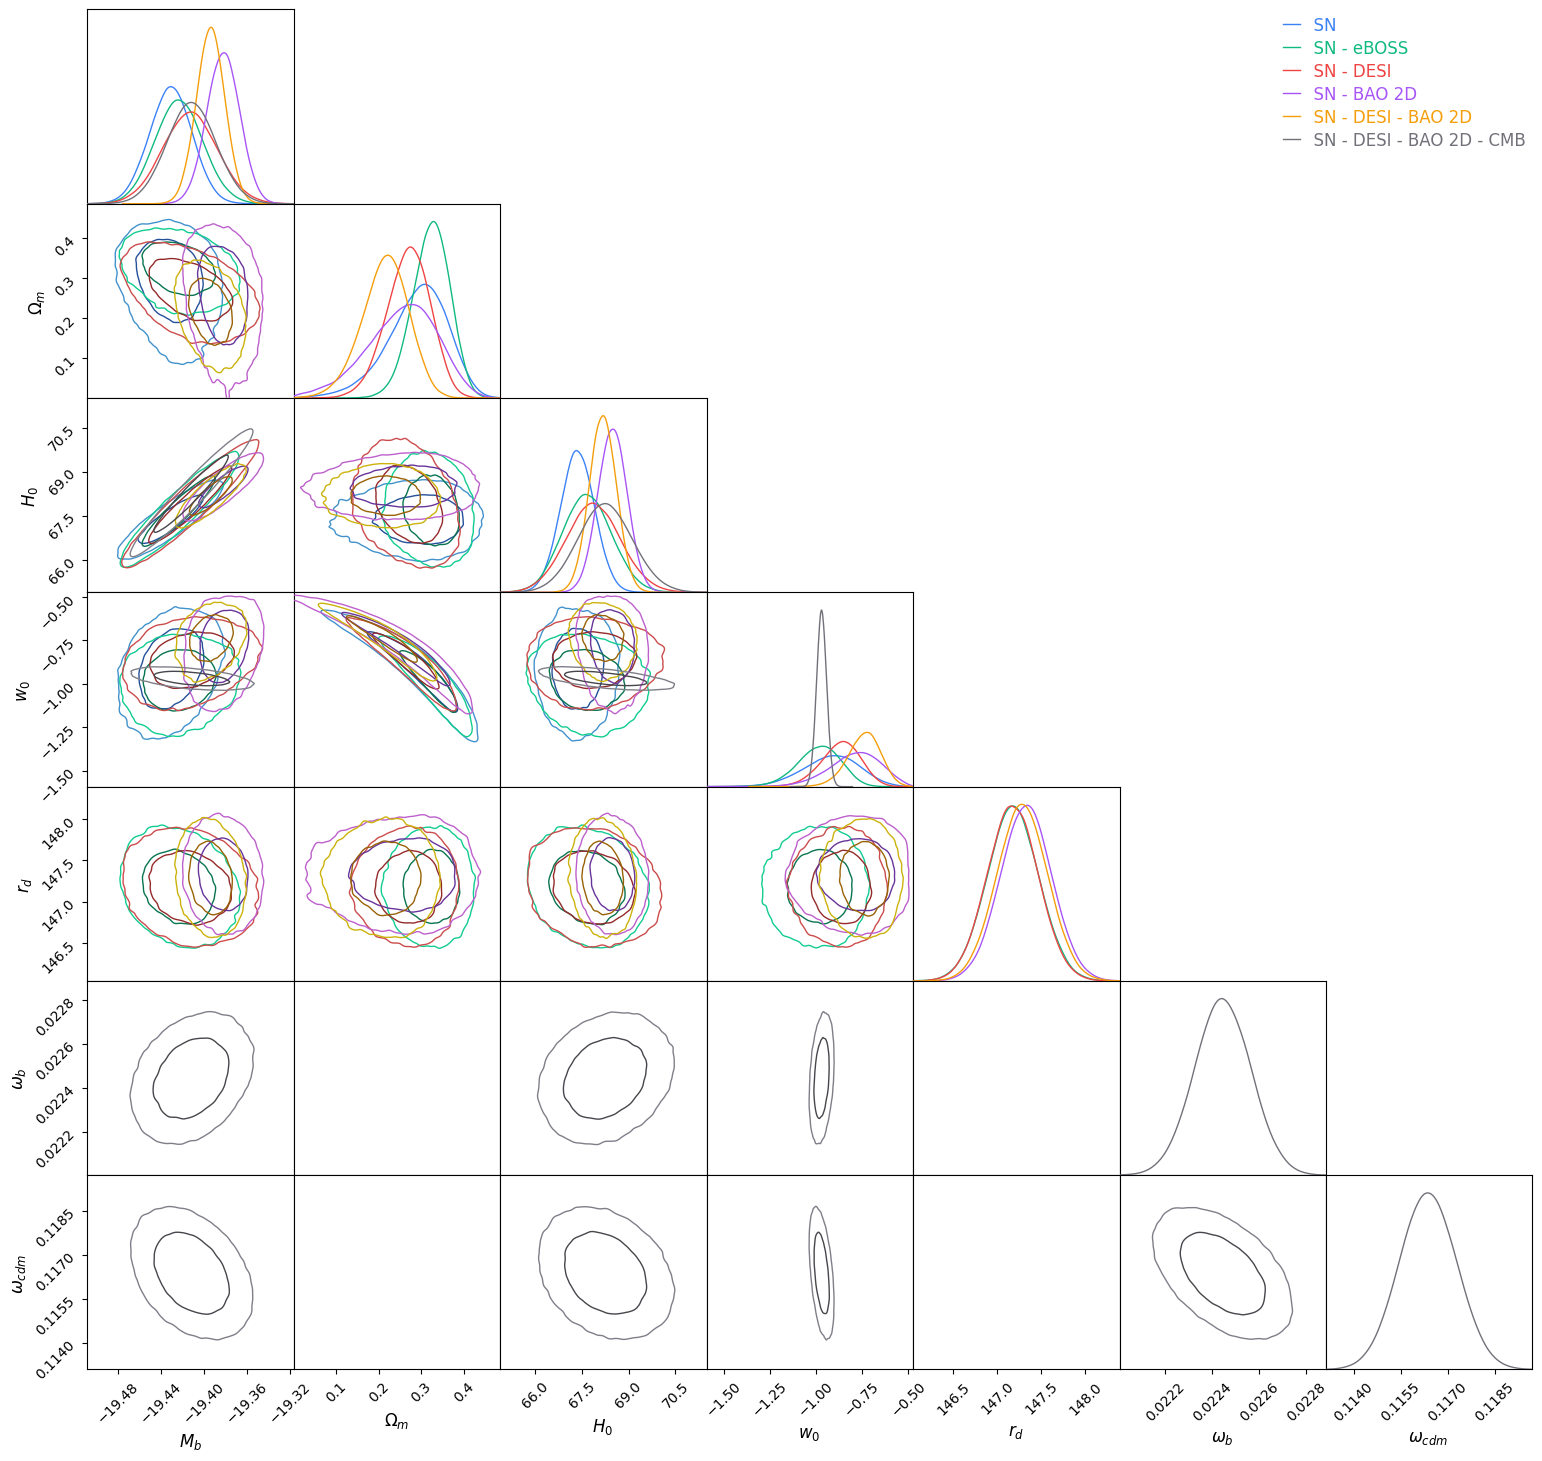

In [ ]:
# burn-in puestos a mano con la información los ficheros de txt
burninPantheon = 179
backend1 = emcee.backends.HDFBackend("cadenaMCMC_XCDM_Pantheon.h5", read_only=True)
flat_samples1 = backend1.get_chain(discard=burninPantheon, flat=True)

burninPantheon_BAO3D_eBOSS = 130
backend2 = emcee.backends.HDFBackend("cadenaMCMC_XCDM_Pantheon_BAO3D_eBOSS.h5", read_only=True)
flat_samples2 = backend2.get_chain(discard=burninPantheon_BAO3D_eBOSS, flat=True)

burnin_BAO3D_eBOSS = 273
backend22 = emcee.backends.HDFBackend("cadenaMCMC_XCDM_BAO3D_eBOSS_rangoAmpliado.h5", read_only=True)
flat_samples22 = backend22.get_chain(discard=burnin_BAO3D_eBOSS, flat=True)

burninPantheon_BAO3D_DESI = 142
backend3 = emcee.backends.HDFBackend("cadenaMCMC_XCDM_Pantheon_BAO3D_DESI.h5", read_only=True)
flat_samples3 = backend3.get_chain(discard=burninPantheon_BAO3D_DESI, flat=True)

burnin_BAO3D_DESI = 729
backend32 = emcee.backends.HDFBackend("cadenaMCMC_XCDM_BAO3D_DESI.h5", read_only=True)
flat_samples32 = backend32.get_chain(discard=burnin_BAO3D_DESI, flat=True)

burninPantheon_BAO2D = 247
backend4 = emcee.backends.HDFBackend("cadenaMCMC_XCDM_Pantheon_BAO2D.h5", read_only=True)
flat_samples4 = backend4.get_chain(discard=burninPantheon_BAO2D, flat=True)

burnin_BAO2D = 375
backend42 = emcee.backends.HDFBackend("cadenaMCMC_XCDM_BAO2D.h5", read_only=True)
flat_samples42 = backend42.get_chain(discard=burnin_BAO2D, flat=True)

burninPantheon_BAO3D_DESI_BAO2D = 149
backend5 = emcee.backends.HDFBackend("cadenaMCMC_XCDM_Pantheon_BAO3D_DESI_BAO2D.h5", read_only=True)
flat_samples5 = backend5.get_chain(discard=burninPantheon_BAO3D_DESI_BAO2D, flat=True)

burnin_BAO3D_DESI_BAO2D = 269
backend52 = emcee.backends.HDFBackend("cadenaMCMC_XCDM_BAO3D_DESI_BAO2D.h5", read_only=True)
flat_samples52 = backend52.get_chain(discard=burnin_BAO3D_DESI_BAO2D, flat=True)

burninPantheon_BAO3D_DESI_BAO2D_CMB = 316
backend6 = emcee.backends.HDFBackend("cadenaMCMC_XCDM_Pantheon_BAO3D_DESI_BAO2D_CMB.h5", read_only=True)
flat_samples6 = backend6.get_chain(discard=burninPantheon_BAO3D_DESI_BAO2D_CMB, flat=True)

burnin_BAO3D_DESI_BAO2D_CMB = 161
backend62 = emcee.backends.HDFBackend("cadenaMCMC_XCDM_BAO3D_DESI_BAO2D_CMB.h5", read_only=True)
flat_samples62 = backend62.get_chain(discard=burnin_BAO3D_DESI_BAO2D_CMB, flat=True)

df1 = pd.DataFrame(flat_samples1, columns=[r"$M_b$", r"$\Omega_m$", r"$H_0$", r"$w_0$"])
df2 = pd.DataFrame(flat_samples2, columns=[r"$M_b$", r"$\Omega_m$", r"$r_d$", r"$H_0$", r"$w_0$"])
df3 = pd.DataFrame(flat_samples3, columns=[r"$M_b$", r"$\Omega_m$", r"$r_d$", r"$H_0$", r"$w_0$"])
df4 = pd.DataFrame(flat_samples4, columns=[r"$M_b$", r"$\Omega_m$", r"$r_d$", r"$H_0$", r"$w_0$"])
df5 = pd.DataFrame(flat_samples5, columns=[r"$M_b$", r"$\Omega_m$", r"$r_d$", r"$H_0$", r"$w_0$"])
df6 = pd.DataFrame(flat_samples6, columns=[r"$M_b$", r"$\omega_b$", r"$\omega_{cdm}$", r"$H_0$", r"$w_0$"]) 

df22 = pd.DataFrame(flat_samples22, columns=[r"$\Omega_m$", r"$r_d$", r"$H_0$", r"$w_0$"])
df32 = pd.DataFrame(flat_samples32, columns=[r"$\Omega_m$", r"$r_d$", r"$H_0$", r"$w_0$"])
df42 = pd.DataFrame(flat_samples42, columns=[r"$\Omega_m$", r"$r_d$", r"$H_0$", r"$w_0$"])
df52 = pd.DataFrame(flat_samples52, columns=[r"$\Omega_m$", r"$r_d$", r"$H_0$", r"$w_0$"])
df62 = pd.DataFrame(flat_samples62, columns=[r"$\omega_b$", r"$\omega_{cdm}$", r"$H_0$", r"$w_0$"]) 

c = ChainConsumer()

c.add_chain(Chain(samples=df1, name="SN")) #, shade_alpha=0.25))
c.add_chain(Chain(samples=df2, name="SN - eBOSS")) #, shade_alpha=0.25))
c.add_chain(Chain(samples=df3, name="SN - DESI"))
c.add_chain(Chain(samples=df4, name="SN - BAO 2D"))
c.add_chain(Chain(samples=df5, name="SN - DESI - BAO 2D"))
c.add_chain(Chain(samples=df6, name="SN - DESI - BAO 2D - CMB"))

fig = c.plotter.plot()

plt.savefig("Comparación_XCDM_SN_BAO3D_eBOSS_DESI_BAO2D.png", dpi=300)

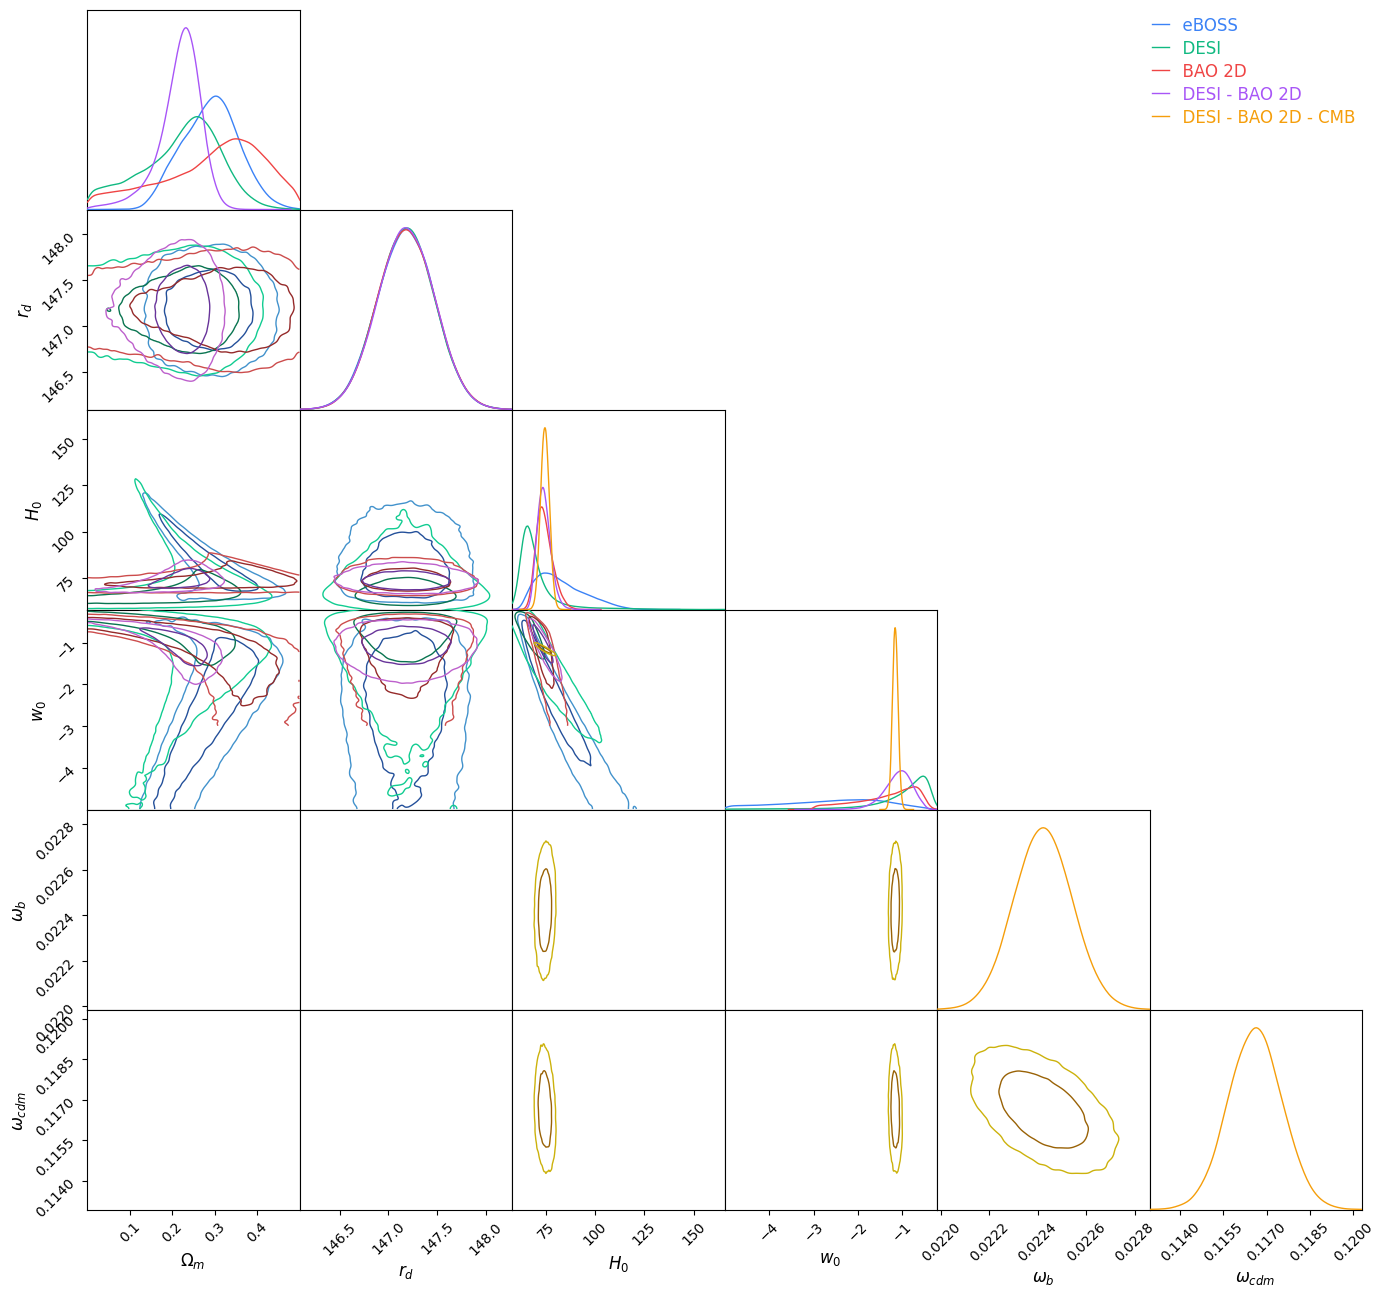

In [ ]:
c = ChainConsumer()

c.add_chain(Chain(samples=df22, name="eBOSS")) #, shade_alpha=0.25))
c.add_chain(Chain(samples=df32, name="DESI"))
c.add_chain(Chain(samples=df42, name="BAO 2D"))
c.add_chain(Chain(samples=df52, name="DESI - BAO 2D"))
c.add_chain(Chain(samples=df62, name="DESI - BAO 2D - CMB"))

fig = c.plotter.plot()

plt.savefig("Comparación_XCDM_BAO3D_eBOSS_DESI_BAO2D.png", dpi=300)

#### Cálculo Ω_m a partir de ωb y ωcdm 

In [4]:
# Con supernovas: sumar las columnas 1 y 2 con factor H0 correcto (Ωm = Ωb + Ωcdm)
Omega_m6 = flat_samples6[:, 1] / (flat_samples6[:, 3] / 100.0)**2 + flat_samples6[:, 2] / (flat_samples6[:, 3] / 100.0)**2 
# Sin supernovas: sumar las columnas 0 y 1 con factor H0 correcto (Ωm = Ωb + Ωcdm)
Omega_m62 = flat_samples62[:, 0] / (flat_samples62[:, 2] / 100.0)**2 + flat_samples62[:, 1] / (flat_samples62[:, 2] / 100.0)**2 

# Crear una nueva cadena con Mb, Ωm, H0 y w0
flat_samples6_om = np.column_stack([
    flat_samples6[:, 0],   # Mb
    Omega_m6,              # Ωm = Ωb + Ωcdm
    flat_samples6[:, 3],   # H0
    flat_samples6[:, 4]    # w0
])

# Crear una nueva cadena con Ωm, H0 y w0
flat_samples62_om = np.column_stack([
    Omega_m62,              # Ωm = Ωb + Ωcdm
    flat_samples62[:, 2],   # H0
    flat_samples62[:, 3]    # w0
])

print(flat_samples6_om.shape)
print(flat_samples62_om.shape)

(779200, 4)
(317560, 3)


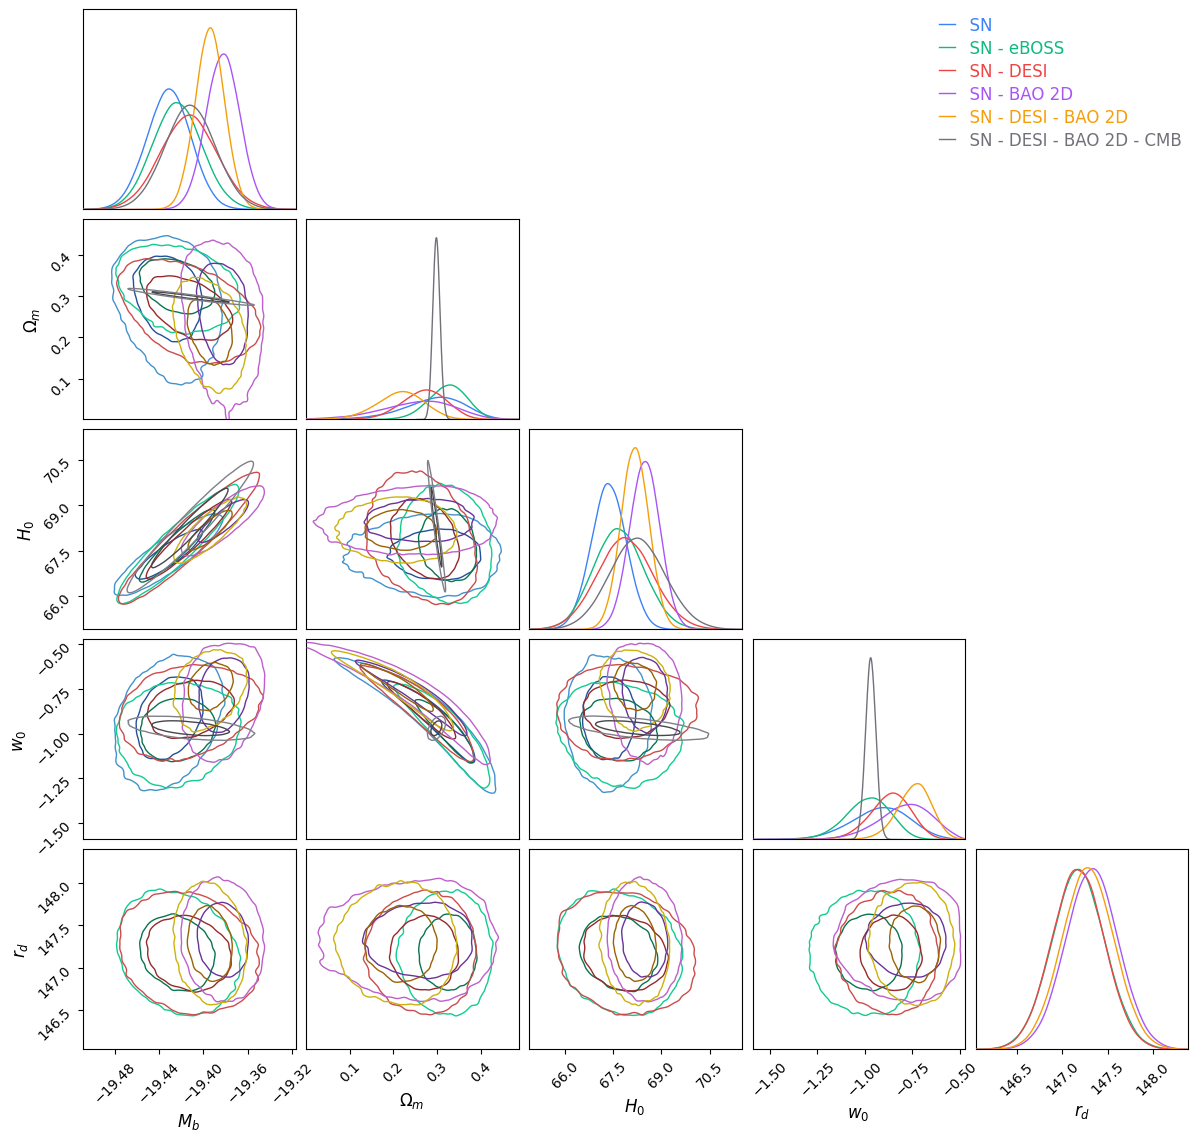

In [ ]:
# Construcción Data Frame para las nuevas cadenas CON SNs
df6_om = pd.DataFrame(flat_samples6_om, columns=[r"$M_b$", r"$\Omega_m$", r"$H_0$", r"$w_0$"])

c = ChainConsumer()

c.add_chain(Chain(samples=df1, name="SN")) #, shade_alpha=0.25))
c.add_chain(Chain(samples=df2, name="SN - eBOSS")) #, shade_alpha=0.25))
c.add_chain(Chain(samples=df3, name="SN - DESI"))
c.add_chain(Chain(samples=df4, name="SN - BAO 2D"))
c.add_chain(Chain(samples=df5, name="SN - DESI - BAO 2D"))
c.add_chain(Chain(samples=df6_om, name="SN - DESI - BAO 2D - CMB"))

fig = c.plotter.plot()

plt.savefig("Comparación_XCDM_SN_BAO3D_eBOSS_DESI_BAO2D_om.png", dpi=300)

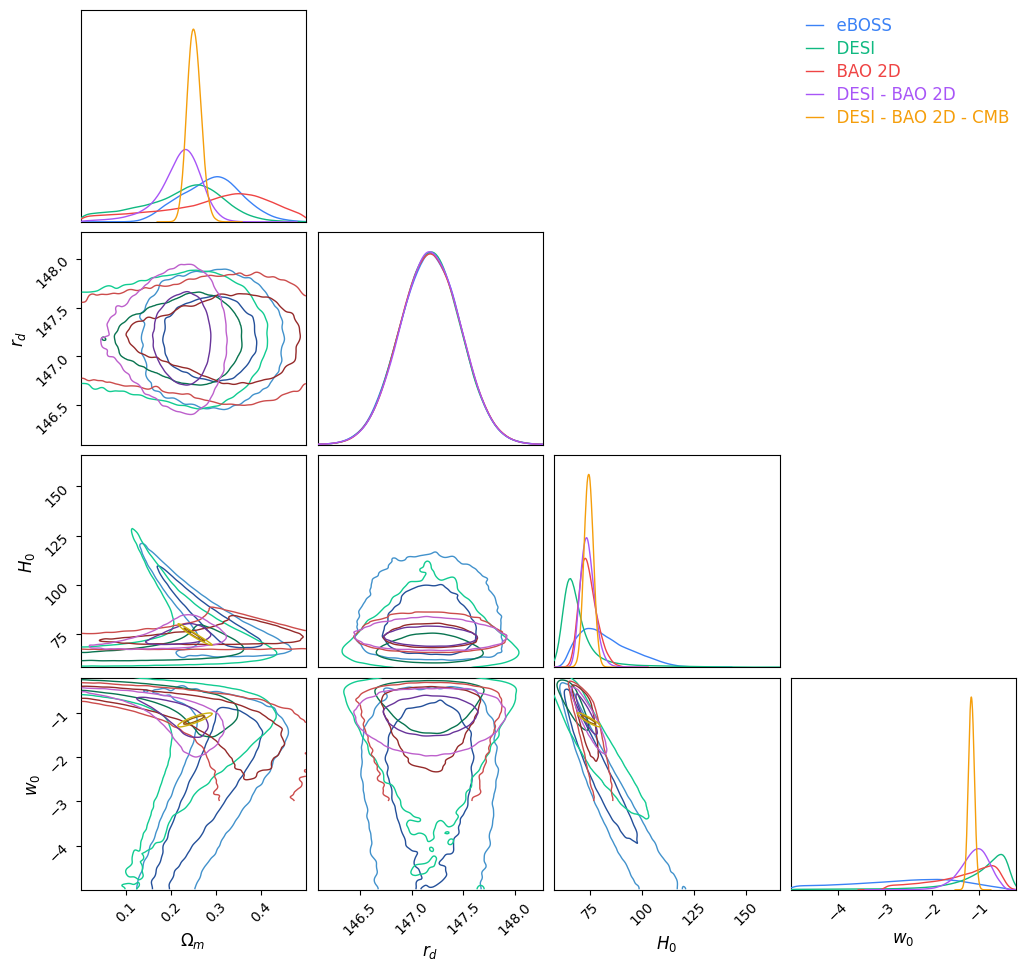

In [ ]:
# Construcción Data Frame para las nuevas cadenas SIN SNs
df62_om = pd.DataFrame(flat_samples62_om, columns=[r"$\Omega_m$", r"$H_0$", r"$w_0$"])

c = ChainConsumer()

c.add_chain(Chain(samples=df22, name="eBOSS")) #, shade_alpha=0.25))
c.add_chain(Chain(samples=df32, name="DESI"))
c.add_chain(Chain(samples=df42, name="BAO 2D"))
c.add_chain(Chain(samples=df52, name="DESI - BAO 2D"))
c.add_chain(Chain(samples=df62_om, name="DESI - BAO 2D - CMB"))

fig = c.plotter.plot()

plt.savefig("Comparación_XCDM_BAO3D_eBOSS_DESI_BAO2D_om.png", dpi=300)

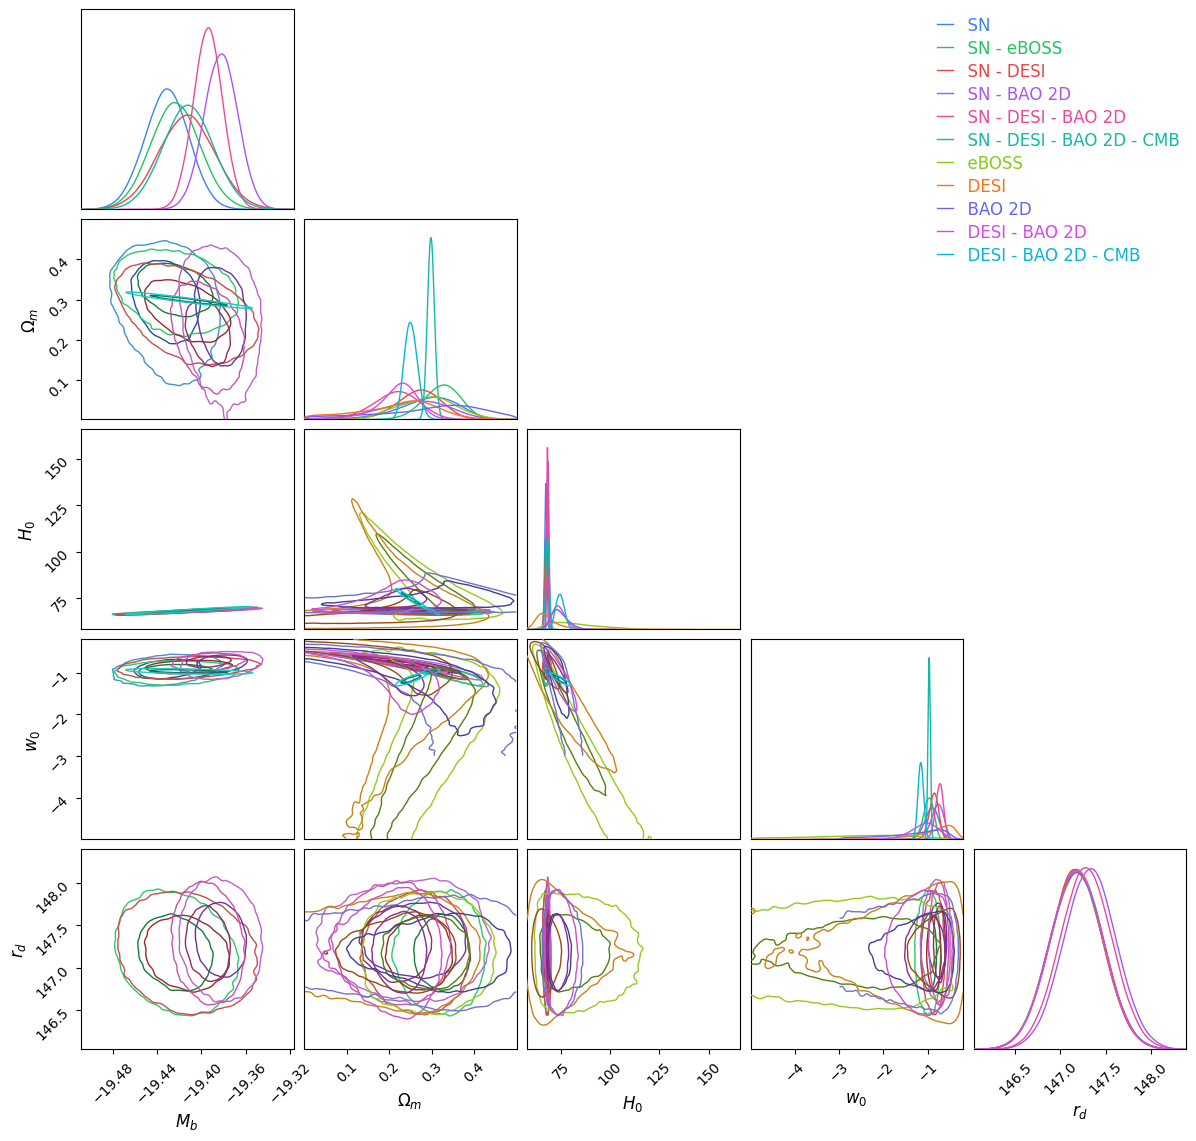

In [ ]:
# Reparto de colores para facilitar visualización y combinaciones comparativas
c = ChainConsumer()

c.add_chain(Chain(samples=df1, name="SN", color="blue")) #, shade_alpha=0.25))
c.add_chain(Chain(samples=df2, name="SN - eBOSS", color="green")) #, shade_alpha=0.25))
c.add_chain(Chain(samples=df3, name="SN - DESI", color="red"))
c.add_chain(Chain(samples=df4, name="SN - BAO 2D", color="purple"))
c.add_chain(Chain(samples=df5, name="SN - DESI - BAO 2D", color="pink"))
c.add_chain(Chain(samples=df6_om, name="SN - DESI - BAO 2D - CMB", color="teal"))

c.add_chain(Chain(samples=df22, name="eBOSS", color="lime")) #, shade_alpha=0.25))
c.add_chain(Chain(samples=df32, name="DESI", color="orange"))
c.add_chain(Chain(samples=df42, name="BAO 2D", color="indigo"))
c.add_chain(Chain(samples=df52, name="DESI - BAO 2D", color="fuchsia"))
c.add_chain(Chain(samples=df62_om, name="DESI - BAO 2D - CMB",color="cyan"))

fig = c.plotter.plot()

#plt.savefig("Comparación_XCDM_TODOS_om.png", dpi=300)

### Gráficas Anexo Memoria

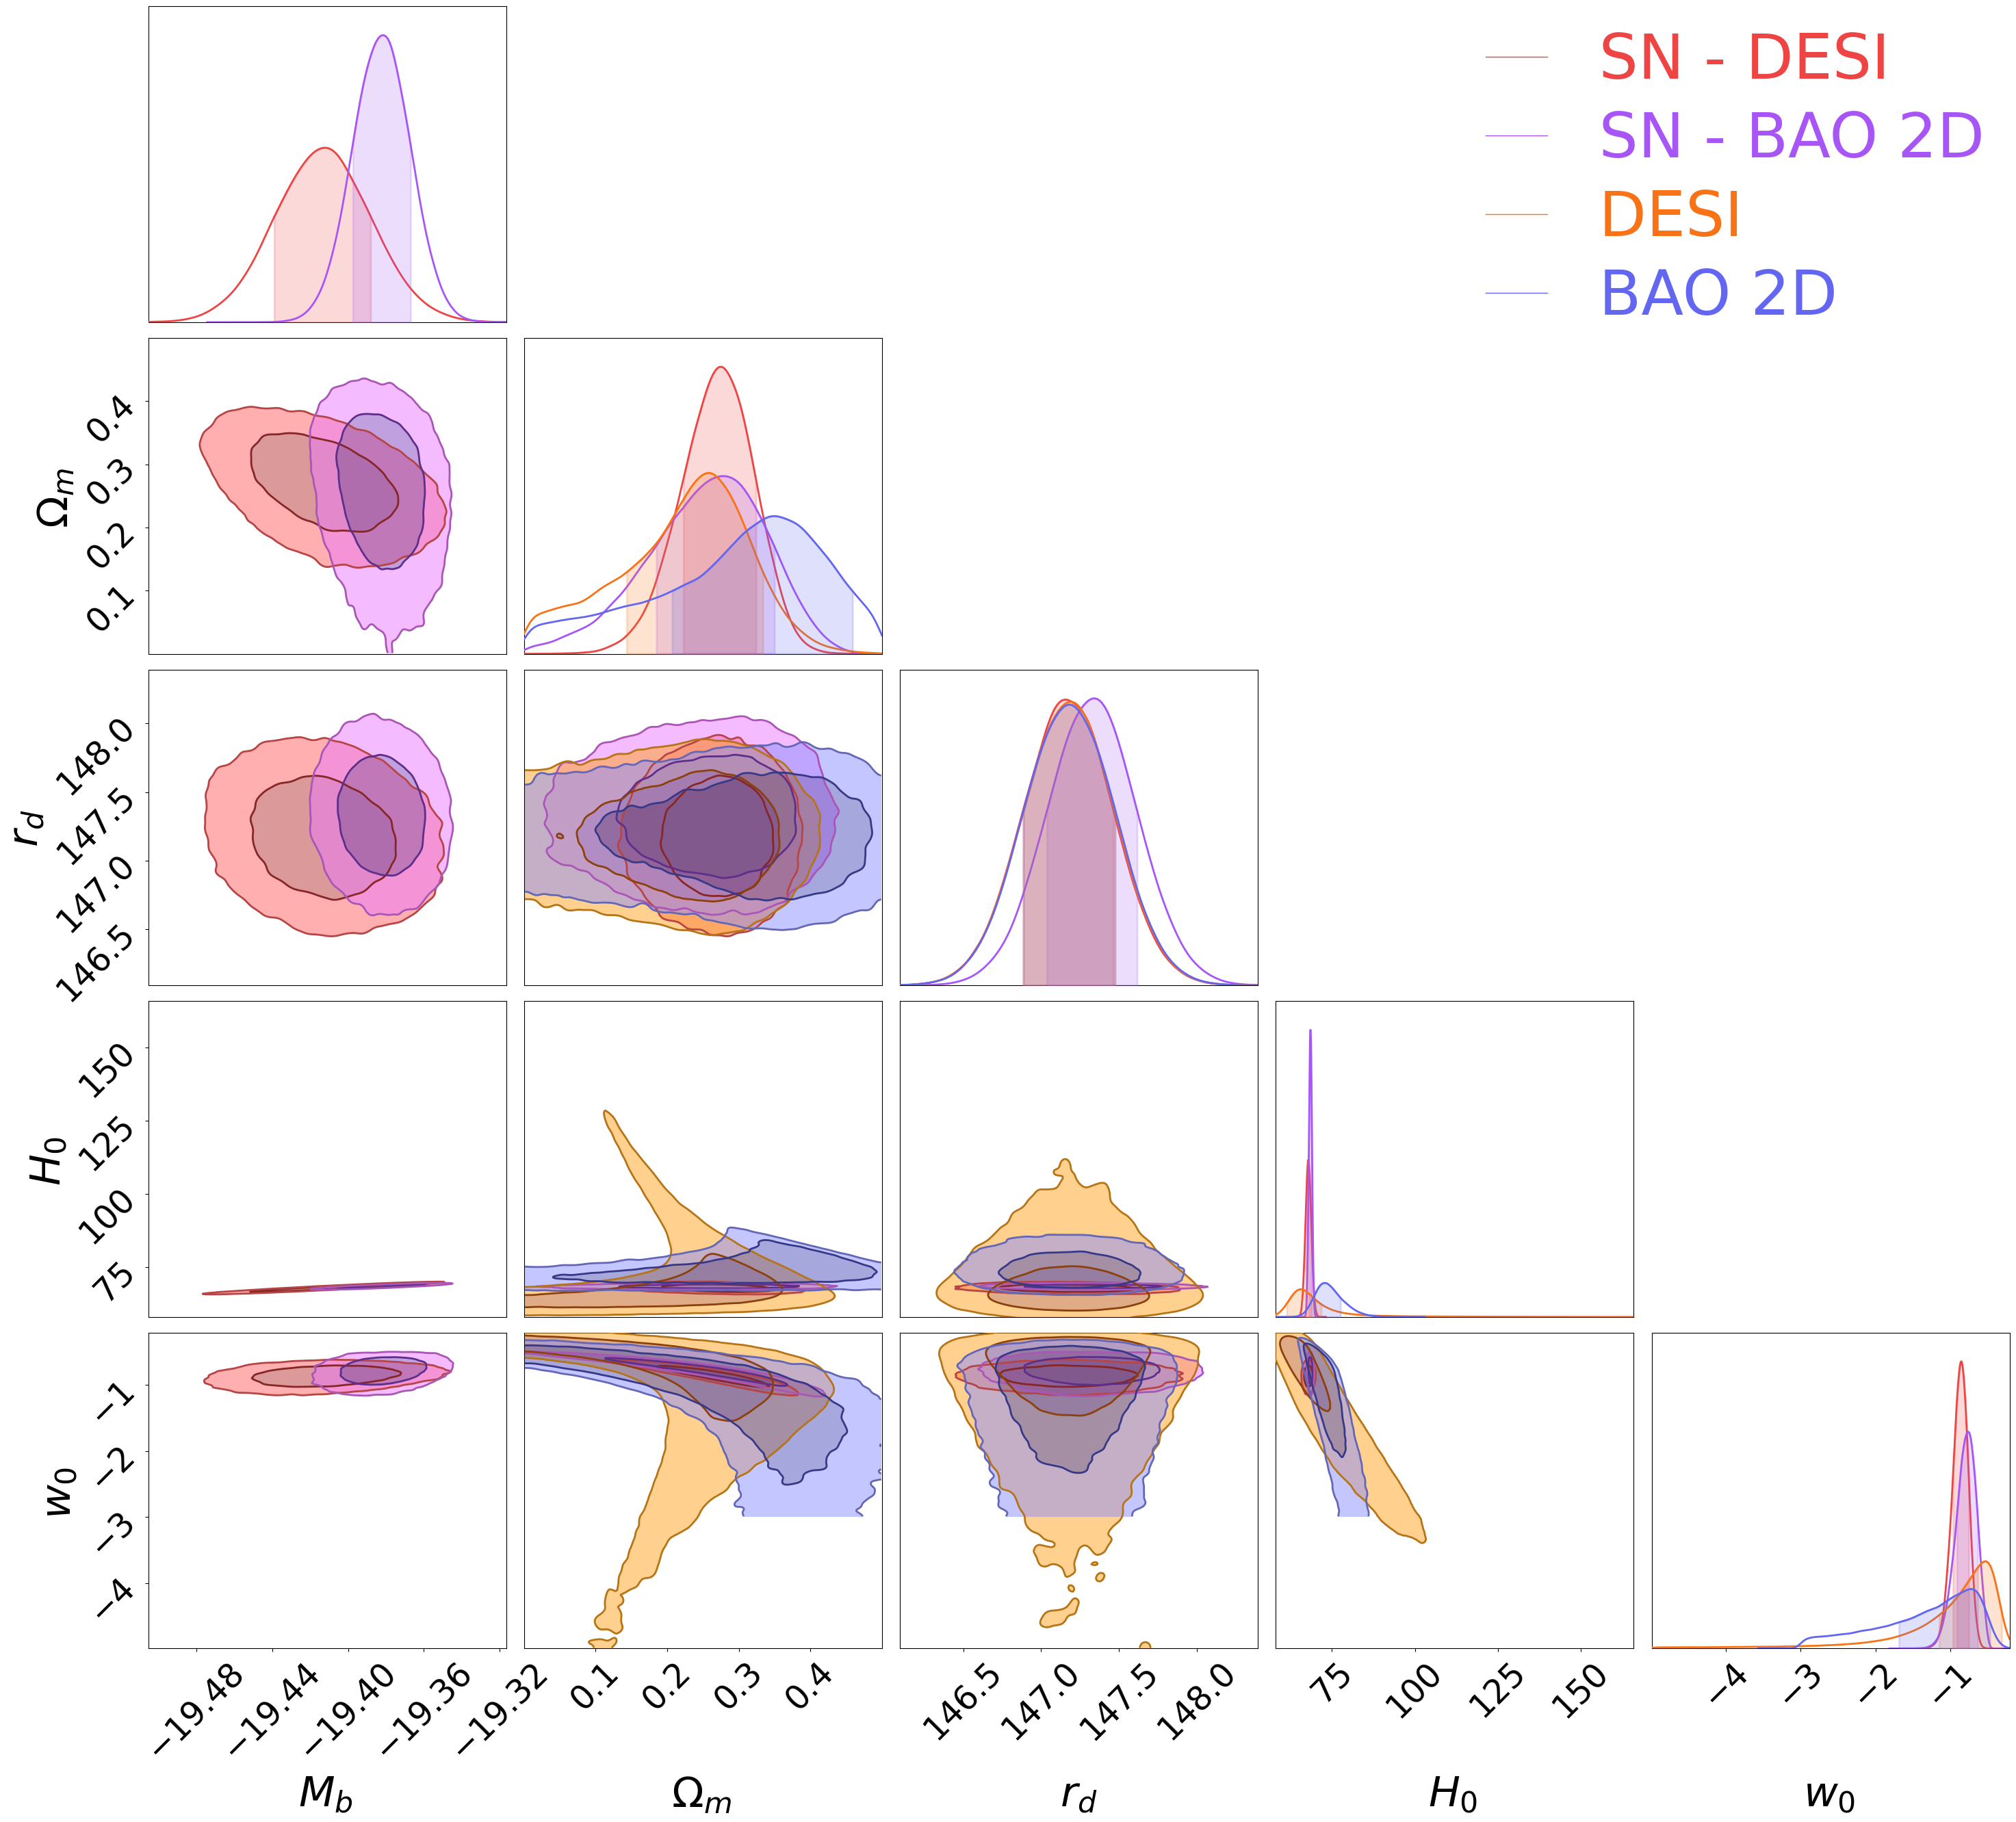

In [8]:
c = ChainConsumer()

#c.add_chain(Chain(samples=df1, name="SN", color="blue")) #, shade_alpha=0.25))
c.add_chain(Chain(samples=df3, name="SN - DESI", color="red"))
c.add_chain(Chain(samples=df4, name="SN - BAO 2D", color="purple"))
c.add_chain(Chain(samples=df32, name="DESI", color="orange"))
c.add_chain(Chain(samples=df42, name="BAO 2D", color="indigo"))

config=PlotConfig(label_font_size=44, tick_font_size=35, legend_kwargs={"fontsize": 65}, linewidths=1.5)
c.set_plot_config(config)

fig = c.plotter.plot(figsize=(32, 30))
fig.subplots_adjust(wspace=0.05, hspace=0.05)

# Aumentar grosor de las líneas de los contornos
for ax in fig.axes:
    
    ax.xaxis.set_label_coords(0.5, -0.4) # Alinea etiquetas de los ejes
    
    for linea in ax.lines:
        linea.set_linewidth(2.0)

    # Aumentar grosor de los bordes de las distribuciones 2D
    for coleccion in ax.collections:
        coleccion.set_linewidth(2.0)

plt.savefig("Comparación_XCDM_Con_vs_Sin_SNs.png", dpi=300)

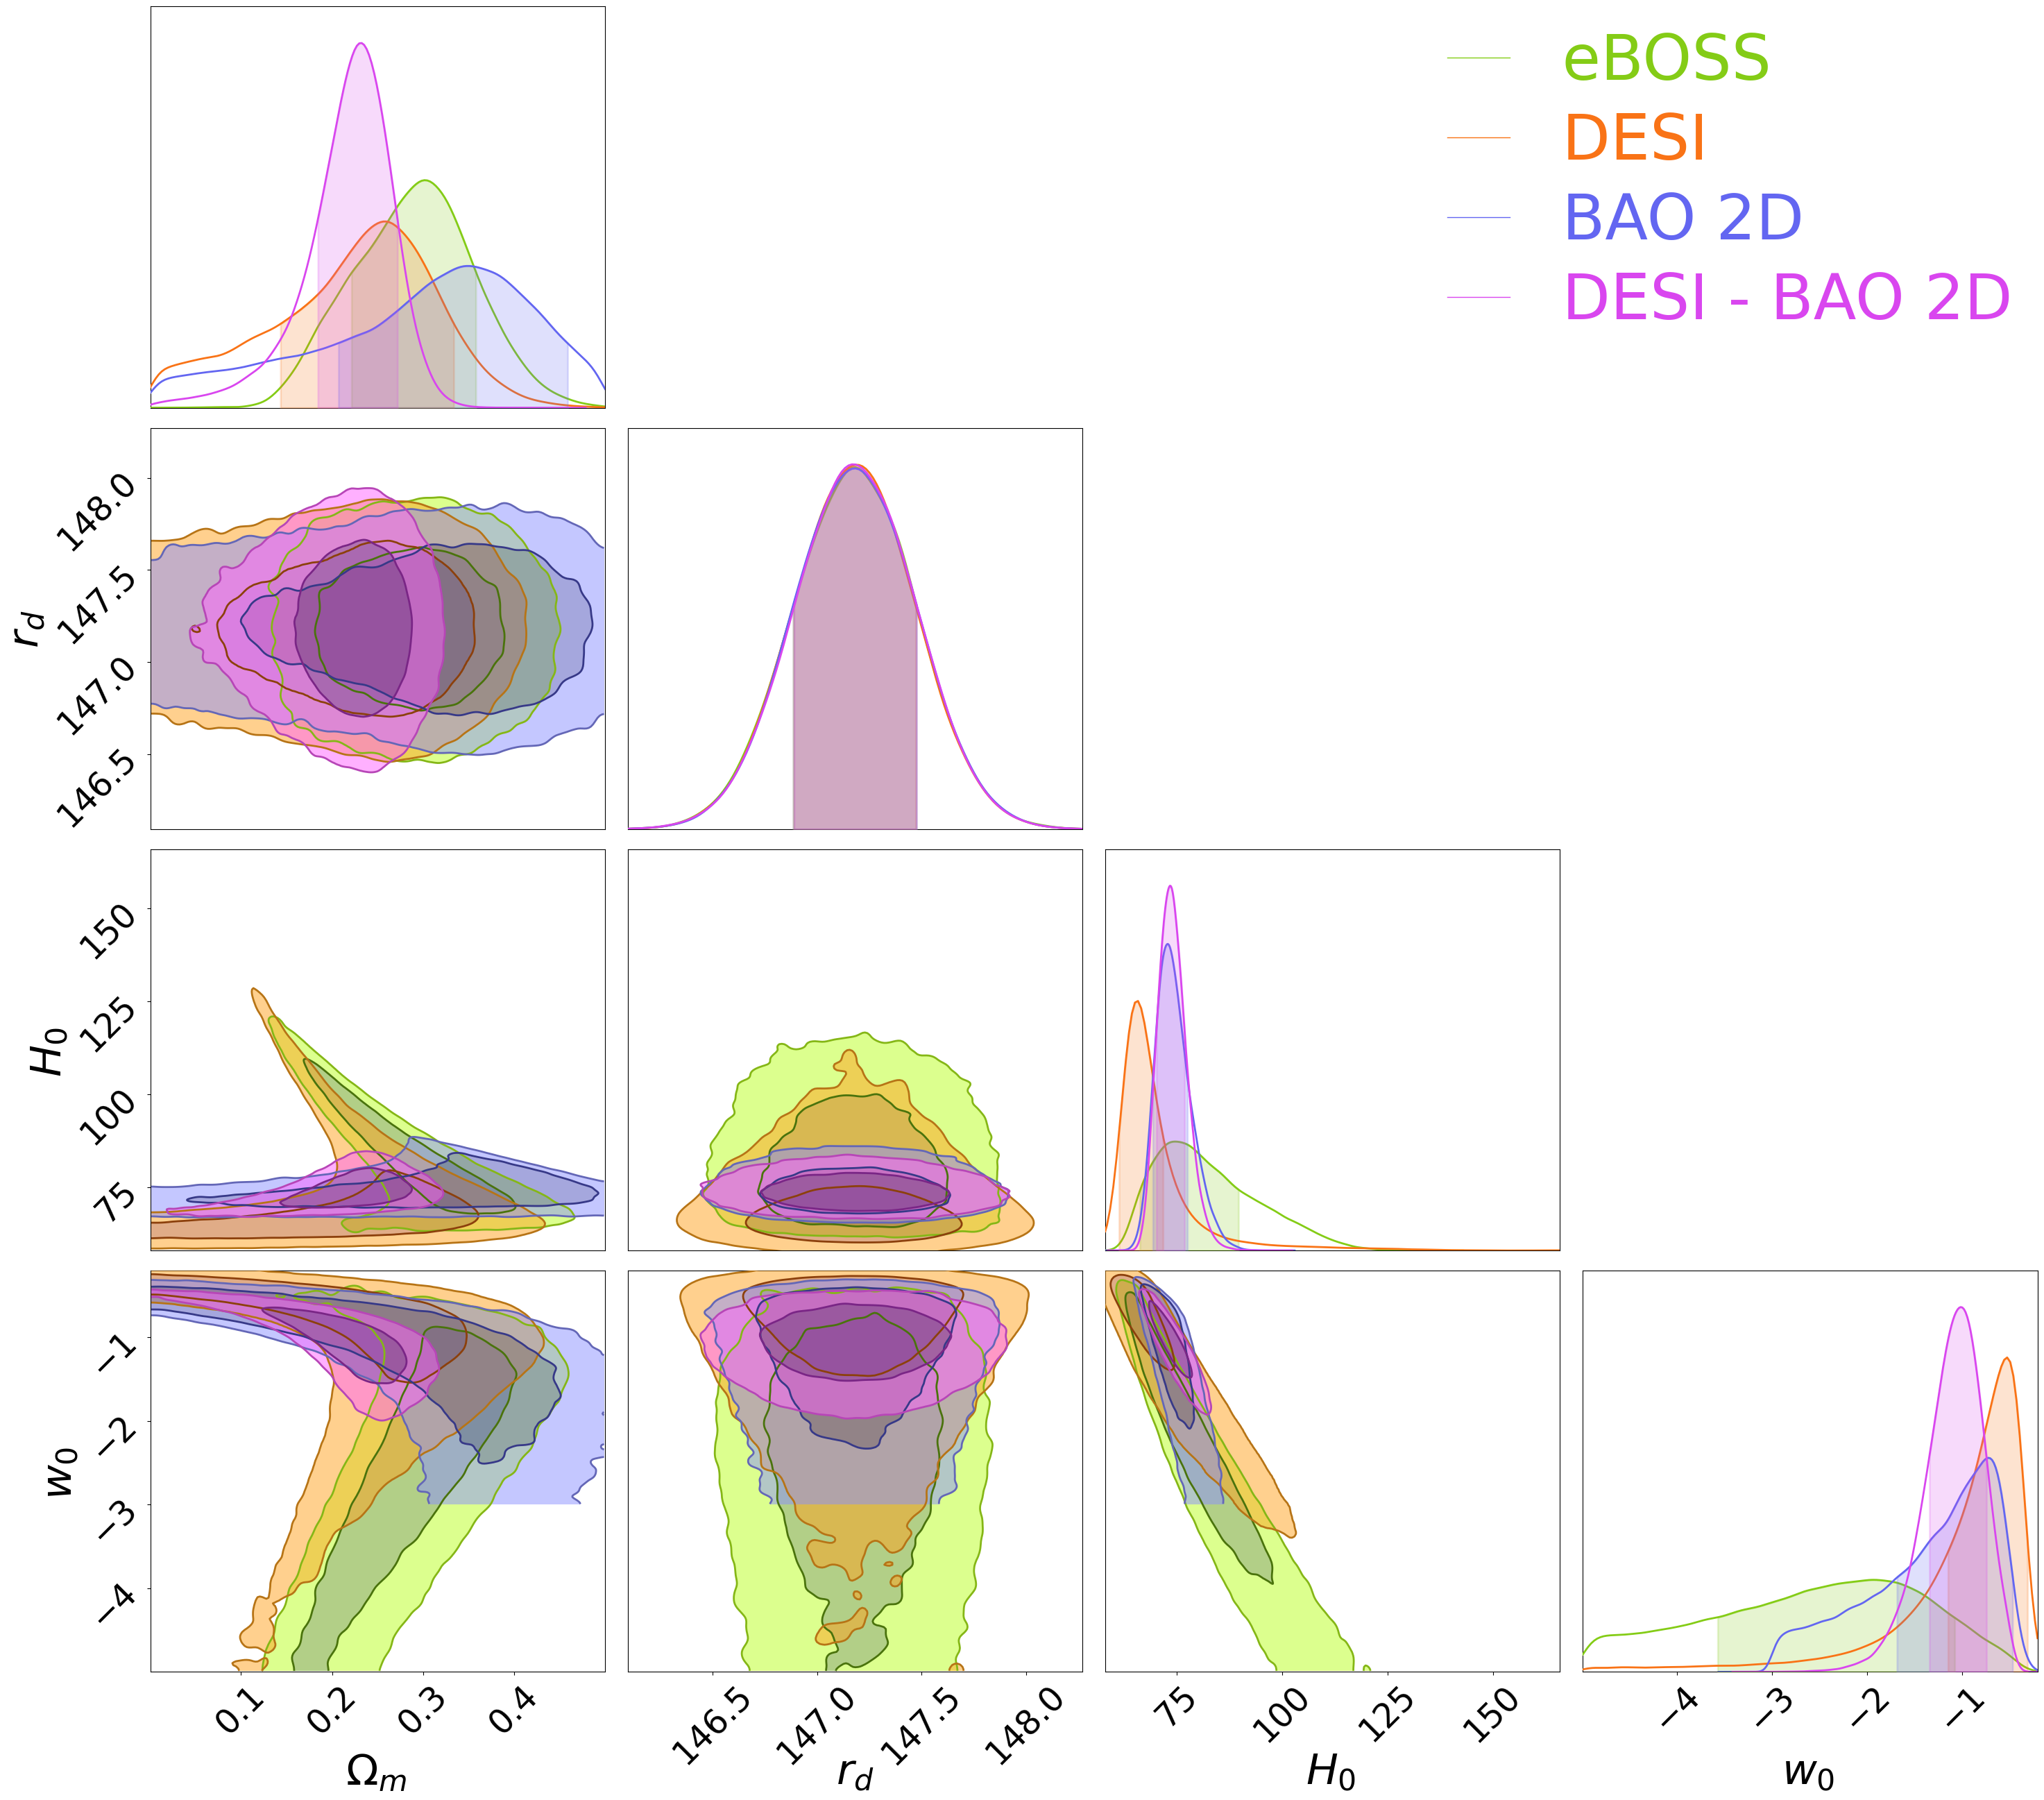

In [9]:
c = ChainConsumer()

#c.add_chain(Chain(samples=df1, name="SN", color="blue")) #, shade_alpha=0.25))
c.add_chain(Chain(samples=df22, name="eBOSS", color="lime")) #, shade_alpha=0.25))
c.add_chain(Chain(samples=df32, name="DESI", color="orange"))
c.add_chain(Chain(samples=df42, name="BAO 2D", color="indigo"))
c.add_chain(Chain(samples=df52, name="DESI - BAO 2D", color="fuchsia"))

config=PlotConfig(label_font_size=44, tick_font_size=35, legend_kwargs={"fontsize": 65}, linewidths=1.5)
c.set_plot_config(config)

fig = c.plotter.plot(figsize=(32, 30))
fig.subplots_adjust(wspace=0.05, hspace=0.05)

# Aumentar grosor de las líneas de los contornos
for ax in fig.axes:
    
    ax.xaxis.set_label_coords(0.5, -0.2) # Alinea etiquetas de los ejes
    
    for linea in ax.lines:
        linea.set_linewidth(2.0)

    # Aumentar grosor de los bordes de las distribuciones 2D
    for coleccion in ax.collections:
        coleccion.set_linewidth(2.0)

plt.savefig("Comparación_XCDM_SinSupernovas.png", dpi=300)

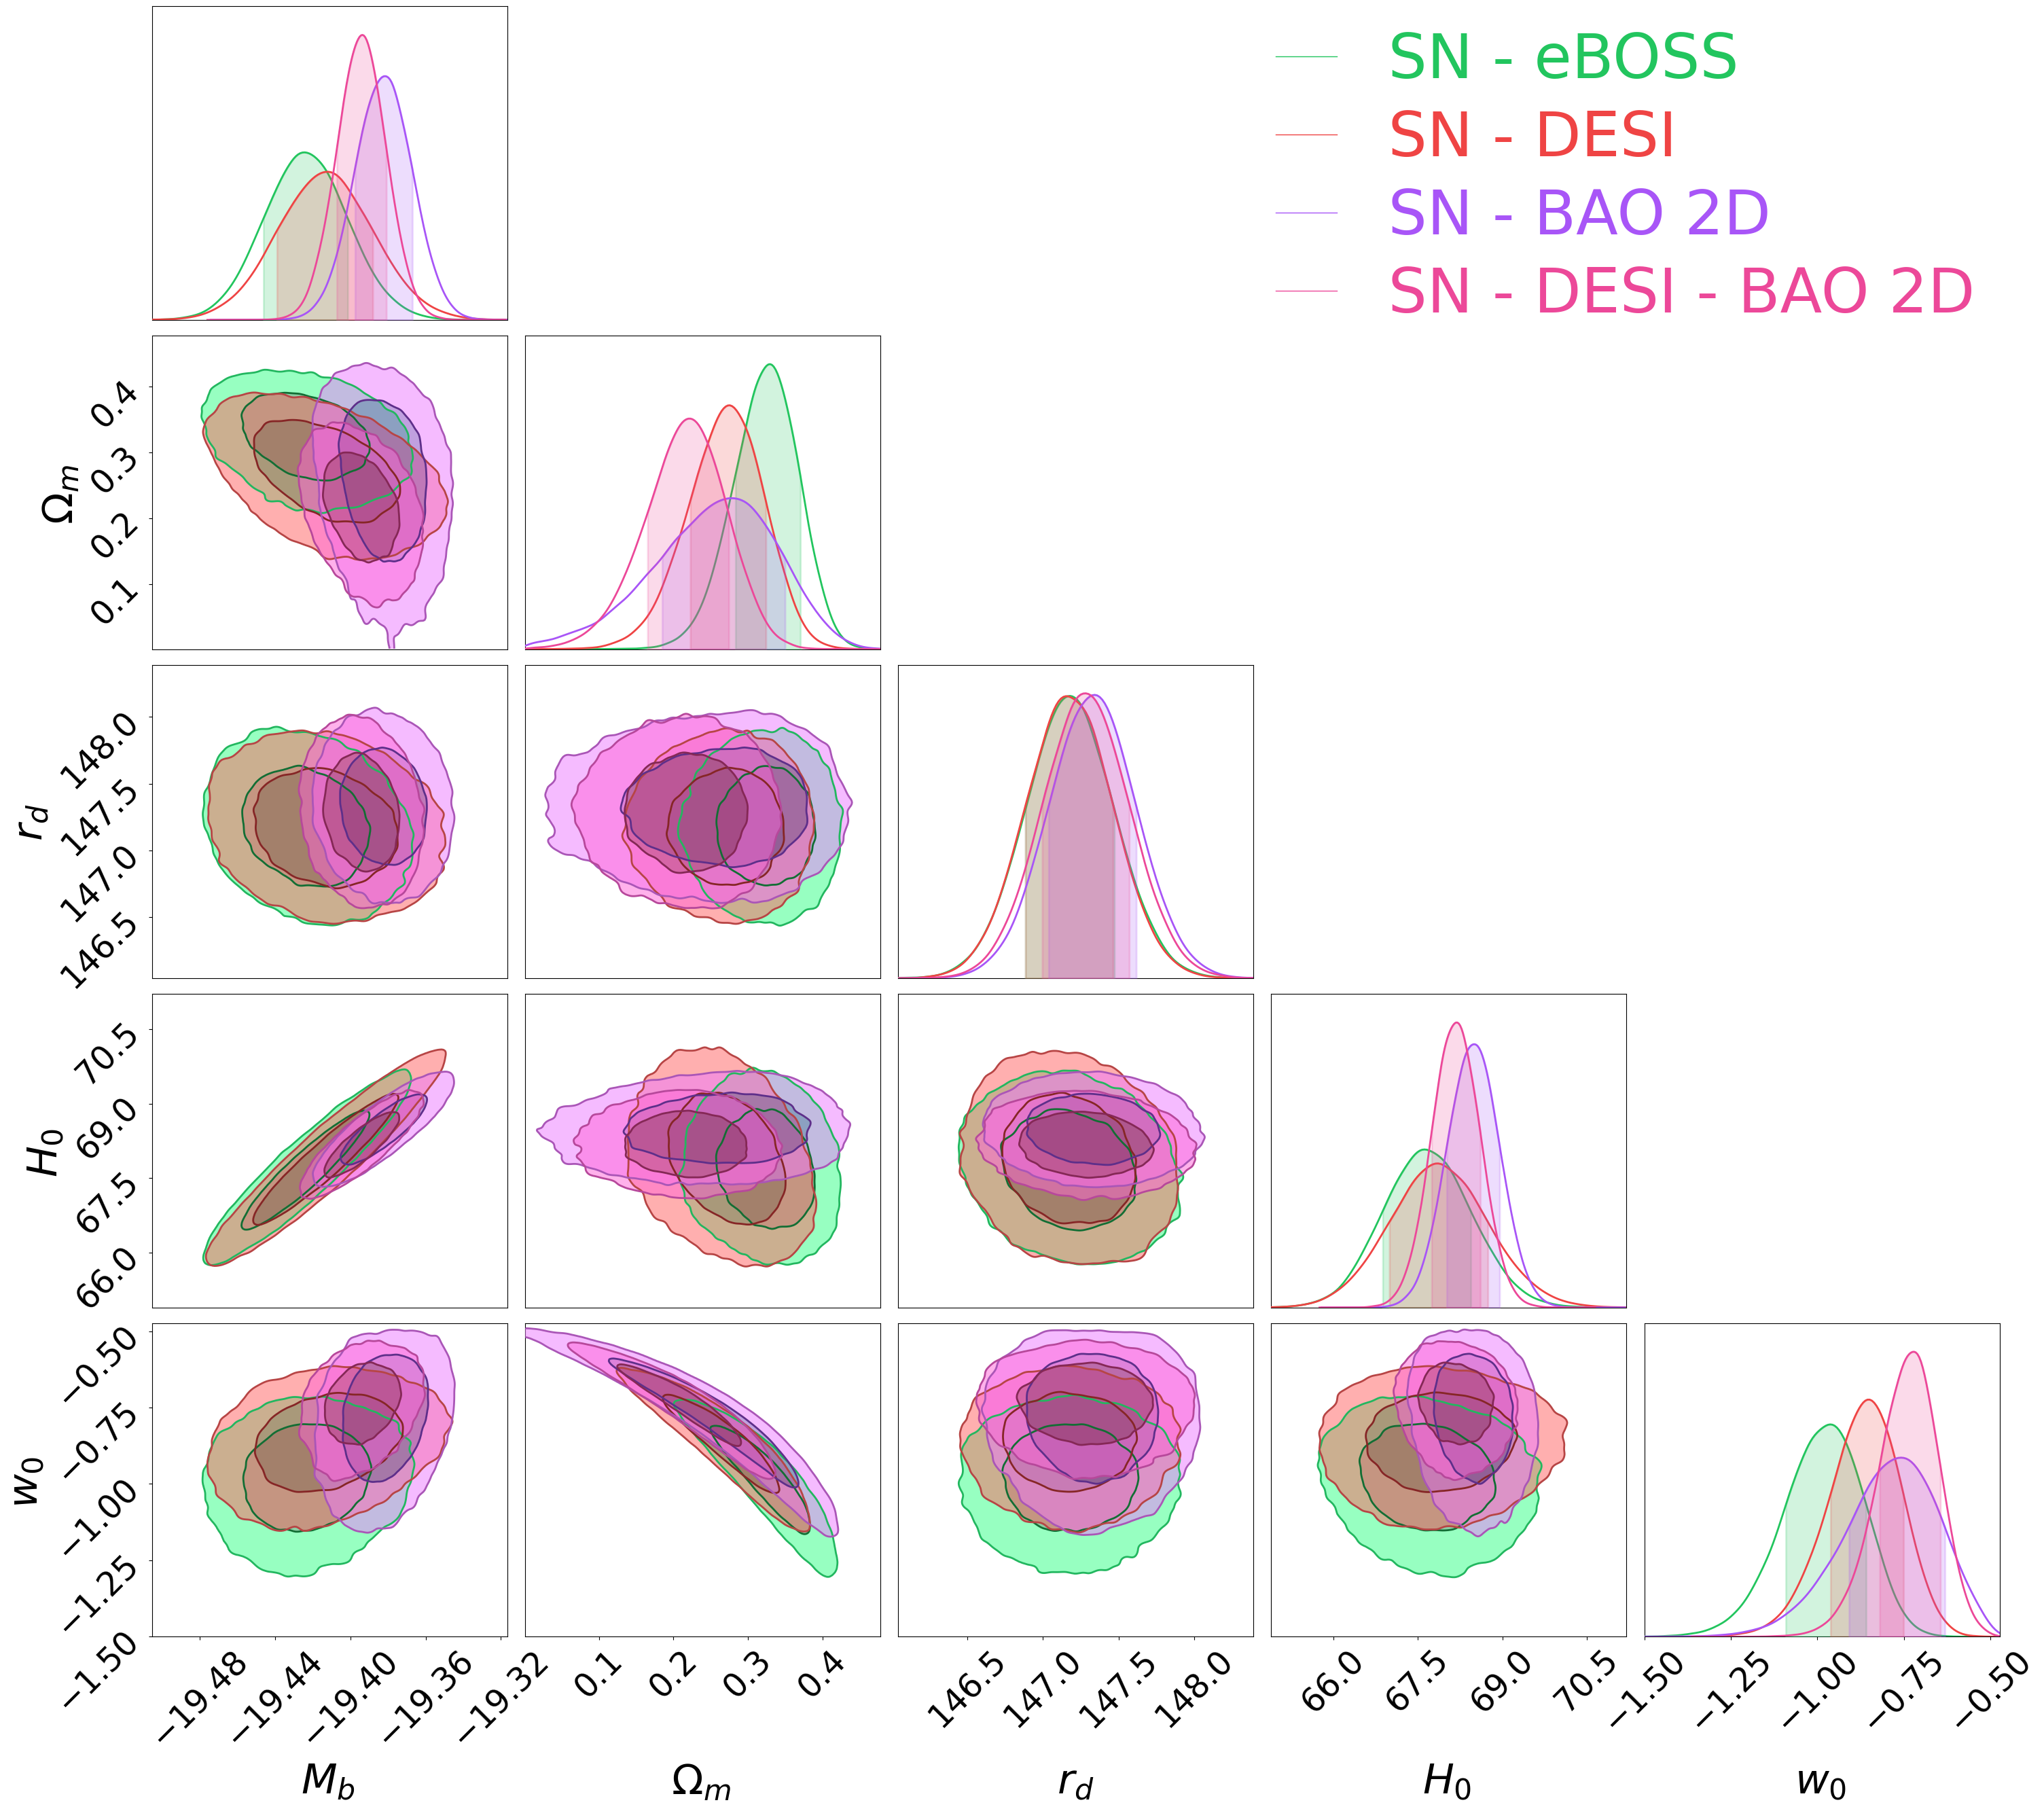

In [10]:
c = ChainConsumer()

c.add_chain(Chain(samples=df2, name="SN - eBOSS", color="green")) #, shade_alpha=0.25))
c.add_chain(Chain(samples=df3, name="SN - DESI", color="red"))
c.add_chain(Chain(samples=df4, name="SN - BAO 2D", color="purple"))
c.add_chain(Chain(samples=df5, name="SN - DESI - BAO 2D", color="pink"))

config=PlotConfig(label_font_size=44, tick_font_size=35, legend_kwargs={"fontsize": 65}, linewidths=1.5)
c.set_plot_config(config)

fig = c.plotter.plot(figsize=(32, 30))
fig.subplots_adjust(wspace=0.05, hspace=0.05)

# Aumentar grosor de las líneas de los contornos
for ax in fig.axes:
    
    ax.xaxis.set_label_coords(0.5, -0.4) # Alinea etiquetas de los ejes
    
    for linea in ax.lines:
        linea.set_linewidth(2.0)

    # Aumentar grosor de los bordes de las distribuciones 2D
    for coleccion in ax.collections:
        coleccion.set_linewidth(2.0)

plt.savefig("Comparación_XCDM_ConSupernovas.png", dpi=300)

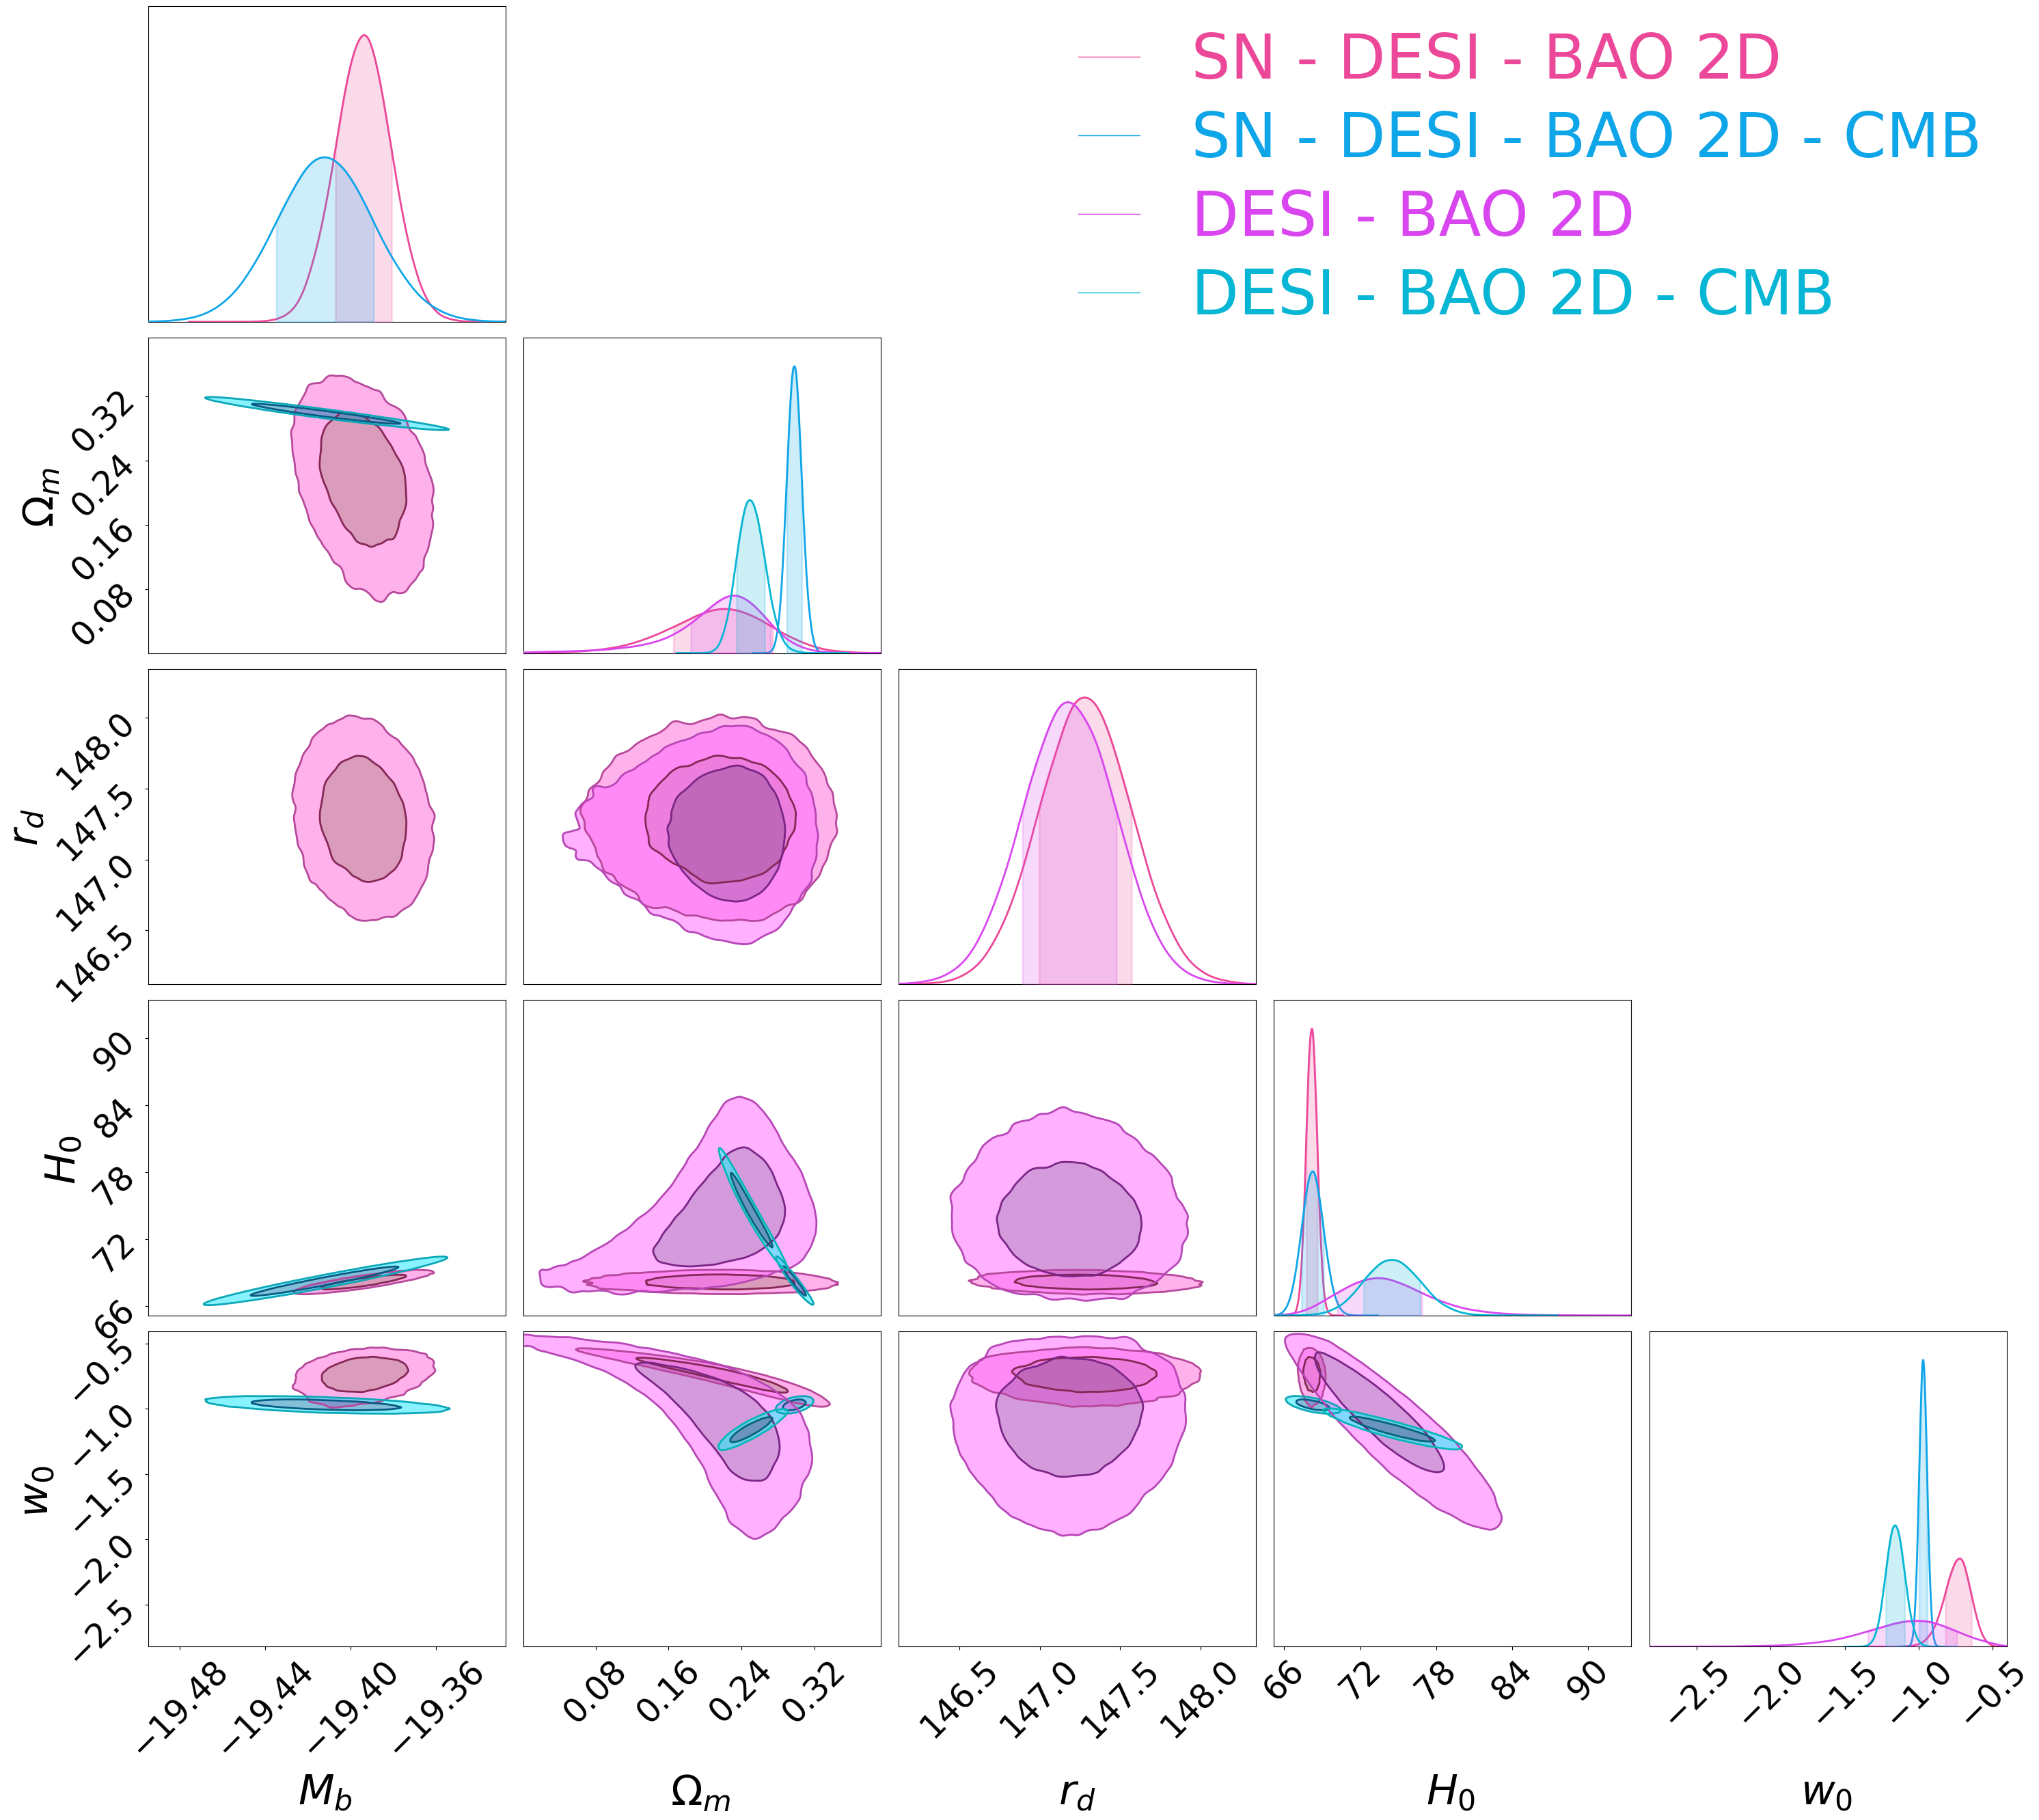

In [11]:
c = ChainConsumer()

#c.add_chain(Chain(samples=df1, name="SN", color="blue")) #, shade_alpha=0.25))
c.add_chain(Chain(samples=df5, name="SN - DESI - BAO 2D", color="pink"))
c.add_chain(Chain(samples=df6_om, name="SN - DESI - BAO 2D - CMB", color="sky"))
c.add_chain(Chain(samples=df52, name="DESI - BAO 2D", color="fuchsia"))
c.add_chain(Chain(samples=df62_om, name="DESI - BAO 2D - CMB",color="cyan"))

config=PlotConfig(label_font_size=44, tick_font_size=35, legend_kwargs={"fontsize": 65}, linewidths=1.5)
c.set_plot_config(config)

fig = c.plotter.plot(figsize=(32, 30))
fig.subplots_adjust(wspace=0.05, hspace=0.05)

# Aumentar grosor de las líneas de los contornos
for ax in fig.axes:
    
    ax.xaxis.set_label_coords(0.5, -0.4) # Alinea etiquetas de los ejes
    
    for linea in ax.lines:
        linea.set_linewidth(2.0)

    # Aumentar grosor de los bordes de las distribuciones 2D
    for coleccion in ax.collections:
        coleccion.set_linewidth(2.0)

plt.savefig("Comparación_XCDM_CMBs.png", dpi=300)